## begin by importing all necessary packages

In [2]:

import sys
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import scipy
from scipy.signal import resample_poly
import re
import json
import glob
from IPython.display import display
import h5py
import shutil
import tdt
from collections import defaultdict
from pathlib import Path
from re import search
from scipy.sparse import csc_matrix, eye, diags
from scipy.sparse.linalg import spsolve
%load_ext autoreload
%autoreload 2

# this is the list from Photometry data preprocessing.ipynb, from the Simpson et al. Neuron primer

from scipy.signal import find_peaks, peak_prominences
from scipy.signal import medfilt, butter, filtfilt
from scipy.stats import linregress
from scipy.optimize import curve_fit, minimize
from scipy import stats

#set default plot properties (this also from Simpson et al., 2024)
plt.rcParams['figure.figsize'] = [10, 8] # Make default figure size larger.
plt.rcParams['axes.xmargin'] = 0          # Make default margin on x axis zero.
plt.rcParams['axes.labelsize'] = 12     #Set default axes label size 
plt.rcParams['axes.titlesize']=15
plt.rcParams['axes.titleweight']='heavy'
plt.rcParams['ytick.labelsize']= 10
plt.rcParams['xtick.labelsize']= 10
plt.rcParams['legend.fontsize']=12
plt.rcParams['legend.markerscale']=2
plt.style.use('dark_background')
%matplotlib inline
    



## choose the animals of interest

In [3]:
#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-

# define the set of recordings to draw from, sorted already into a folder

source_folder = r"D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test"
#subcoh = r"D:\ACW\photometry\pilot_recordings_extracted\ACW_coh5_IT_f1_tdt"
#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-



#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-



# define the IDs for the individual animals


BOX2_rat = 'ACW_coh5_IT_' 
BOX3_rat = 'ACW_coh6_IT_f9'
BOX4_rat = 'ACW_coh5_IT_'
BOX5_rat = 'ACW_coh5_IT_'



subcoh_rats = {
    'BOX2_rat': str(BOX2_rat),
    'BOX3_rat': str(BOX3_rat),
    'BOX4_rat': str(BOX4_rat),
    'BOX5_rat': str(BOX5_rat)
}



#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-

# list of the recording sessions for this sub-cohort

files = os.listdir(source_folder)

# Exclude any file that begins with "processed_"
files = [x for x in files if not x.startswith("processed_")]
files = [x for x in files if not x.startswith("multiday_processed_")]

# trim file names to blocknames
files = {x.replace('_streams_info.feather','') for x in files}
files = {x.replace('_streams_data.feather','') for x in files}
files = {x.replace('_epocs_info.feather','')   for x in files}
files = {x.replace('_epocs_data.feather','')   for x in files}
files = {x.replace('_info.feather','')         for x in files}
files = {x.replace('_streams_preproc_downsamp.feather','')         for x in files}
files = {x.replace('_streams_preproc.feather','')         for x in files}
files = {x.replace('_GCaMP_465_dFF_epocs.feather','')         for x in files}
files = {x.replace('_GCaMP_465_epocs.feather','')         for x in files}
files = {x.replace('_epoc_ts_and_indices.feather','')         for x in files}

files = {x.replace(f'_{BOX2_rat}','')         for x in files}
files = {x.replace(f'_{BOX3_rat}','')         for x in files}
files = {x.replace(f'_{BOX4_rat}','')         for x in files}
files = {x.replace(f'_{BOX5_rat}','')         for x in files}


print(f'these are the {len(files)} session IDs for rats in source folder: {source_folder}')
print(files)

print()

print(f'these are the rats in this source_folder:')
subcoh_rats




these are the 4 session IDs for rats in sub-cohort: D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test
{'ACW_coh6d_102226_0003', 'ACW_coh6d_102226_0004', 'ACW_coh6d_102226_0002', 'ACW_coh6d_102226_0001'}

these are the rats in this sub-cohort:


{'BOX2_rat': 'ACW_coh5_IT_',
 'BOX3_rat': 'ACW_coh6_IT_f9',
 'BOX4_rat': 'ACW_coh5_IT_',
 'BOX5_rat': 'ACW_coh5_IT_'}

## Doric recordings: choose the session ID and load feather files

{'BOX2': 'ACW_coh5_IT_', 'BOX3': 'ACW_coh6_IT_f9', 'BOX4': 'ACW_coh5_IT_', 'BOX5': 'ACW_coh5_IT_'}
The rat to be further examined is: ACW_coh6_IT_f9
['ACW_coh6d_102226_0001', 'ACW_coh6d_102226_0002', 'ACW_coh6d_102226_0003', 'ACW_coh6d_102226_0004']
Sessions to be processed:
   ACW_coh6d_102226_0001
   ACW_coh6d_102226_0002
   ACW_coh6d_102226_0003
   ACW_coh6d_102226_0004

--- Starting processing ---


#-#-#-#-#--#--#--#--#--#--#---#---#---#---#---#----#----#----#----#----#--------------------------------------#

Processing ACW_coh6d_102226_0001



,blockname,nickname,channel_raw,channel_name,fs,device_start_time,device_stop_time
0,ACW_coh6d_102226_0001,ACW_coh6_IT_f10,Headstage01LockIn01,Headstage01_470nm,100,09:45:34.968,09:57:17.200
1,ACW_coh6d_102226_0001,ACW_coh6_IT_f10,Headstage01LockIn02,Headstage01_415nm,100,09:45:34.968,09:57:17.200
2,ACW_coh6d_102226_0001,ACW_coh6_IT_f9,Headstage02LockIn01,Headstage02_470nm,100,09:45:34.968,09:57:17.200
3,ACW_coh6d_102226_0001,ACW_coh6_IT_f9,Headstage02LockIn02,Headstage02_415nm,100,09:45:34.968,09:57:17.200


,blockname,channel_raw,channel_name,nickname,time,raw_au
0,ACW_coh6d_102226_0001,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.324466,0.056842
1,ACW_coh6d_102226_0001,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.334466,0.059831
2,ACW_coh6d_102226_0001,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.344466,0.063413
3,ACW_coh6d_102226_0001,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.354466,0.065748
4,ACW_coh6d_102226_0001,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.364466,0.066573
...,...,...,...,...,...,...
280427,ACW_coh6d_102226_0001,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,702.209454,0.057778
280428,ACW_coh6d_102226_0001,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,702.219454,0.057649
280429,ACW_coh6d_102226_0001,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,702.229454,0.057681
280430,ACW_coh6d_102226_0001,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,702.239454,0.057835


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,97.973
1,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.123
2,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.503
3,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.733
4,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,100.173
5,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,100.533
6,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,101.333
7,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,103.193
8,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,103.353
9,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,104.373


Moved ACW_coh6d_102226_0001_streams_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0001_streams_info.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0001_epocs_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
File not found, skipping: ACW_coh6d_102226_0001_epocs_info.feather
🔍 Detected format: Doric
⚠️ Missing expected channels for BOX2 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX4 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX5 (ACW_coh5_IT_). Skipping.

✅ Found photometry data for boxes: BOX3



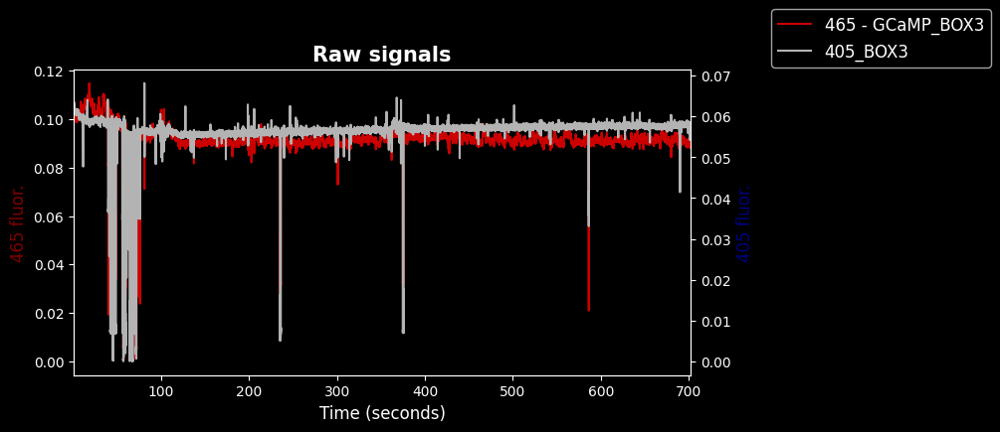

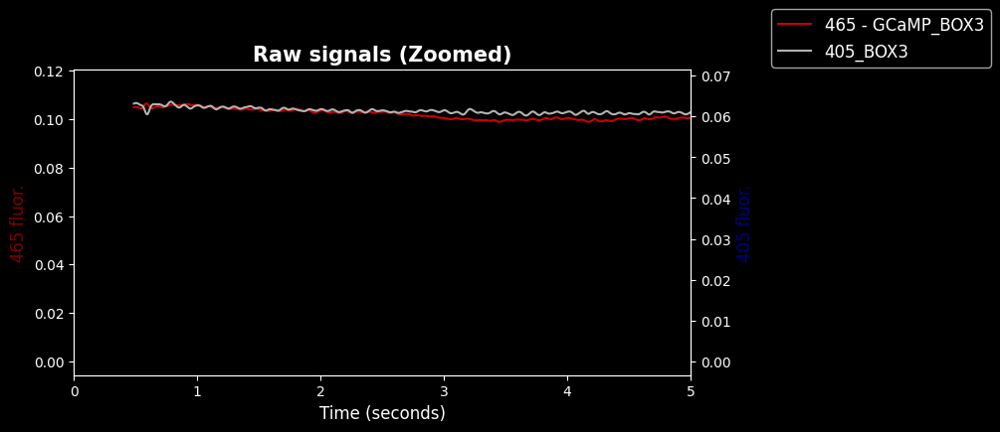

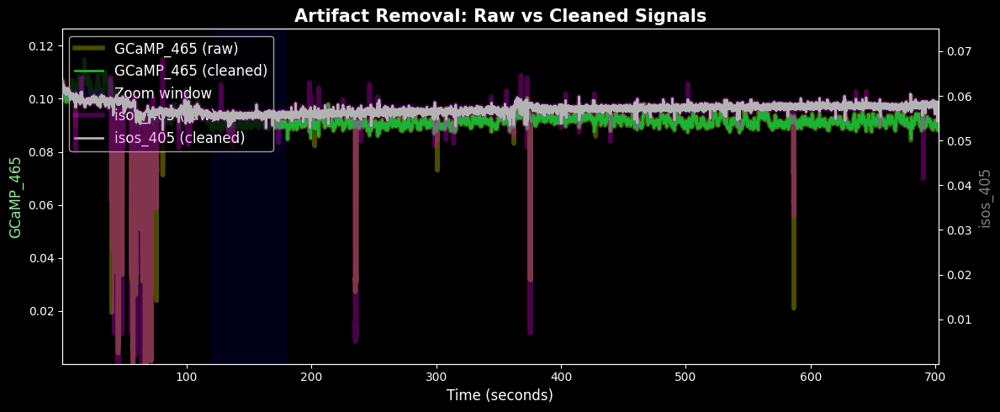

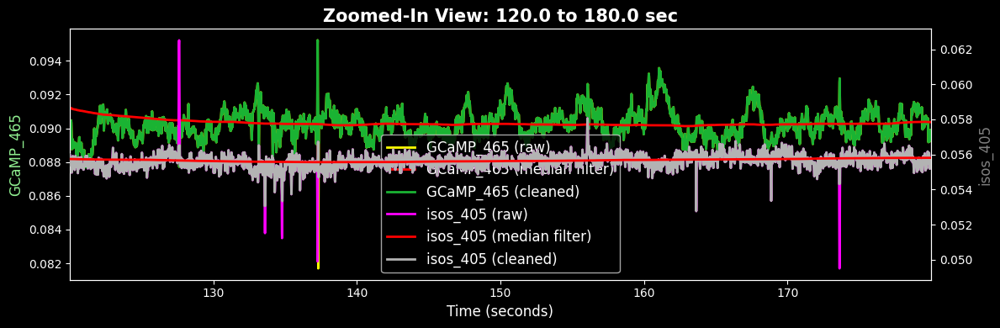

20.0


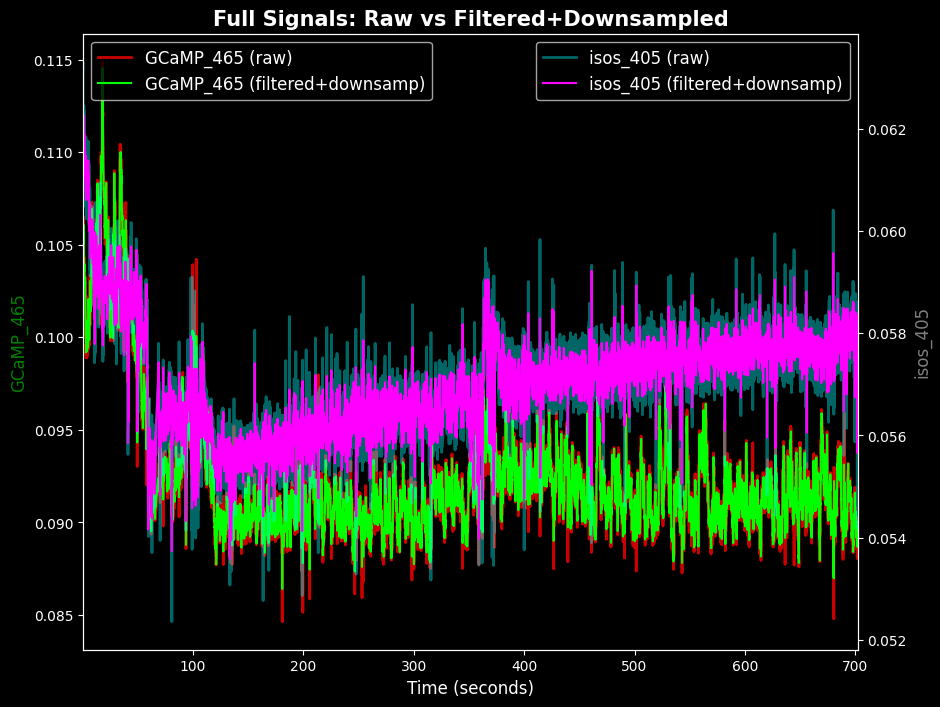

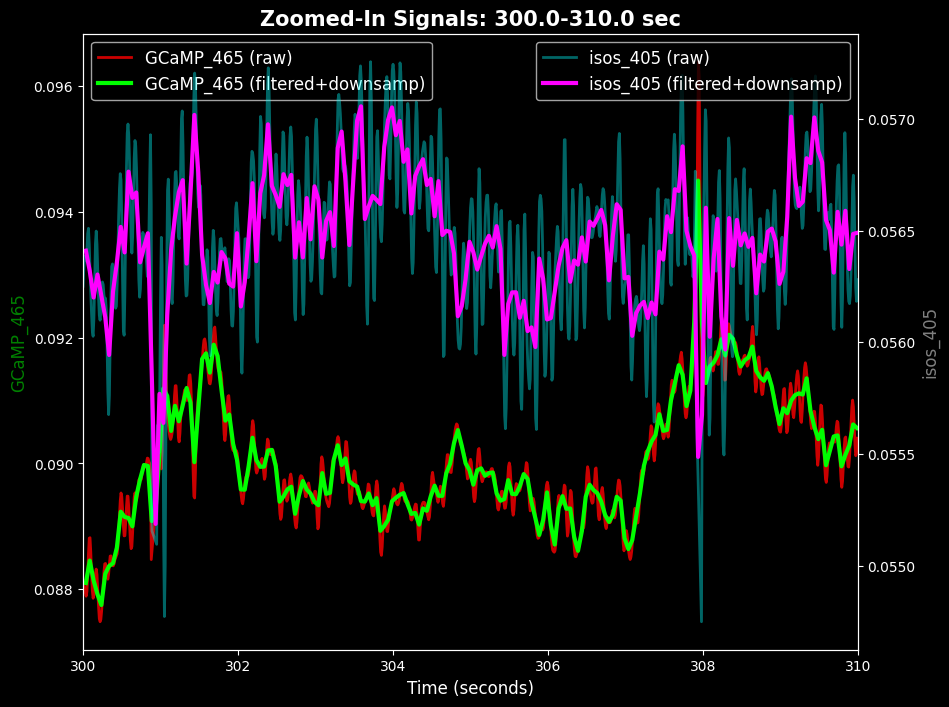

isos_405 length: 70060
isos_405_downsamp length: 14036
GCaMP_465 length: 70060
GCaMP_465_downsamp length: 14036
ts_all length: 70060
ts_downsamp length: 14036

the duration of the stream data is 702.2382535400005 seconds, aka 11.703970892333341 mins


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,97.973
1,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.123
2,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.503
3,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,99.733
4,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,100.173
5,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,100.533
6,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,101.333
7,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,103.193
8,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,103.353
9,ACW_coh6d_102226_0001,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,104.373


detected data format: Doric

📋 Unique D## codes found: ['D13' 'D14' 'D15' 'D16' 'D29' 'D30' 'D31' 'D32']
📌 dropsec_code reflects beginning of the Med Associates program
📌 dropsec_code reflects onset of drug availability

⏱ dropsec code D13 corresponds to timepoints: [97.973]

✅ Using dropsec = 97.973 seconds from epoc data.
the downsampled sampling rate is 20.0 Hz

discard the first 97.973 seconds, data points from 0 to 1959

keep a duration of 15 minutes
including to end of stream: data points 750 to 14036

- - - - - initial vector lengths - - - - -

len(isos_405_filt_downsamp): 14036
len(ts_downsamp): 14036

start index: 750
end index: 14036

Trimmed duration: 664.25 sec (~11.07 min) (requested 15 min, pre_buffer 0s, post_buffer 0s)

Plotting TRANSITION segment (1 min before → 1 min after available period, total 17.0 min) ...


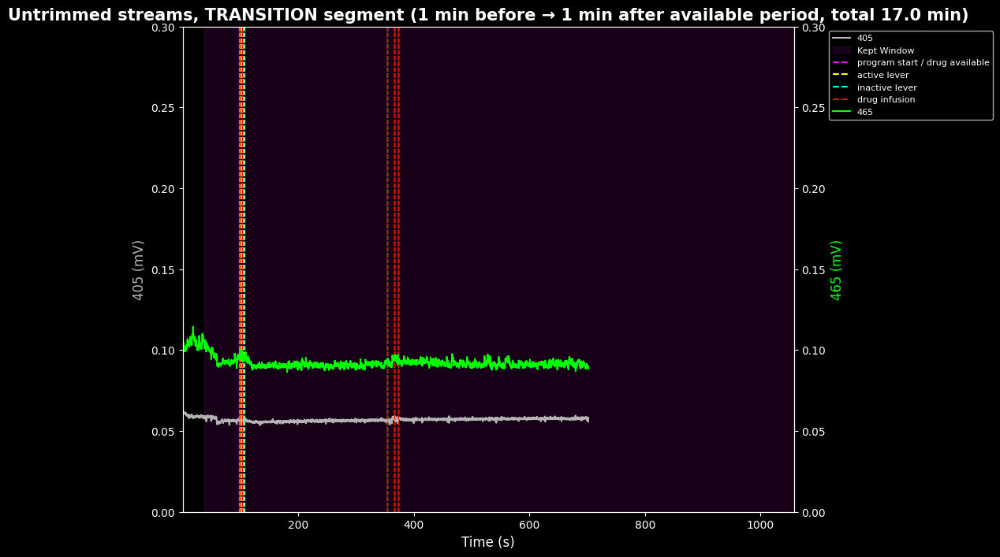

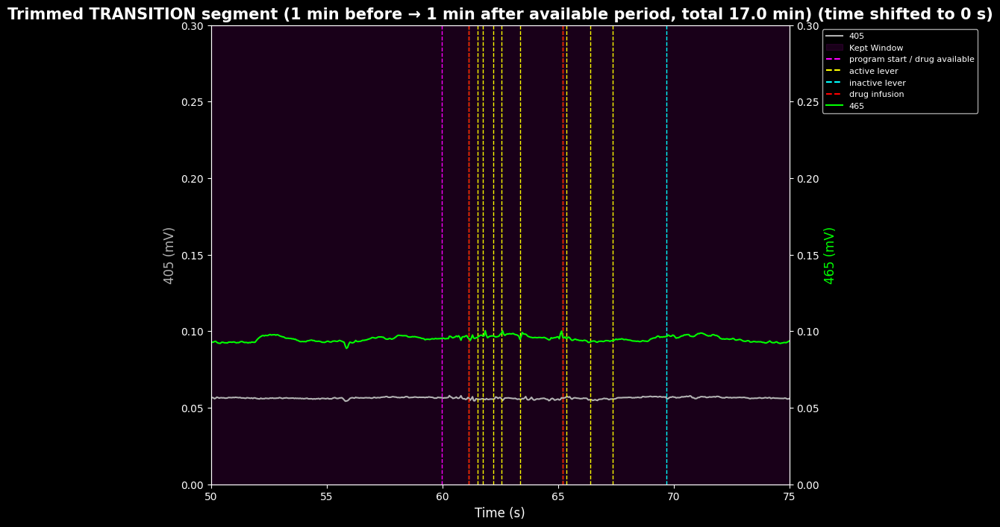

examining 15 minutes of the epoc data
the dropsec code is D13
the start code is 0
dropsec is equal to 97.973
Intermittent access self-admin epoc_ts_and_indices:


ACW_coh6_IT_f9 epoc timestamps,epoc_ts,epoc_indices,data,event
0,60.000,1199,D13,drug available
1,61.150,1222,D14,active lever
2,61.530,1230,D14,active lever
3,61.760,1235,D14,active lever
4,62.200,1243,D14,active lever
5,62.560,1251,D14,active lever
6,63.360,1267,D14,active lever
7,65.220,1304,D14,active lever
8,65.380,1307,D14,active lever
9,66.400,1327,D14,active lever


Detected 5 artifact segments.


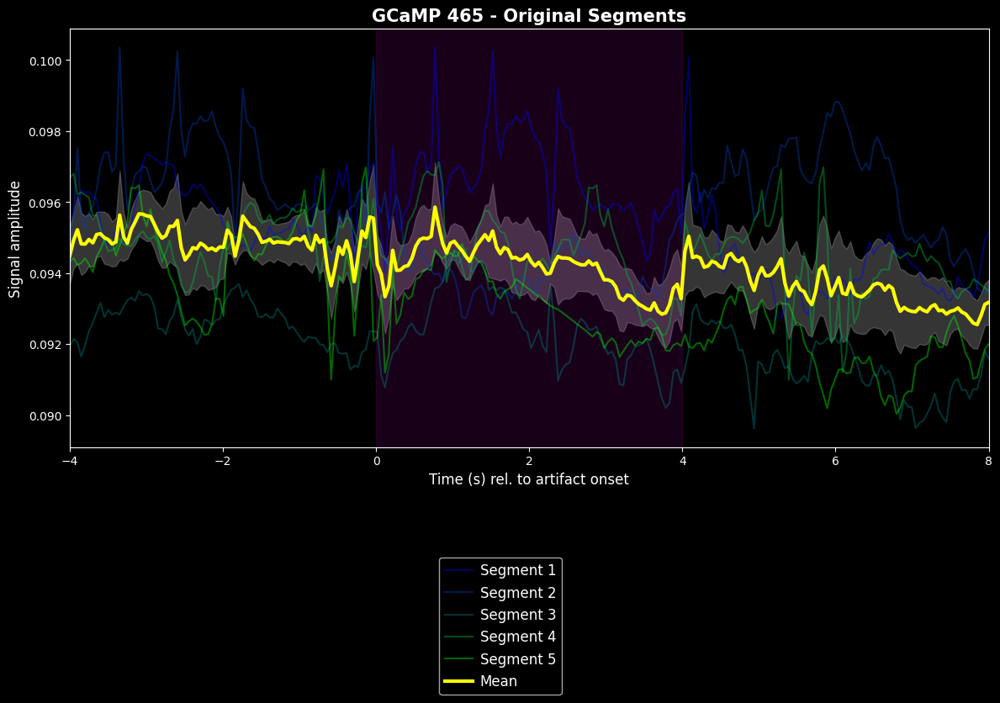

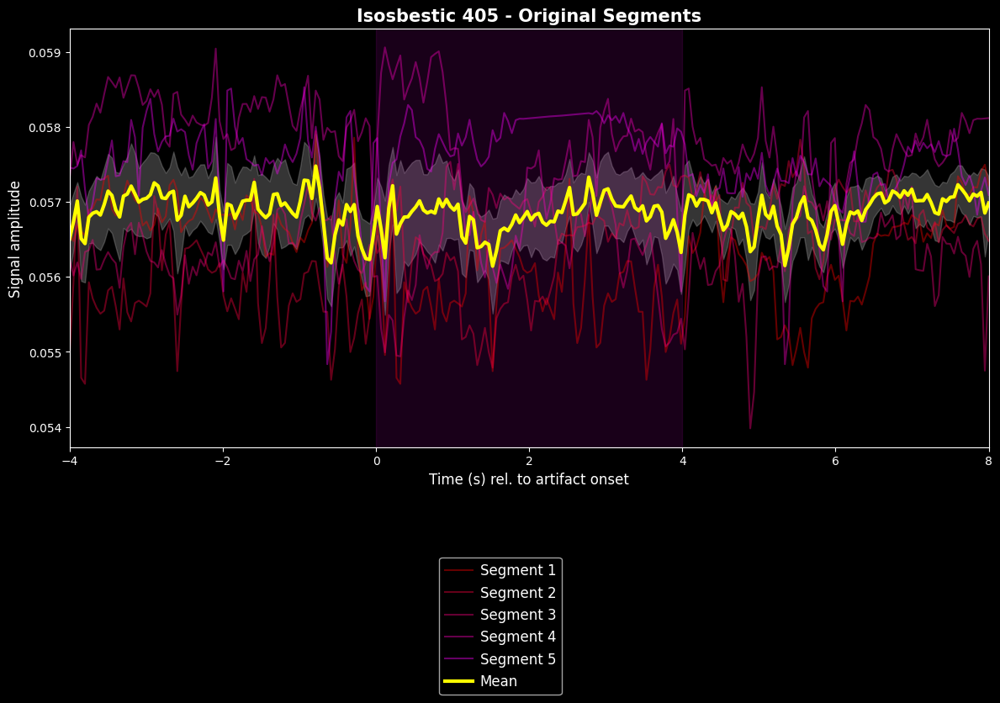

Detected 1 perievent segments.


C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:252: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


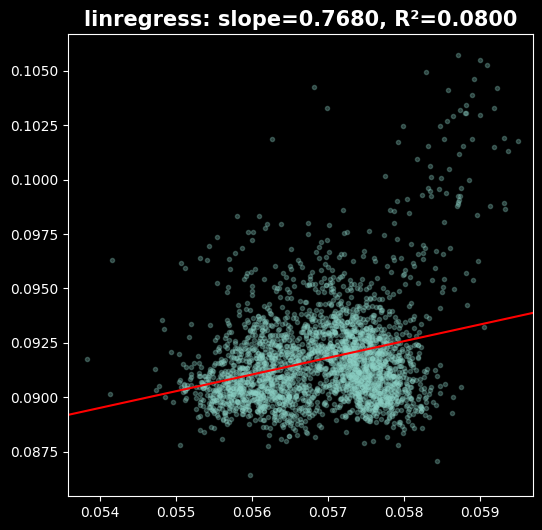

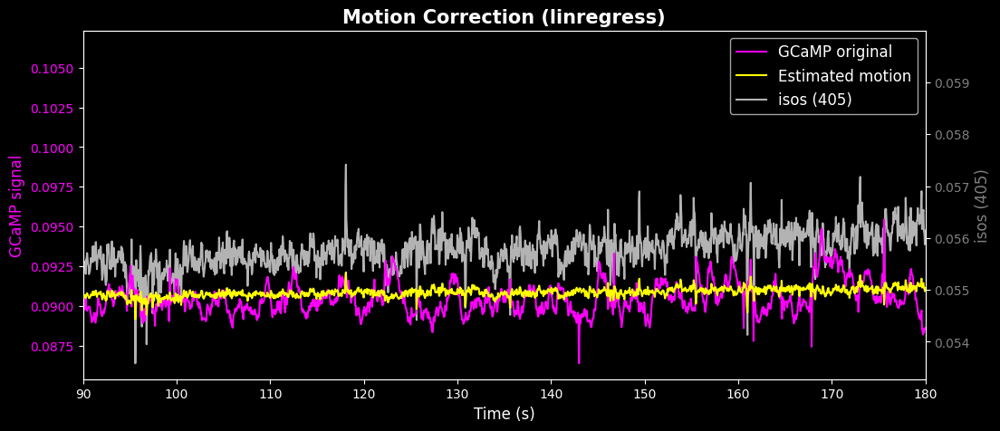

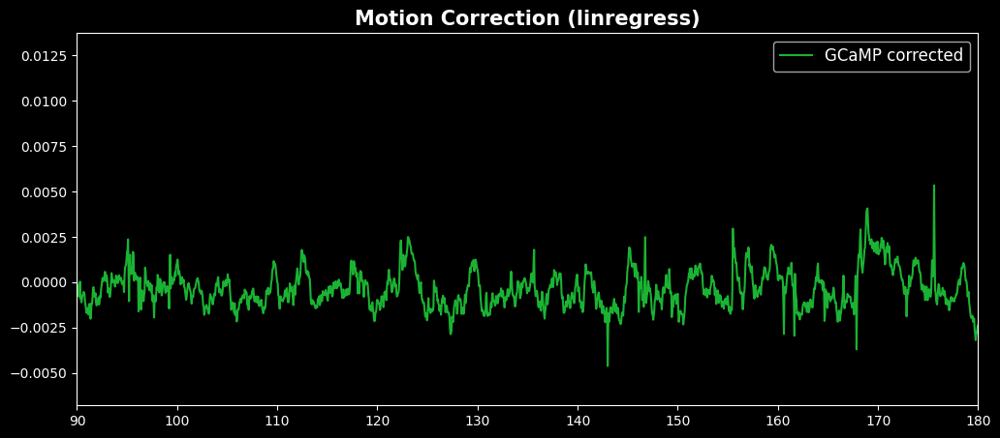

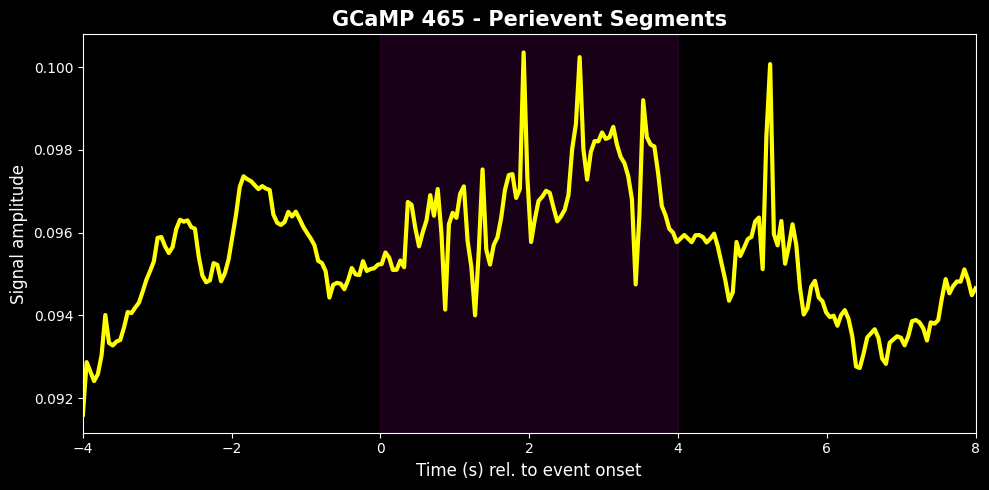

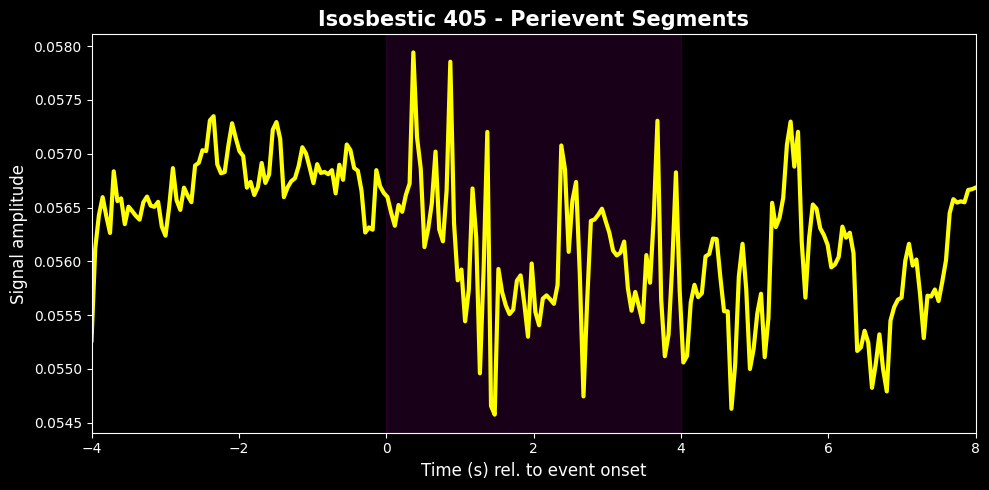

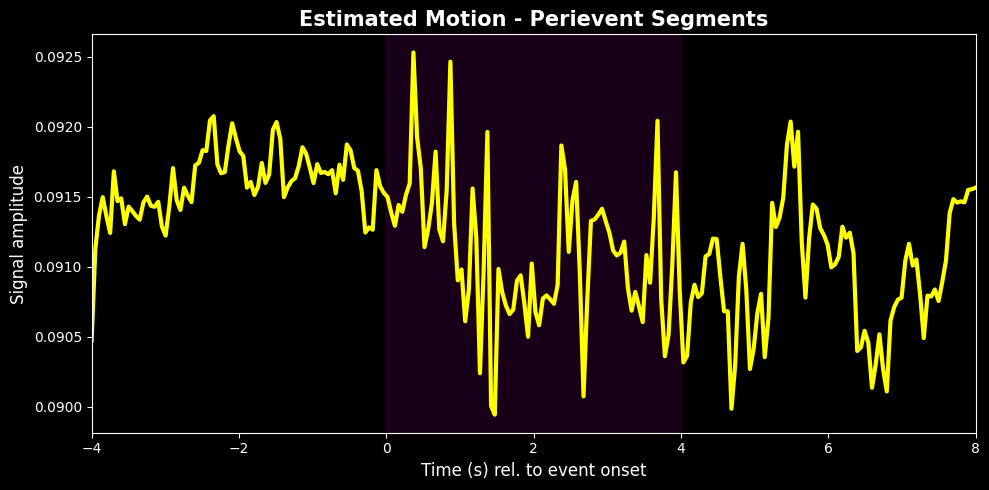

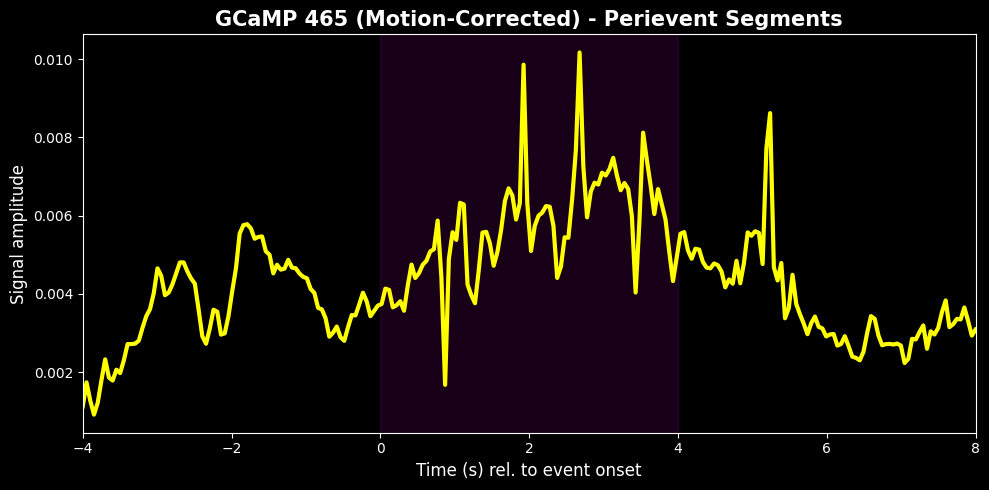

ACW_coh6_IT_f9 preprocessed streams,ts,isosbestic 405nm,"isosbestic 405nm, artifacts corrected",GCaMP 465nm,estimated motion,GCaMP 465nm motion correction,"GCaMP 465nm motion correction, exponential fit","GCaMP 465nm motion correction, exponential fit, airPLS","GCaMP 465nm motion correction, exponential fit, airPLS, z-scored","GCaMP 465nm, dF/F",isosbestic 405nm exponential fit,"isosbestic 405nm exponential fit, airPLS","isosbestic 405nm exponential fit, airPLS, z-scored"
0,0.00,0.058705,0.058705,0.105719,0.093116,0.012603,0.002321,0.002984,1.904658,13.534628,0.001810,0.002402,4.339986
1,0.05,0.058537,0.058537,0.105569,0.092987,0.012582,0.002321,0.002985,1.905163,13.530553,0.001642,0.002234,4.036222
2,0.10,0.058545,0.058545,0.105600,0.092993,0.012607,0.002368,0.003032,1.935278,13.556708,0.001650,0.002242,4.050918
3,0.15,0.058491,0.058491,0.105366,0.092952,0.012414,0.002198,0.002861,1.826268,13.355378,0.001596,0.002188,3.953934
4,0.20,0.058200,0.058200,0.104903,0.092728,0.012175,0.001980,0.002643,1.687429,13.129431,0.001305,0.001897,3.427308
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13281,664.05,0.058328,0.058328,0.089416,0.092826,-0.003410,-0.003410,-0.002133,-1.361368,-3.673754,0.001432,0.000453,0.819261
13282,664.10,0.057854,0.057854,0.089751,0.092462,-0.002711,-0.002711,-0.001434,-0.915149,-2.932224,0.000959,-0.000020,-0.036910
13283,664.15,0.057899,0.057899,0.089366,0.092497,-0.003131,-0.003131,-0.001853,-1.182852,-3.384530,0.001004,0.000025,0.044353
13284,664.20,0.058125,0.058125,0.088931,0.092671,-0.003740,-0.003740,-0.002463,-1.572083,-4.036160,0.001230,0.000251,0.453539


r = 0.7912
slope = 0.3339
intercept = -0.0000
R² = 0.6260
Correlation between z(dF/F) and z-score = 0.7912
🚫 Rejected 10 artifactual peaks


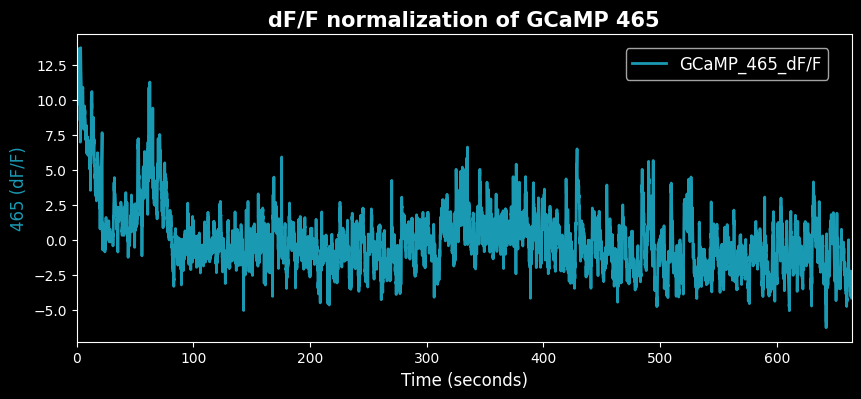

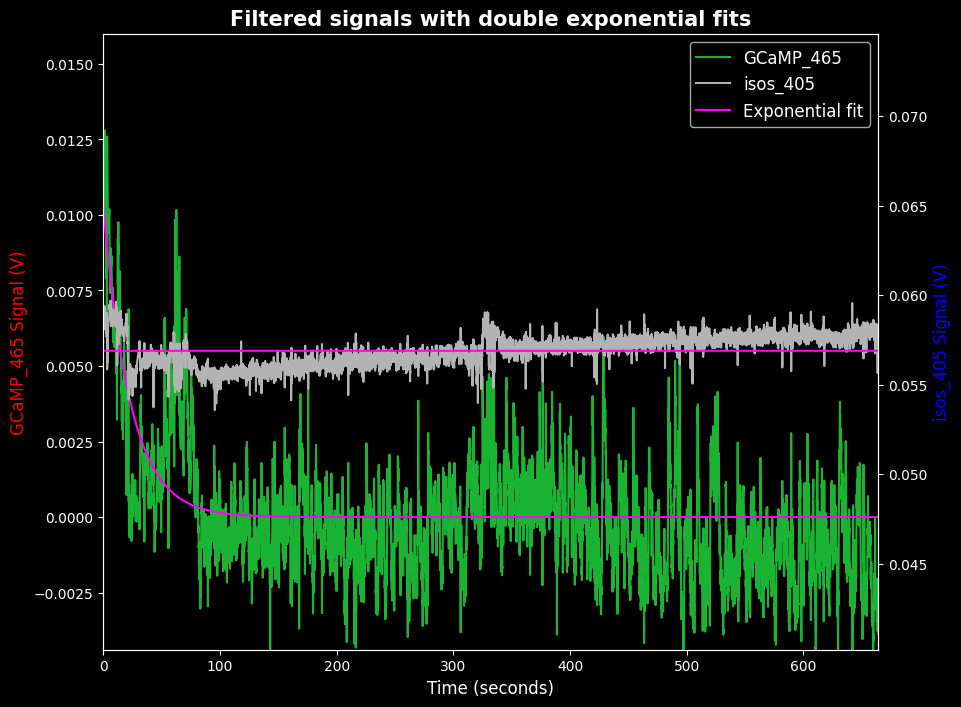

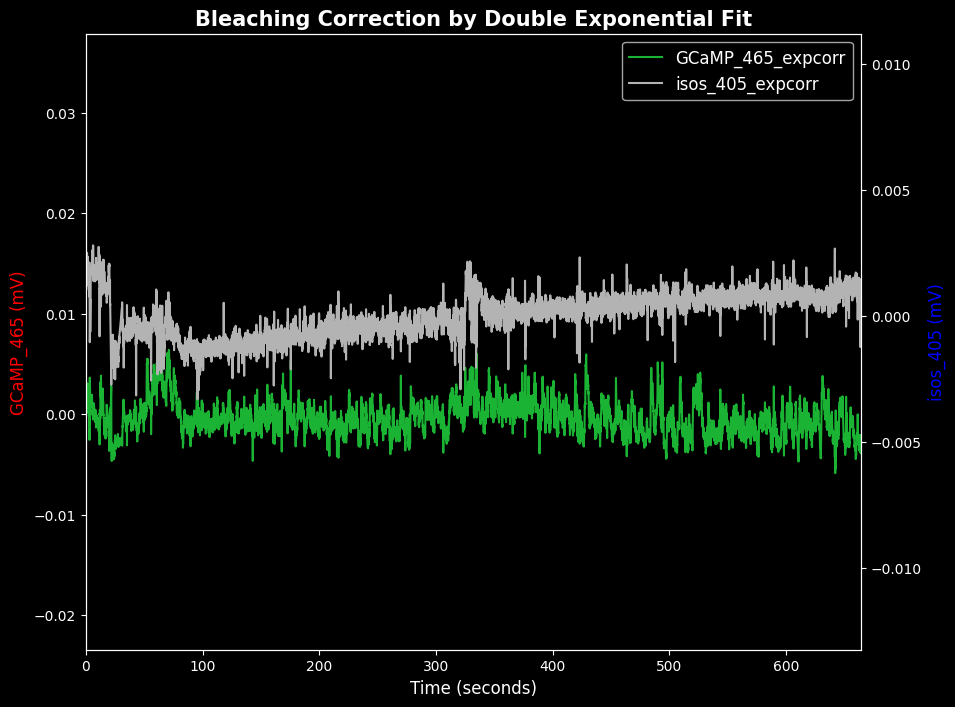

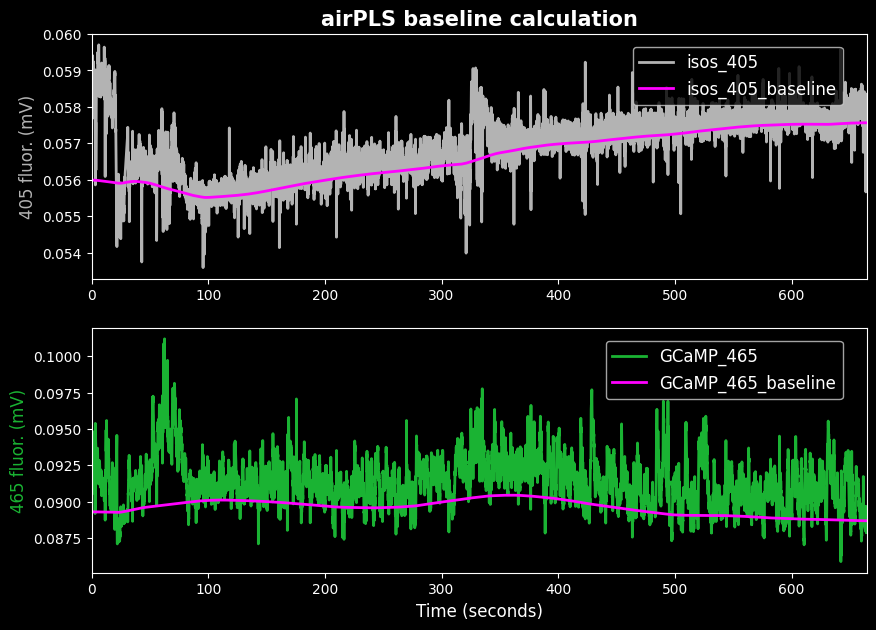

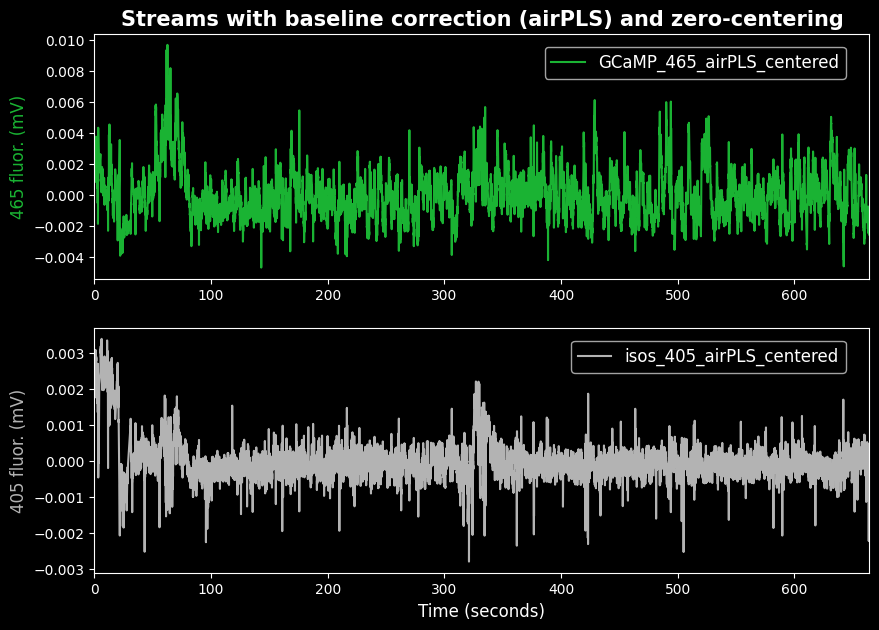

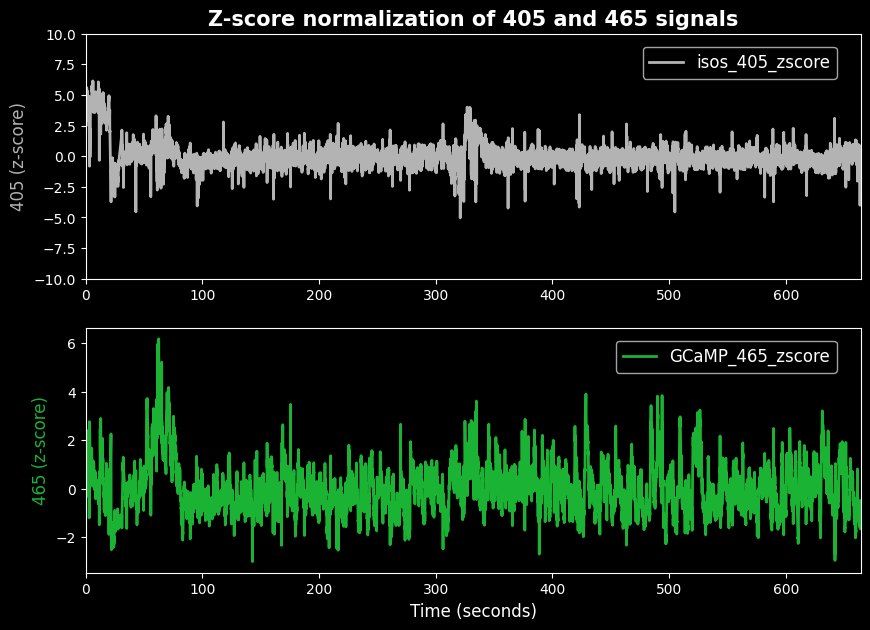

<Figure size 1000x700 with 0 Axes>

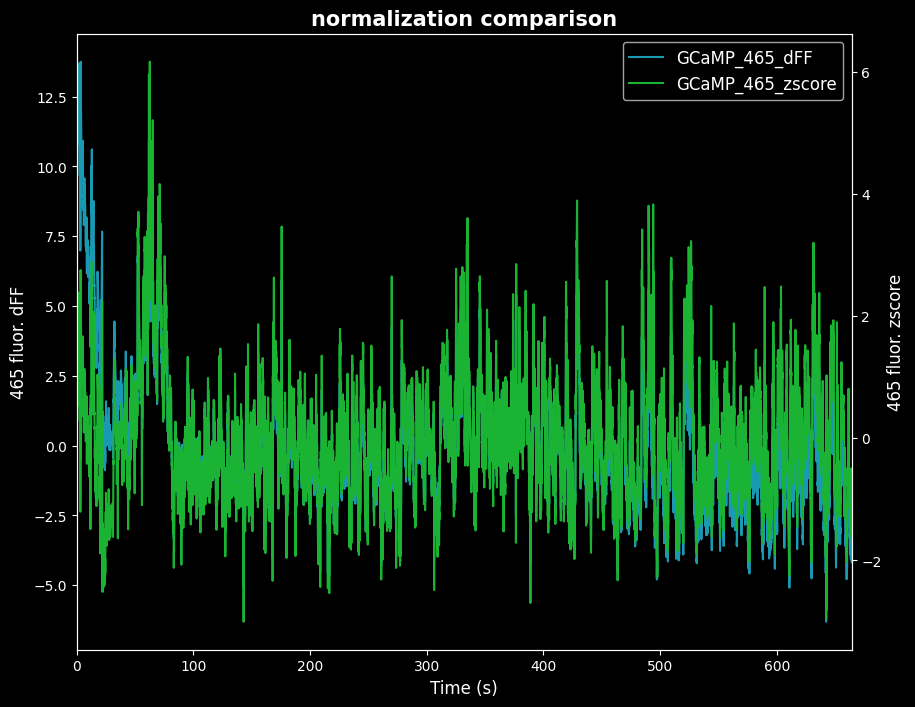

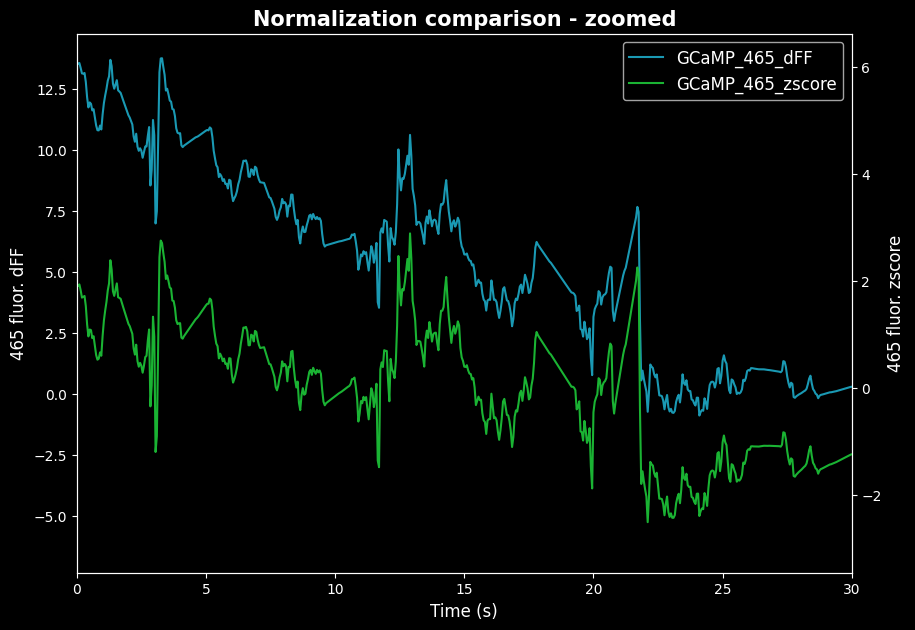

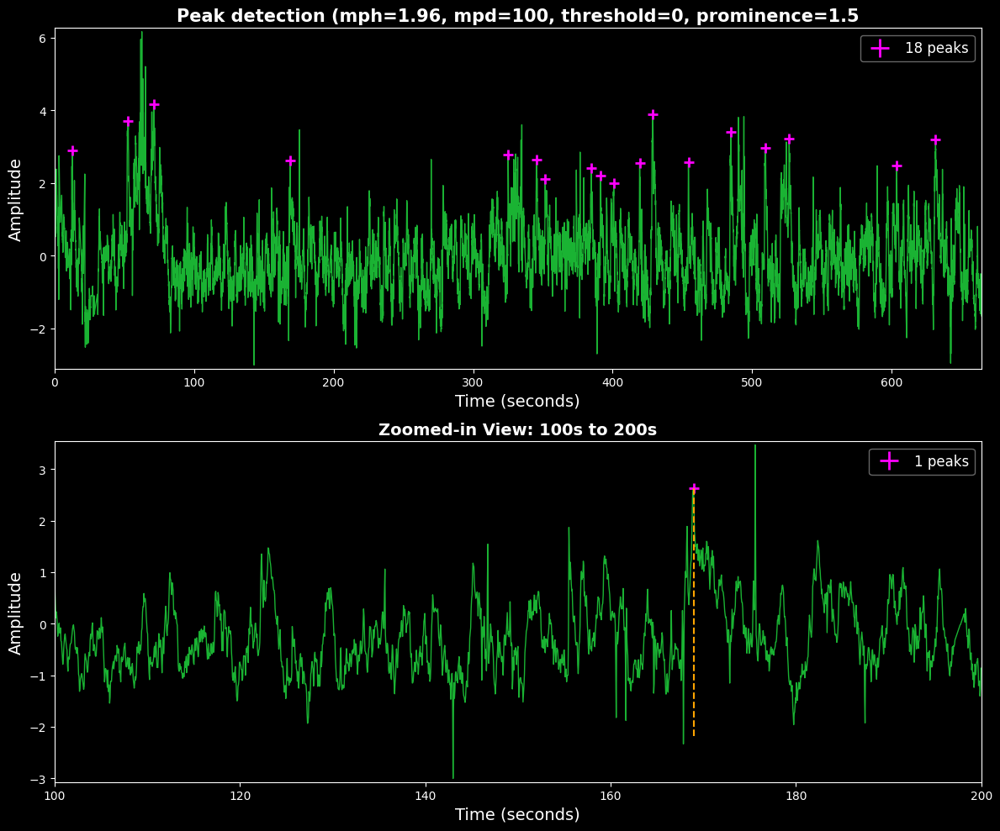

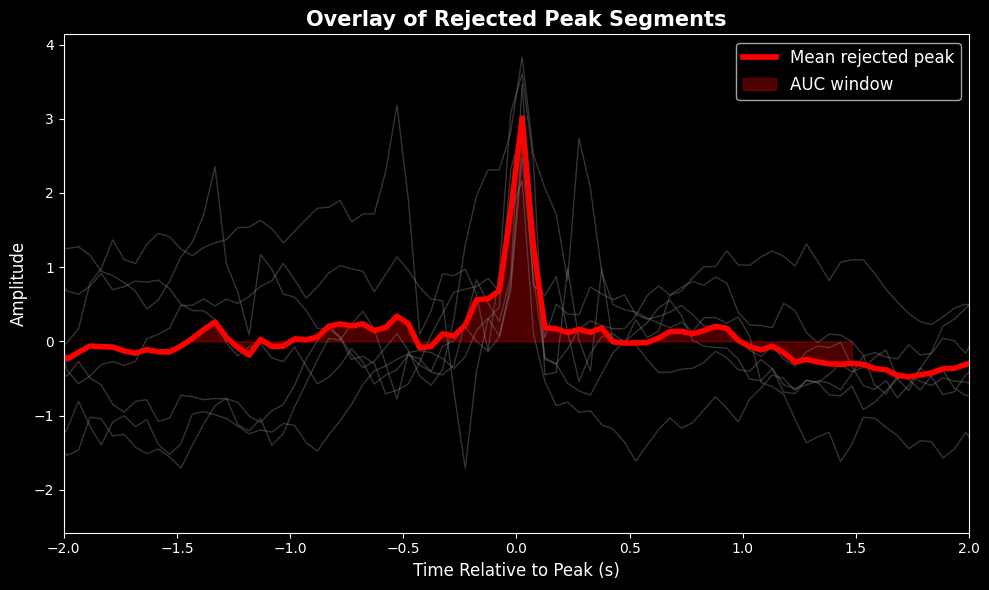

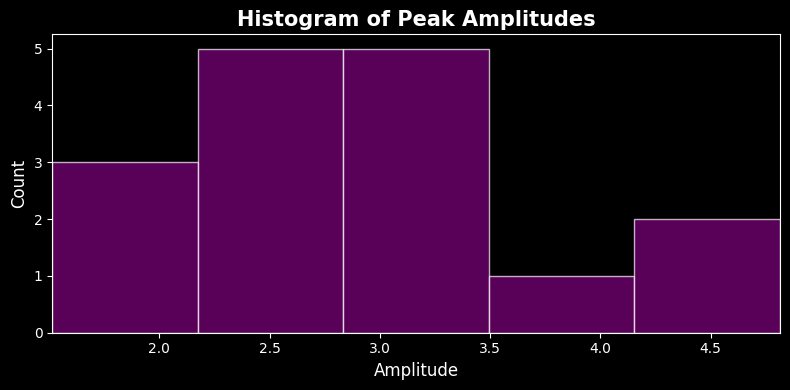

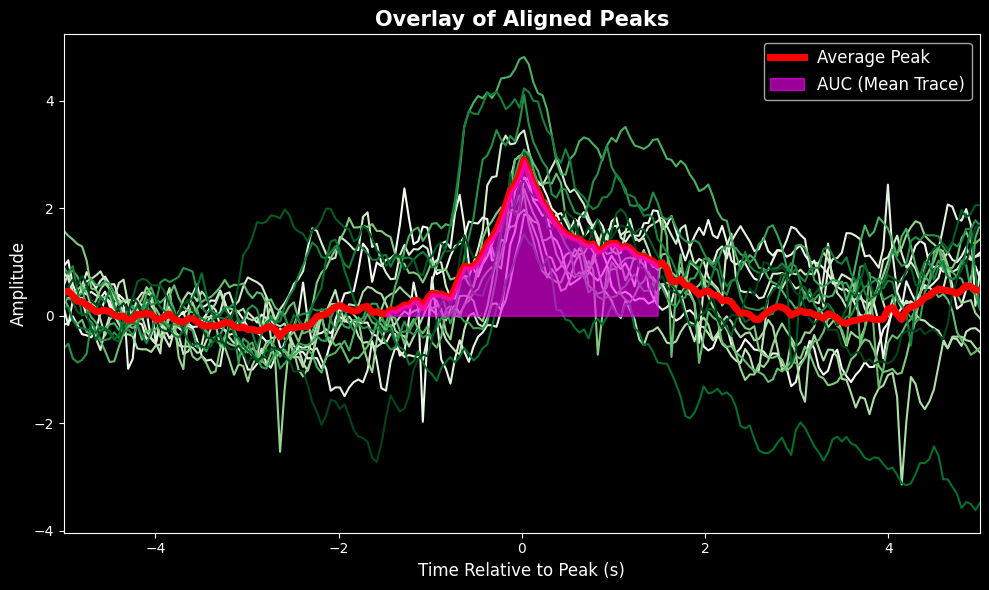


peak frequency is: 0.02408731652239366 Hz

peak amplitudes:
[2.57188213 2.99281799 2.56315631 3.44715588 1.88634266 1.97226886
 2.36170971 2.2409518  3.05009093 4.81404161 3.09248105 4.10790445
 4.23067062 1.51419159 3.03262883 2.50916222]

mean and SEM of peak amplitudes: 2.8992160408584082 +- 0.22532435519844893

🧪 Running perievent analysis for data type: GCaMP
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.
  ▶ Event: available_unavailable (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.

🧪 Running perievent analysis for data type: isosbestic
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limi

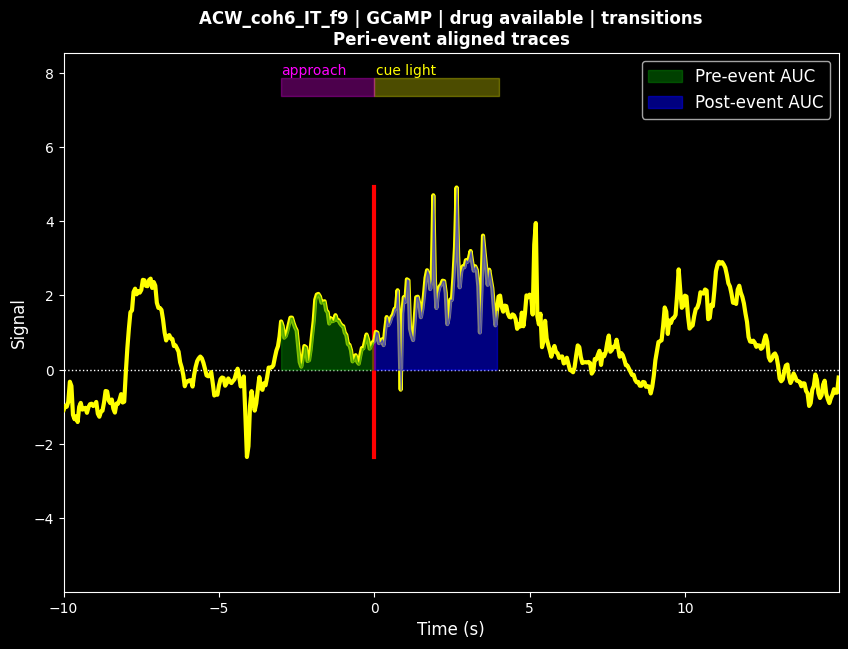

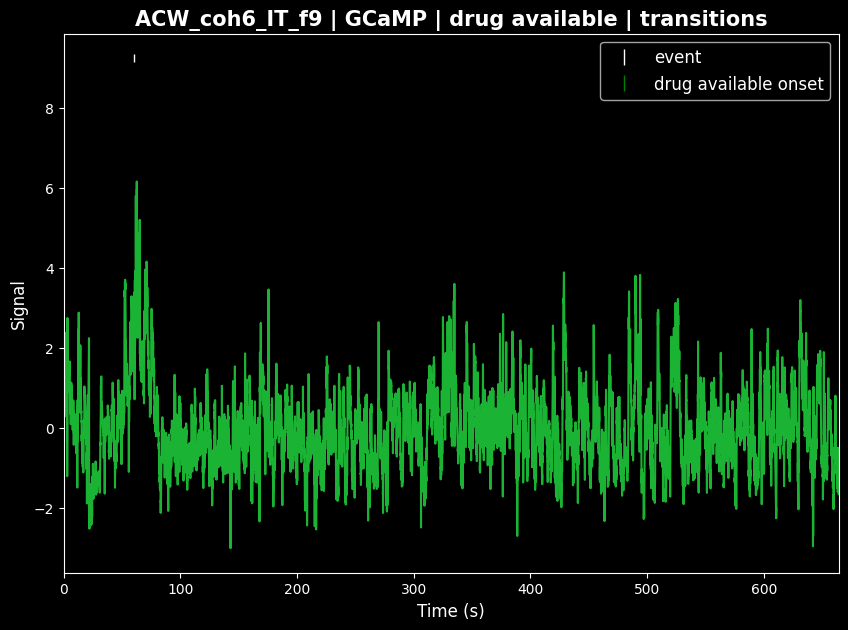

GCaMP | Event: available_unavailable


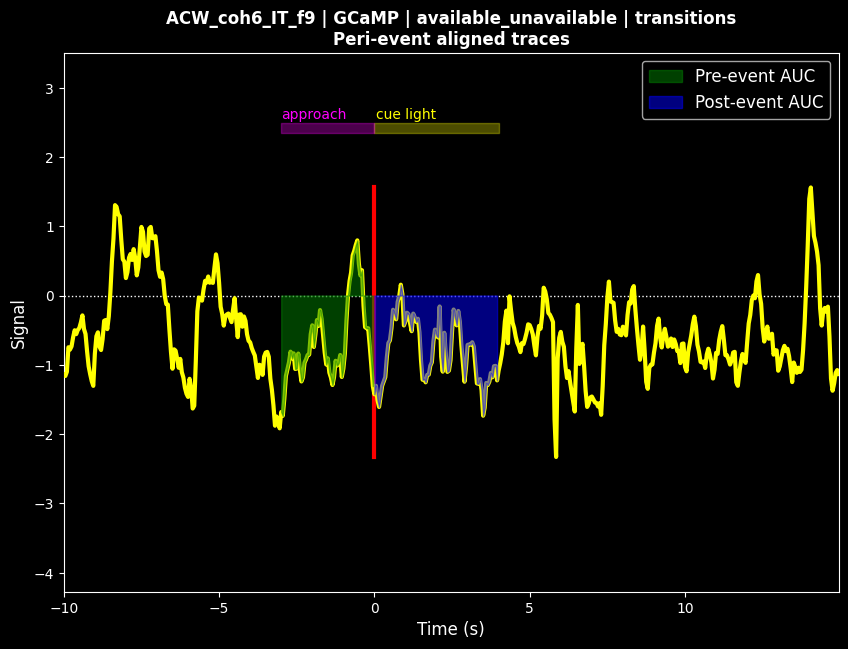

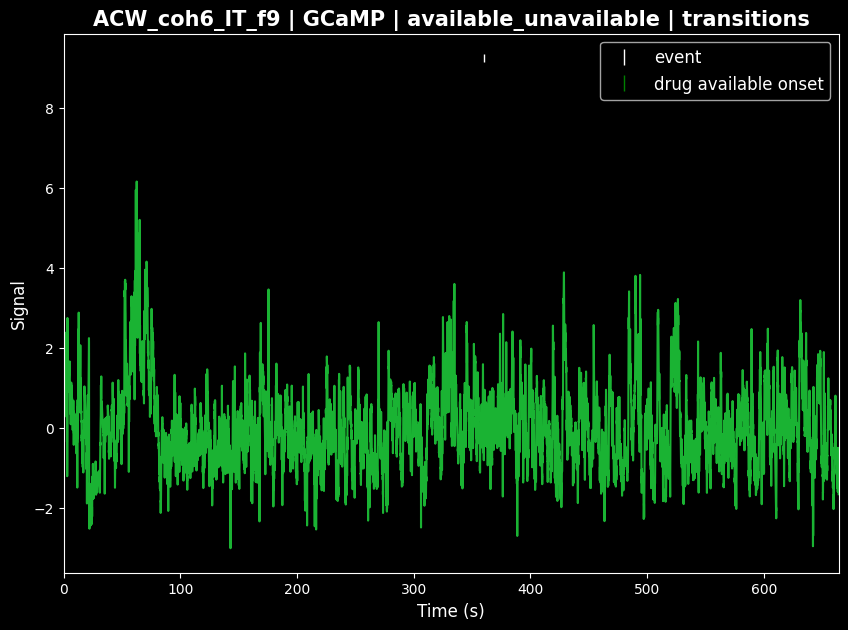

isosbestic | Event: drug available


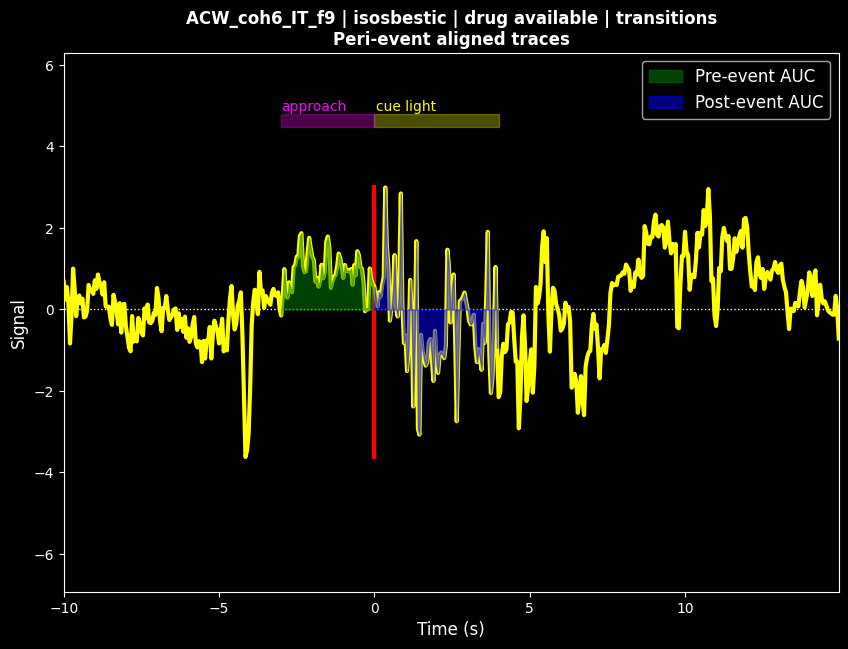

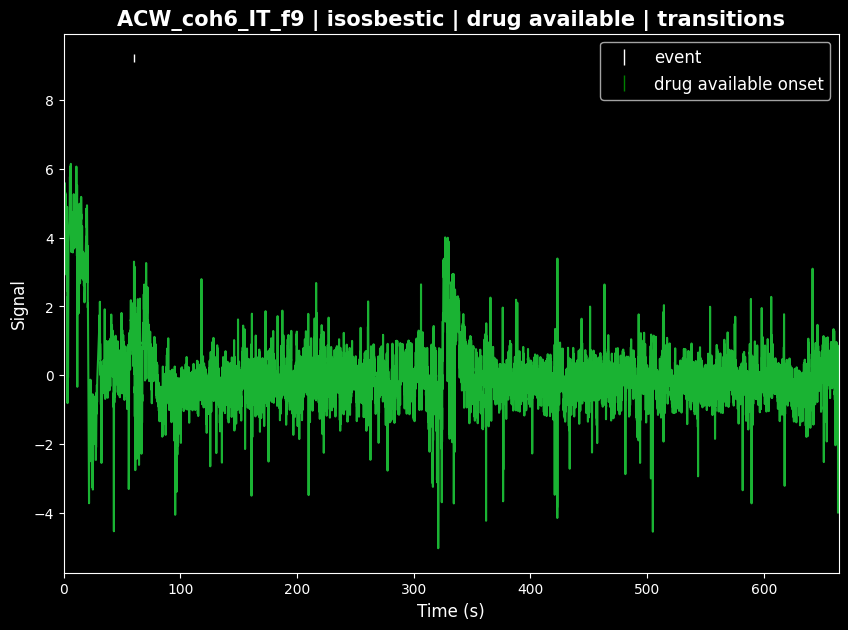

isosbestic | Event: available_unavailable


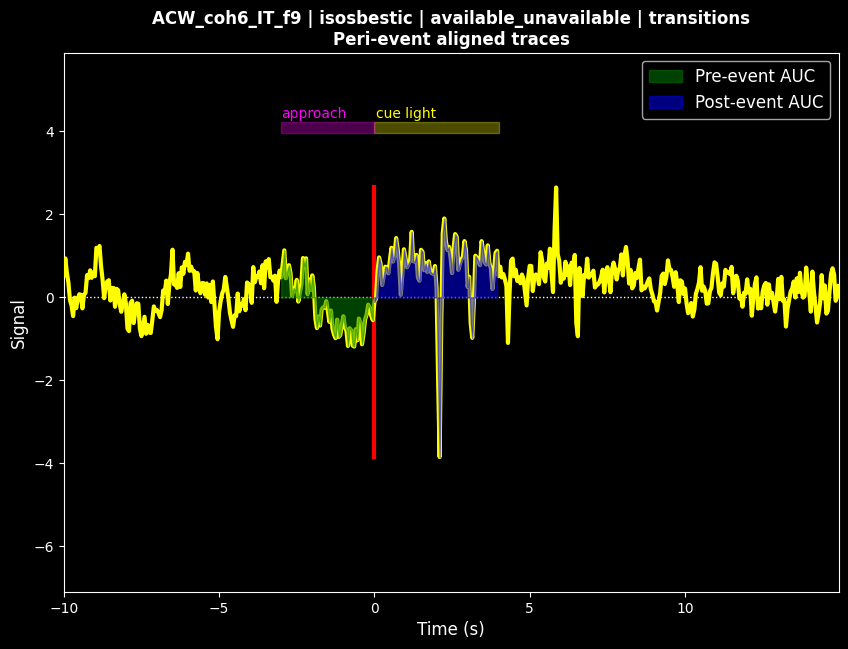

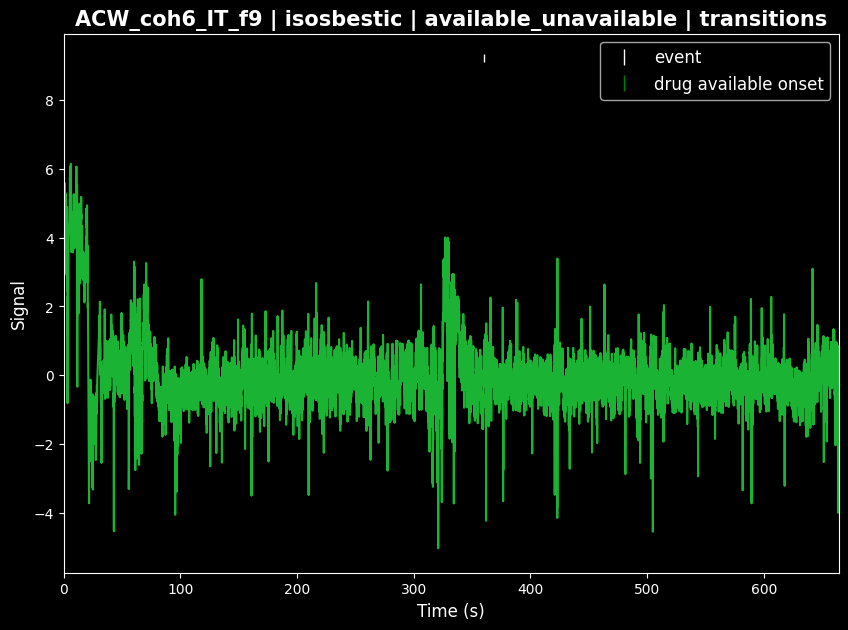

- GCaMP/
  - drug available/
    - epocs: DataFrame
    - epocs_baselined: DataFrame
    - epocs_mean_std_sem: DataFrame
    - mean_trace: ndarray
    - std_trace: ndarray
    - sem_trace: ndarray
    - events_info: DataFrame
    - fig_5: Figure
    - fig_15: Figure
    - subset_figs: NoneType
    - event_parameters/
      - rat: str
      - data type: str
      - preprocessed data stream: str
      - event type examined: str
      - event count: int
      - trange: list
      - baseline_trange: list
      - subset: NoneType
      - approach window: str
      - mean approach response: str
      - SEM approach response: str
      - cue window: str
      - mean cue response: str
      - SEM cue response: str
      - pre-event AUC window: str
      - mean pre-event AUC: str
      - SEM pre-event AUC: str
      - post-event AUC window: str
      - mean post-event AUC: str
      - SEM post-event AUC: str
    - n_events: int64
  - available_unavailable/
    - epocs: DataFrame
    - epocs_bas

,blockname,nickname,channel_raw,channel_name,fs,device_start_time,device_stop_time
0,ACW_coh6d_102226_0002,ACW_coh6_IT_f10,Headstage01LockIn01,Headstage01_470nm,100,10:11:07.878,10:28:57.943
1,ACW_coh6d_102226_0002,ACW_coh6_IT_f10,Headstage01LockIn02,Headstage01_415nm,100,10:11:07.878,10:28:57.943
2,ACW_coh6d_102226_0002,ACW_coh6_IT_f9,Headstage02LockIn01,Headstage02_470nm,100,10:11:07.878,10:28:57.943
3,ACW_coh6d_102226_0002,ACW_coh6_IT_f9,Headstage02LockIn02,Headstage02_415nm,100,10:11:07.878,10:28:57.943


,blockname,channel_raw,channel_name,nickname,time,raw_au
0,ACW_coh6d_102226_0002,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.269711,0.060633
1,ACW_coh6d_102226_0002,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.279711,0.060667
2,ACW_coh6d_102226_0002,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.289711,0.060595
3,ACW_coh6d_102226_0002,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.299711,0.060444
4,ACW_coh6d_102226_0002,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.309711,0.060245
...,...,...,...,...,...,...
427787,ACW_coh6d_102226_0002,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1069.887878,0.056564
427788,ACW_coh6d_102226_0002,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1069.897878,0.056659
427789,ACW_coh6d_102226_0002,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1069.907878,0.056685
427790,ACW_coh6d_102226_0002,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1069.917878,0.056624


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,365.129
1,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,28.616
2,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,29.626
3,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,30.326
4,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,31.616
5,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,90.128
6,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,126.510
7,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,350.129
8,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,353.639
9,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,368.440


Moved ACW_coh6d_102226_0002_streams_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0002_streams_info.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0002_epocs_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
File not found, skipping: ACW_coh6d_102226_0002_epocs_info.feather
🔍 Detected format: Doric
⚠️ Missing expected channels for BOX2 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX4 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX5 (ACW_coh5_IT_). Skipping.

✅ Found photometry data for boxes: BOX3



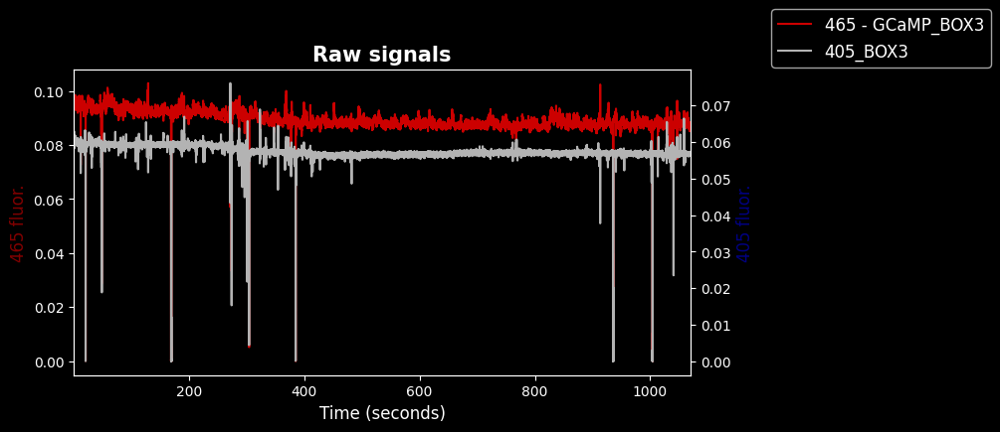

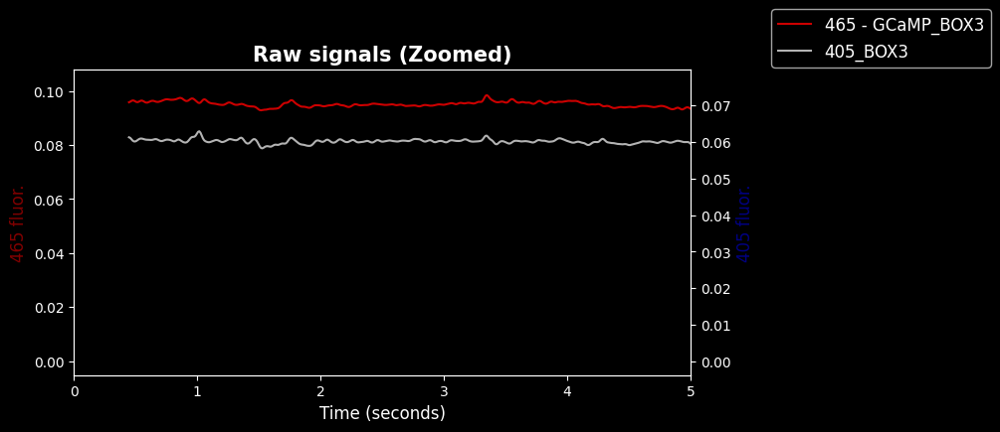

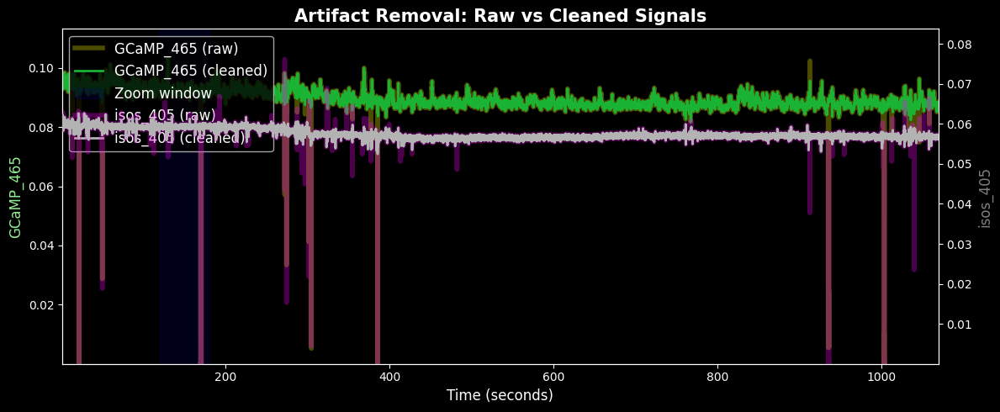

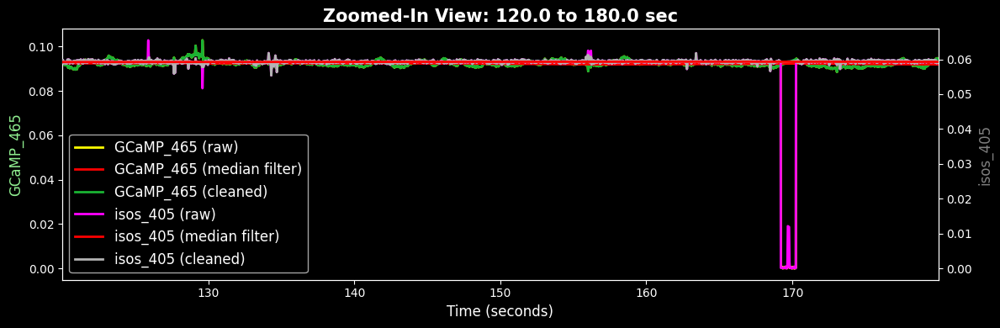

20.0


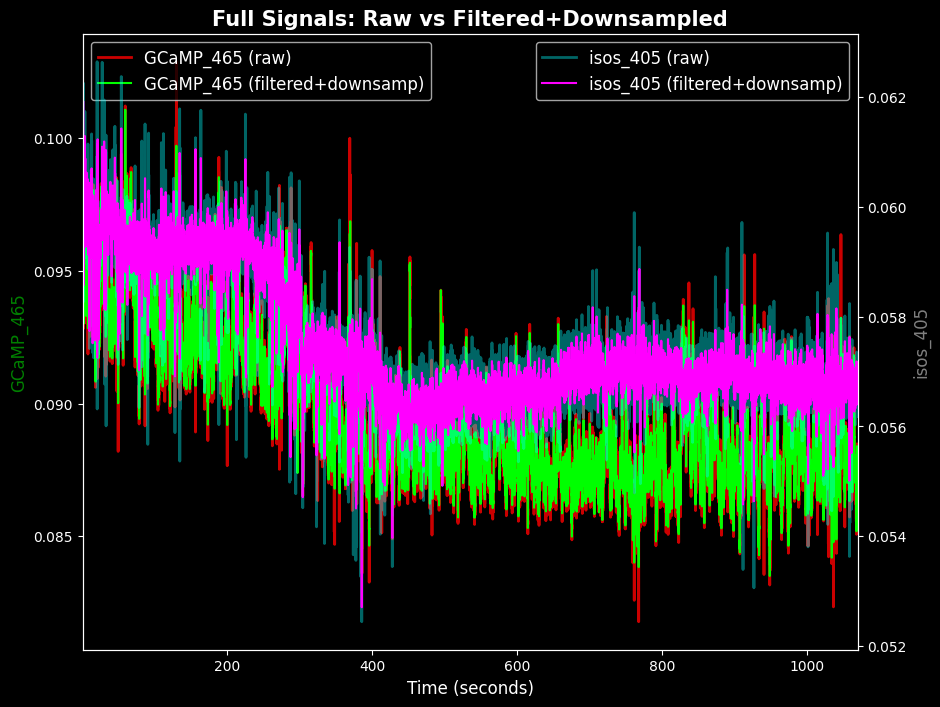

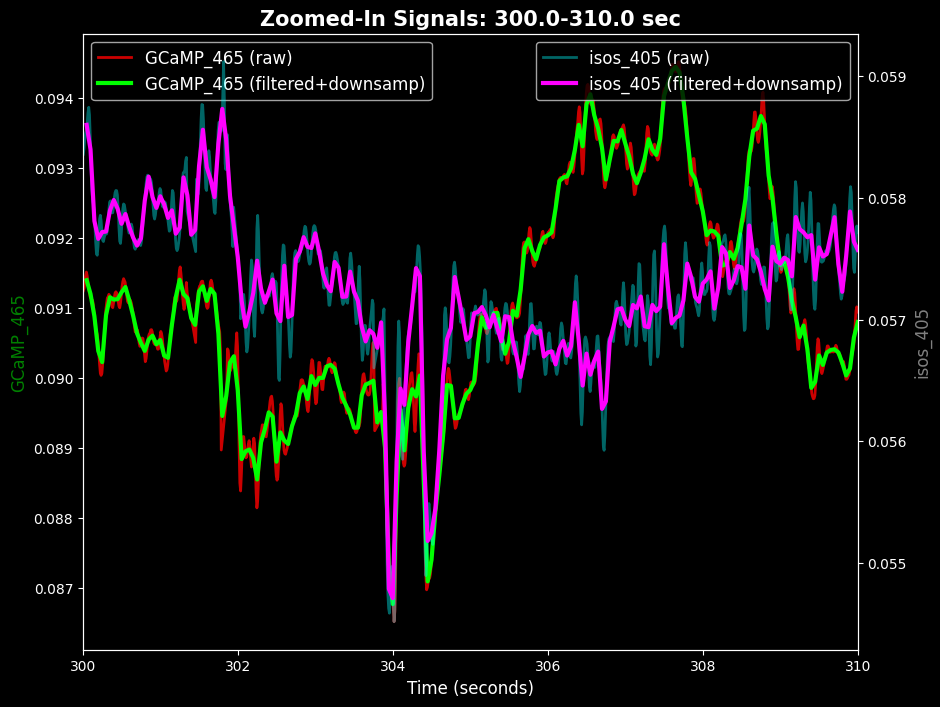

isos_405 length: 106924
isos_405_downsamp length: 21390
GCaMP_465 length: 106924
GCaMP_465_downsamp length: 21390
ts_all length: 106924
ts_downsamp length: 21390

the duration of the stream data is 1069.8982776699997 seconds, aka 17.831637961166663 mins


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,365.129
1,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,28.616
2,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,29.626
3,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,30.326
4,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,31.616
5,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,90.128
6,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,126.510
7,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,350.129
8,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,353.639
9,ACW_coh6d_102226_0002,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,368.440


detected data format: Doric

📋 Unique D## codes found: ['D13' 'D14' 'D16' 'D29' 'D30' 'D31' 'D32']
📌 dropsec_code reflects beginning of the Med Associates program
📌 dropsec_code reflects onset of drug availability

⏱ dropsec code D13 corresponds to timepoints: [365.129]

✅ Using dropsec = 365.129 seconds from epoc data.
the downsampled sampling rate is 20.0 Hz

discard the first 365.129 seconds, data points from 0 to 7302

keep a duration of 15 minutes
including to end of stream: data points 6094 to 21390

- - - - - initial vector lengths - - - - -

len(isos_405_filt_downsamp): 21390
len(ts_downsamp): 21390

start index: 6094
end index: 21390

Trimmed duration: 764.75 sec (~12.75 min) (requested 15 min, pre_buffer 0s, post_buffer 0s)

Plotting TRANSITION segment (1 min before → 1 min after available period, total 17.0 min) ...


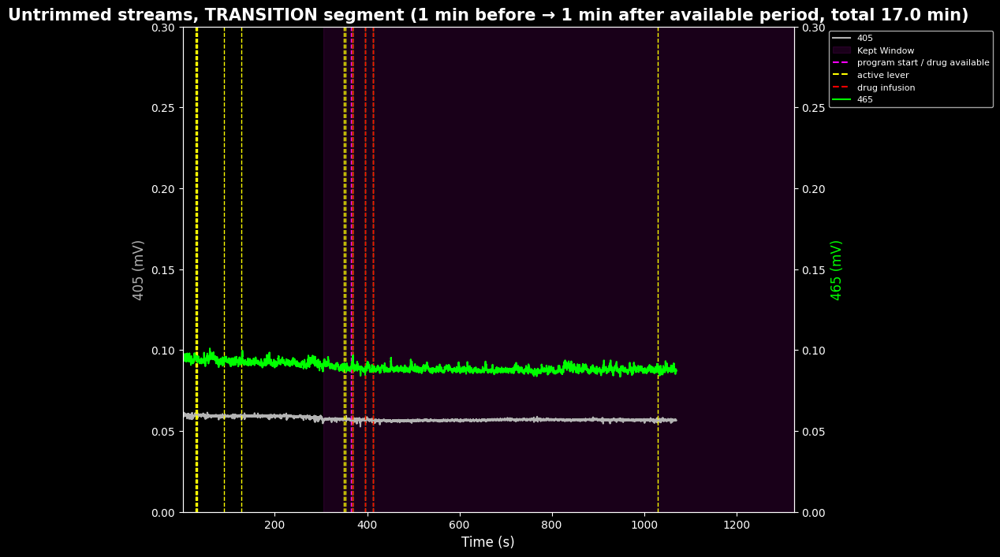

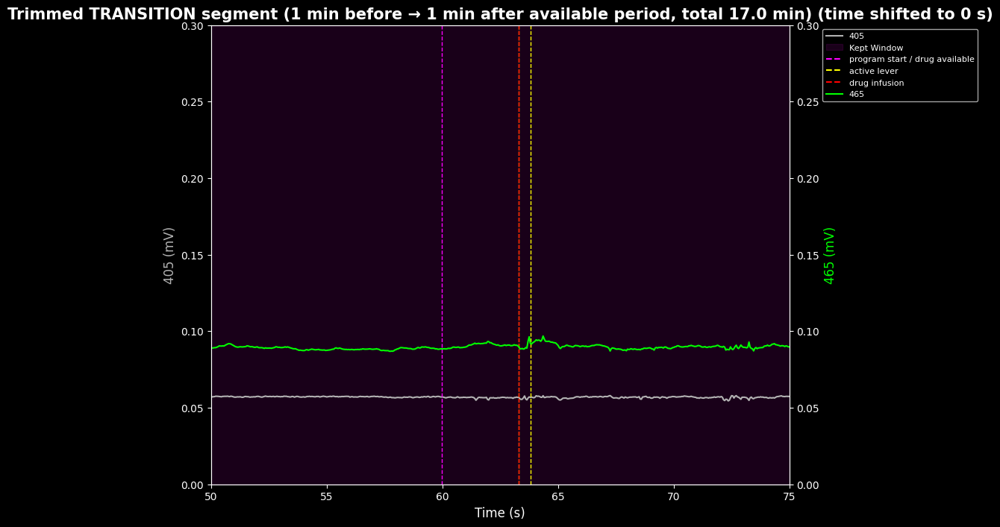

examining 15 minutes of the epoc data
the dropsec code is D13
the start code is 0
dropsec is equal to 365.129
Intermittent access self-admin epoc_ts_and_indices:


ACW_coh6_IT_f9 epoc timestamps,epoc_ts,epoc_indices,data,event
0,60.000,1200,D13,drug available
1,45.000,900,D14,active lever
2,48.510,970,D14,active lever
3,63.311,1266,D14,active lever
4,63.841,1276,D14,active lever
5,90.532,1810,D14,active lever
6,107.212,2144,D14,active lever
7,360.000,7200,NaN,available_unavailable
8,63.311,1266,D16,drug infusion
9,90.532,1810,D16,drug infusion


Detected 3 artifact segments.


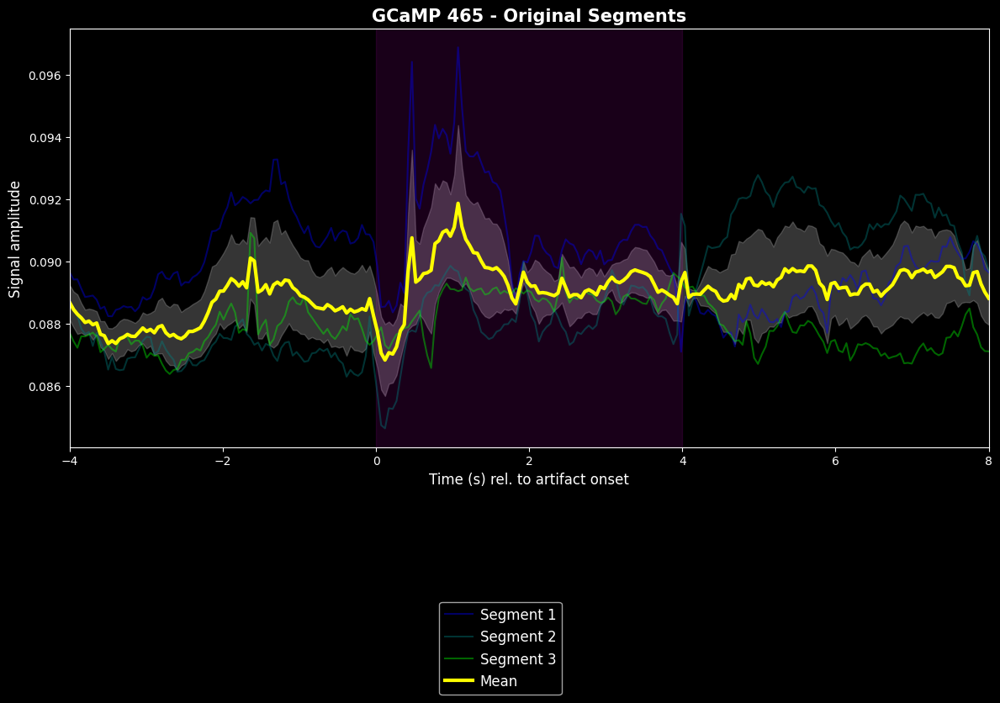

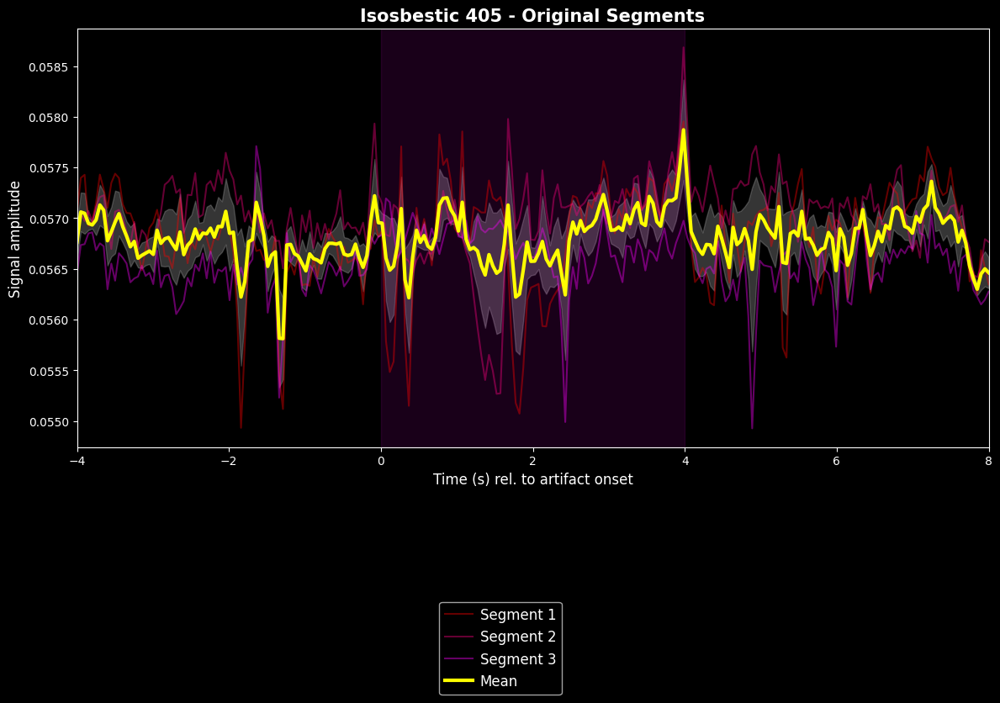

negative regression slope, correction not applied
Detected 1 perievent segments.


C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:252: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


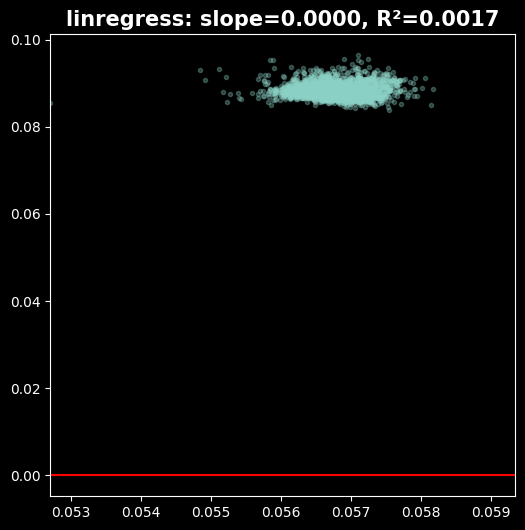

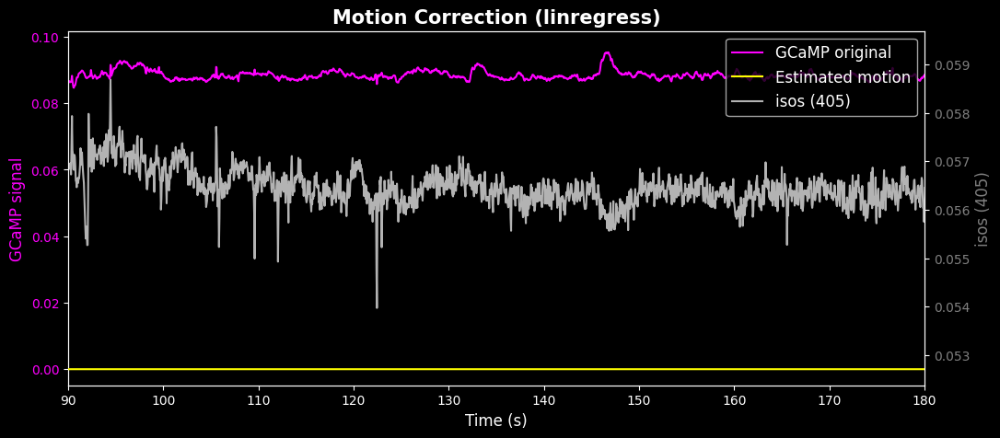

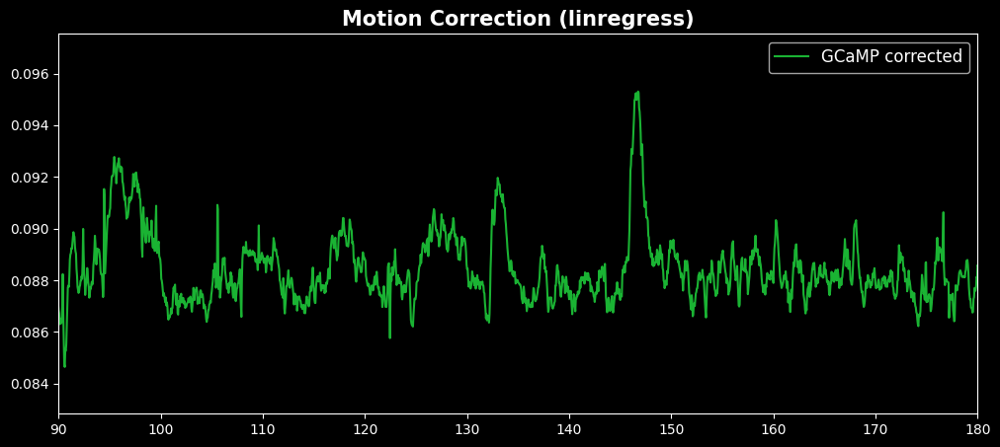

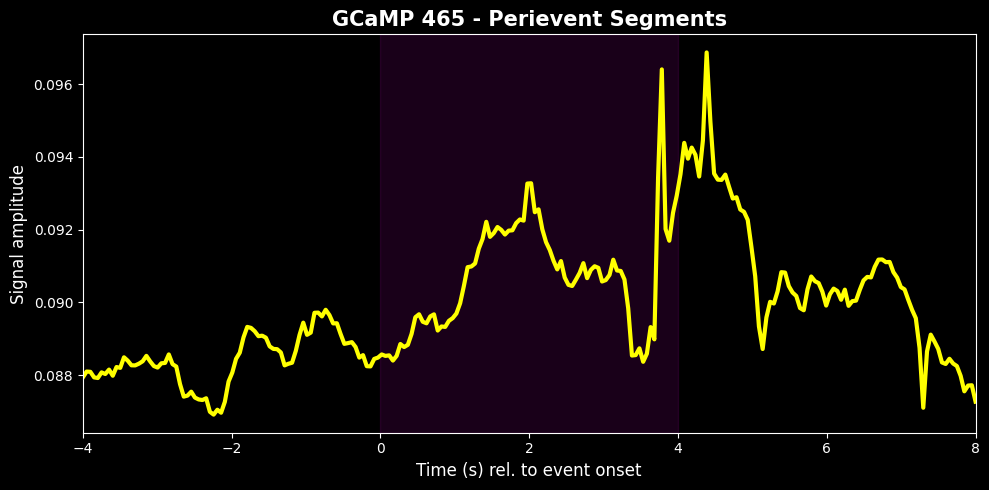

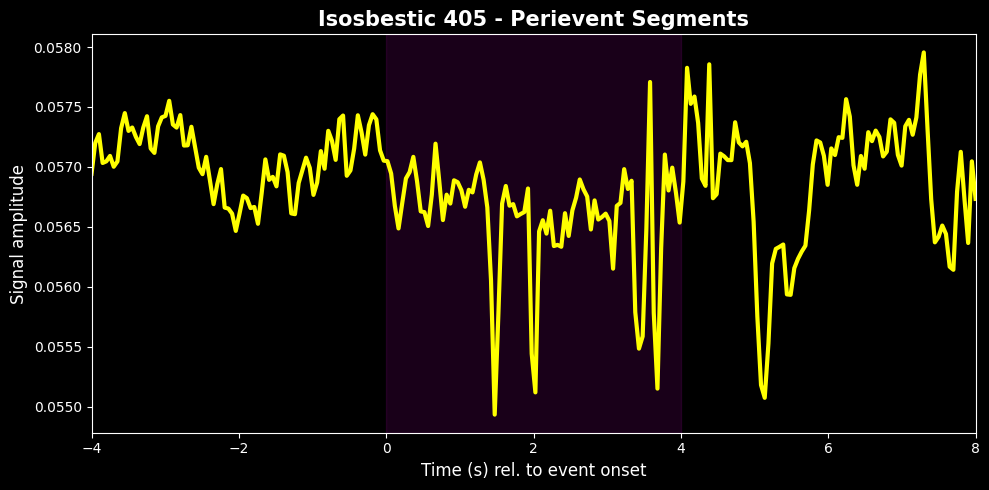

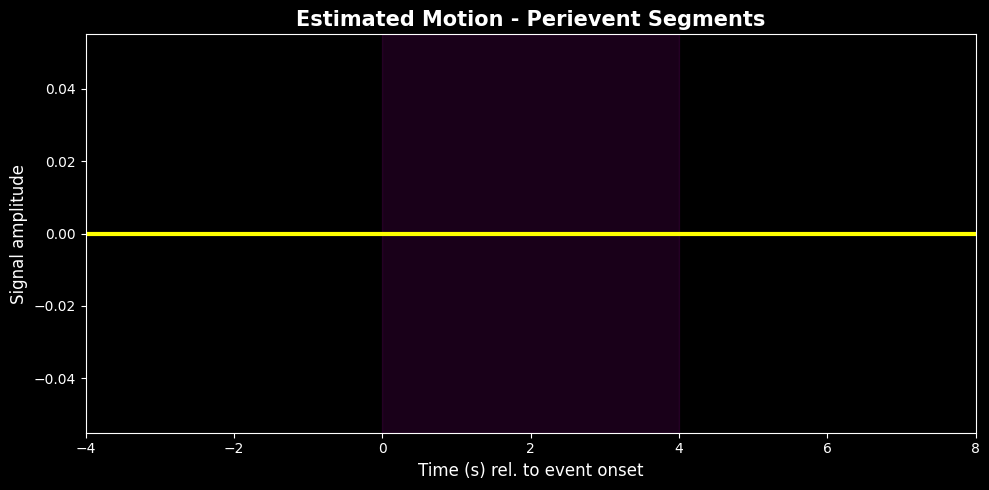

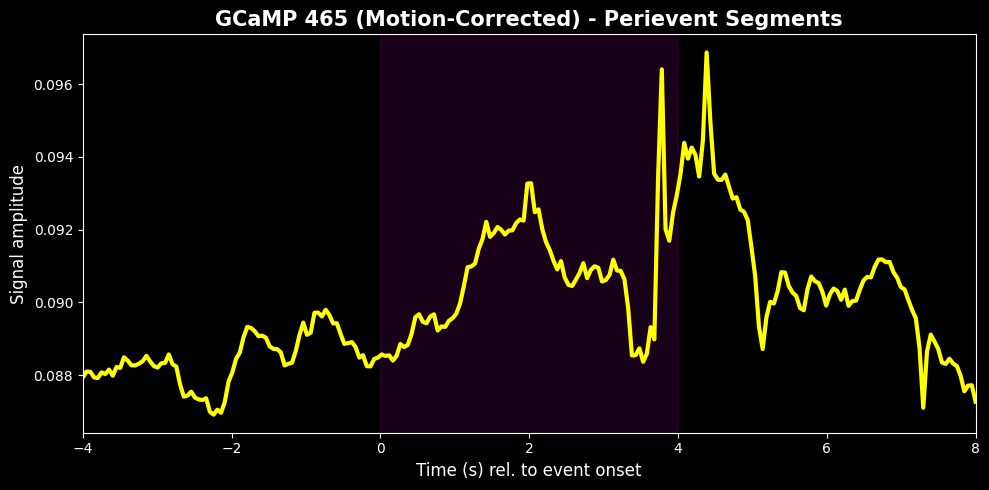

c:\Python\Whitebirch_python\fp_func_acw.py:3812: RuntimeWarning: divide by zero encountered in true_divide
  normData = np.divide(res, control) # (F(t)-f0)/F0


ACW_coh6_IT_f9 preprocessed streams,ts,isosbestic 405nm,"isosbestic 405nm, artifacts corrected",GCaMP 465nm,estimated motion,GCaMP 465nm motion correction,"GCaMP 465nm motion correction, exponential fit","GCaMP 465nm motion correction, exponential fit, airPLS","GCaMP 465nm motion correction, exponential fit, airPLS, z-scored","GCaMP 465nm, dF/F",isosbestic 405nm exponential fit,"isosbestic 405nm exponential fit, airPLS","isosbestic 405nm exponential fit, airPLS, z-scored"
0,0.00,0.057102,0.057102,0.090867,0.0,0.090867,-0.000935,-0.000825,-0.603481,inf,0.000302,-0.000089,-0.286600
1,0.05,0.057035,0.057035,0.090719,0.0,0.090719,-0.001079,-0.000970,-0.709319,inf,0.000235,-0.000157,-0.502278
2,0.10,0.056936,0.056936,0.090749,0.0,0.090749,-0.001046,-0.000936,-0.684713,inf,0.000136,-0.000256,-0.820147
3,0.15,0.057037,0.057037,0.090923,0.0,0.090923,-0.000869,-0.000759,-0.555340,inf,0.000237,-0.000154,-0.493394
4,0.20,0.056927,0.056927,0.090931,0.0,0.090931,-0.000857,-0.000747,-0.546737,inf,0.000127,-0.000265,-0.848911
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15291,764.55,0.056560,0.056560,0.087883,0.0,0.087883,-0.000082,-0.000093,-0.068363,inf,-0.000241,-0.000192,-0.617391
15292,764.60,0.056511,0.056511,0.087927,0.0,0.087927,-0.000038,-0.000050,-0.036270,inf,-0.000289,-0.000241,-0.772294
15293,764.65,0.056620,0.056620,0.087724,0.0,0.087724,-0.000240,-0.000252,-0.184647,inf,-0.000180,-0.000132,-0.423838
15294,764.70,0.056667,0.056667,0.087470,0.0,0.087470,-0.000494,-0.000506,-0.370295,inf,-0.000133,-0.000085,-0.272609


r = nan
slope = nan
intercept = nan
R² = nan
Correlation between z(dF/F) and z-score = nan
🚫 Rejected 8 artifactual peaks


C:\Python\envs\python_acw\lib\site-packages\numpy\lib\function_base.py:2536: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Python\Whitebirch_python\fp_func_acw.py:3946: RuntimeWarning: invalid value encountered in subtract
  GCaMP_465_dFF - np.mean(GCaMP_465_dFF)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:230: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


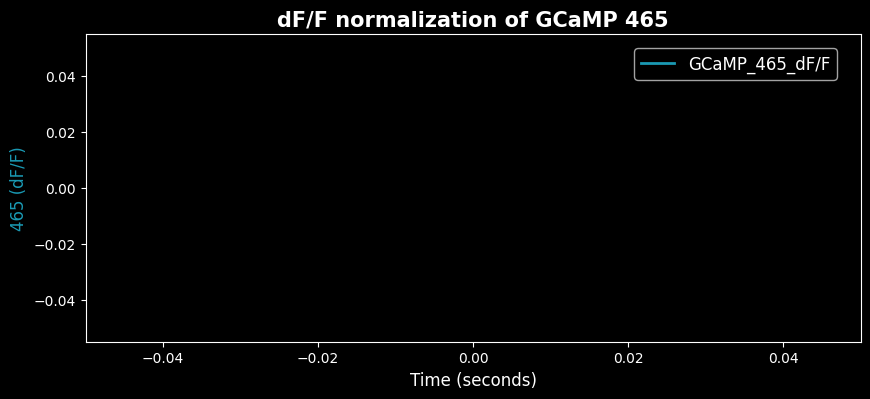

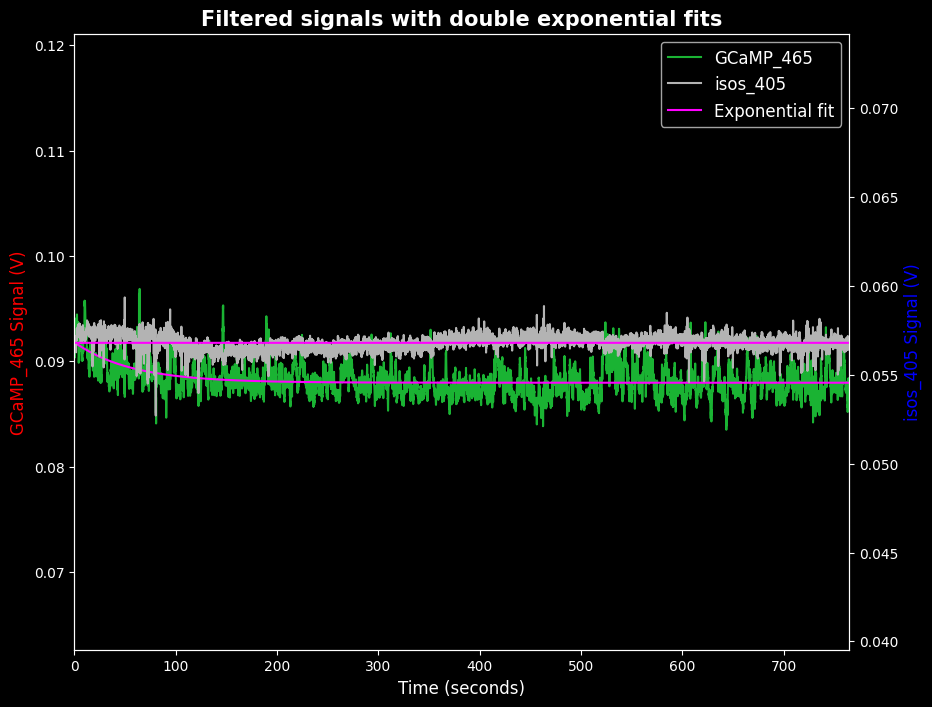

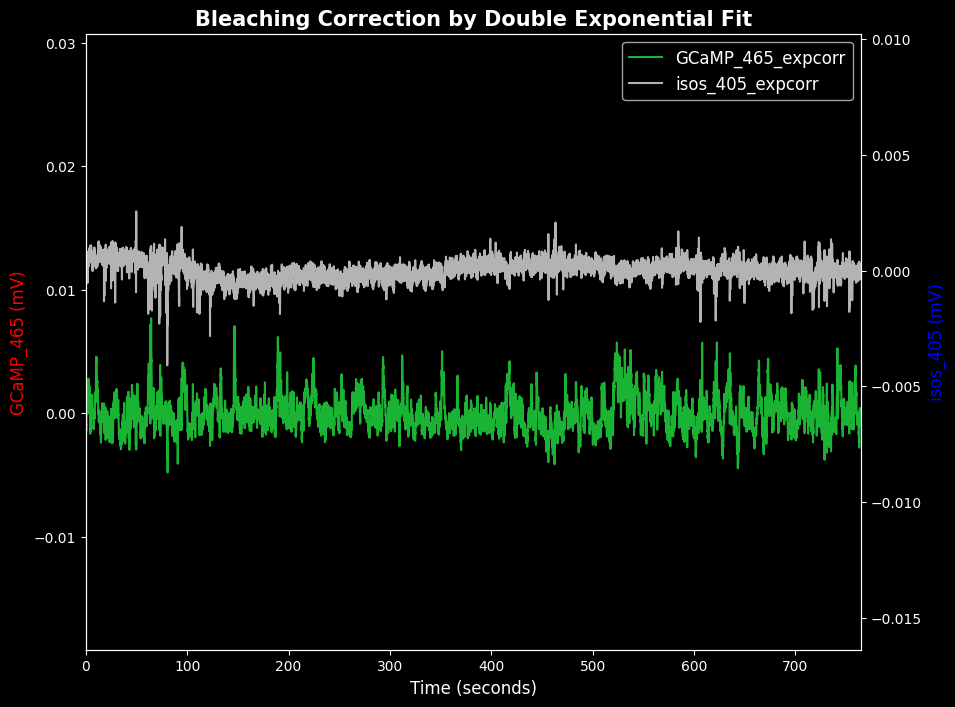

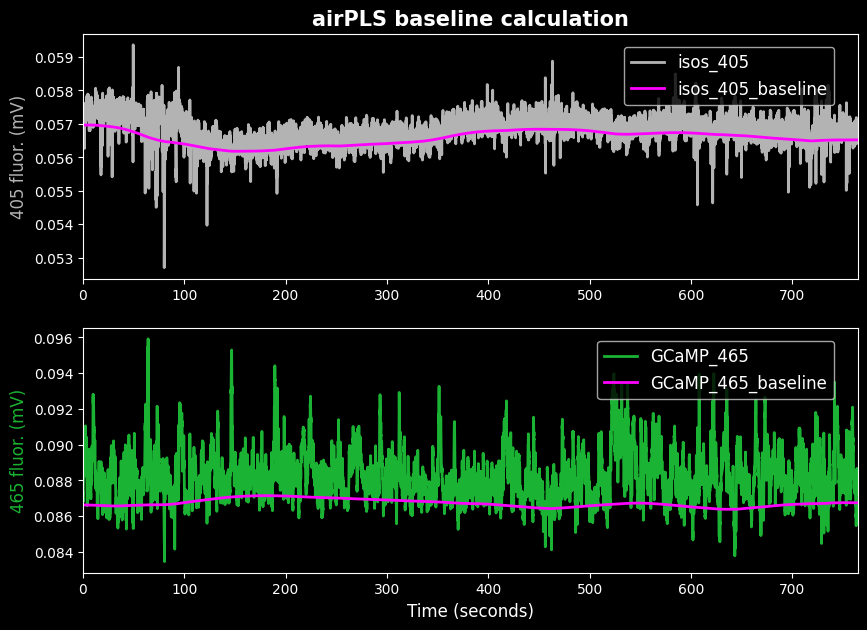

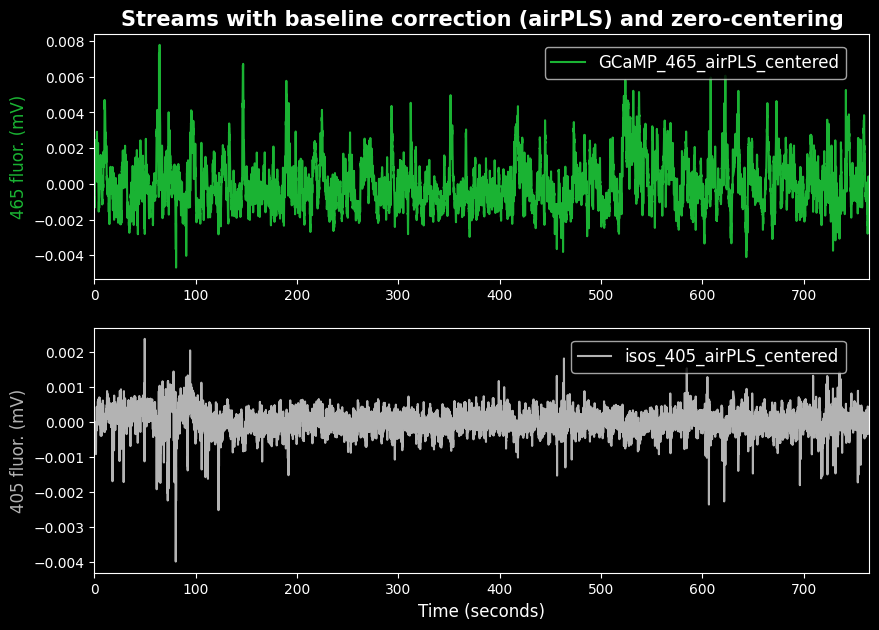

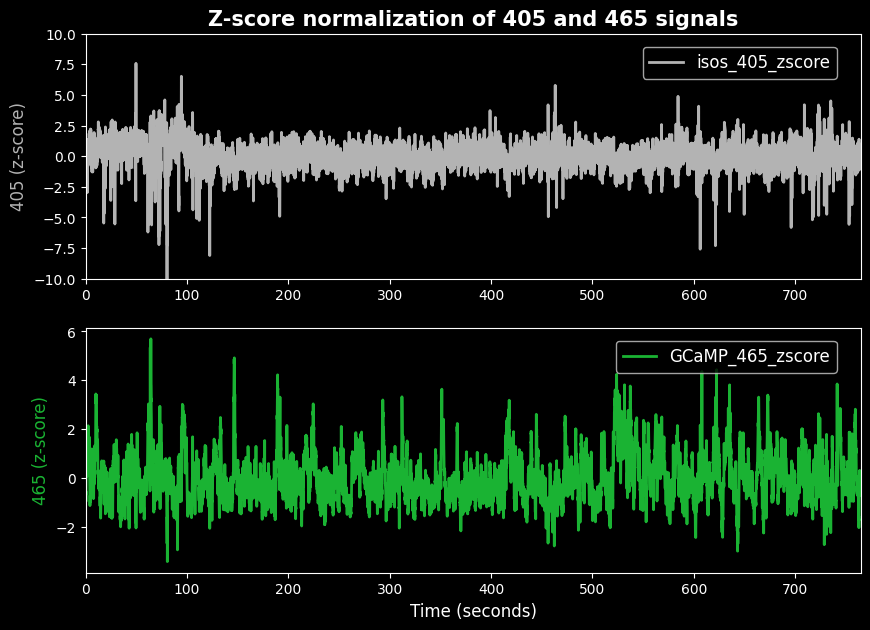

<Figure size 1000x700 with 0 Axes>

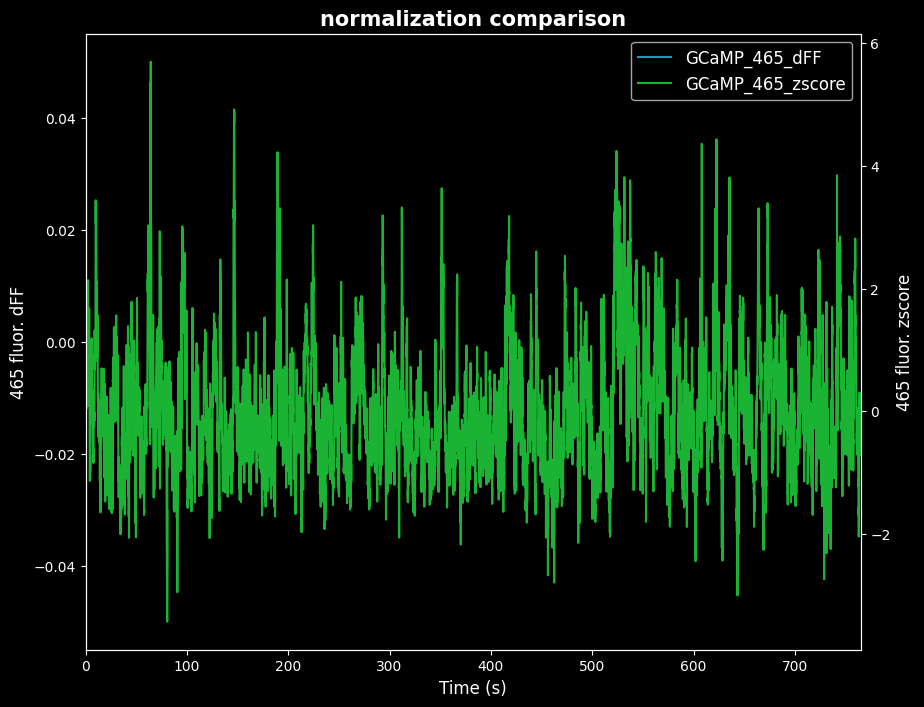

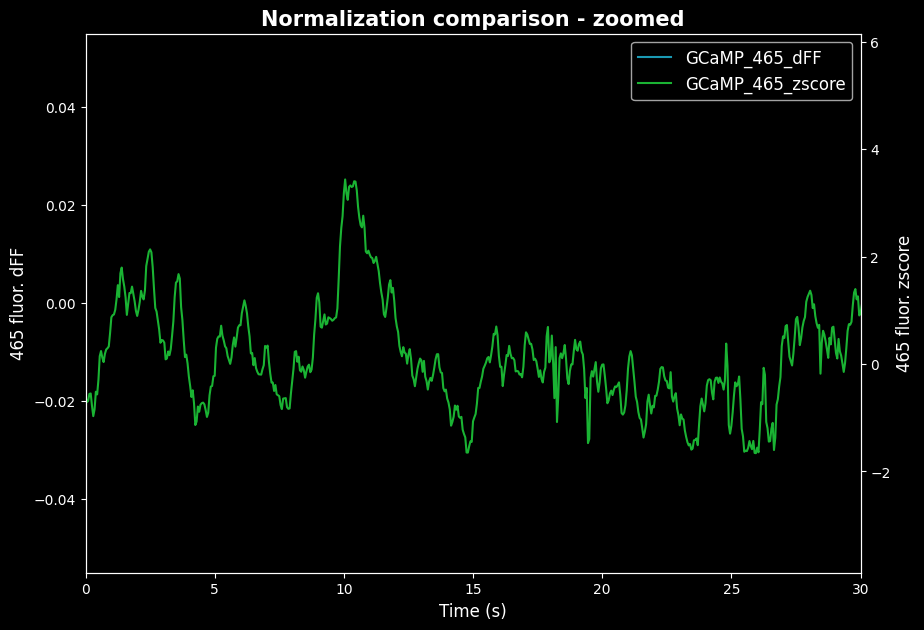

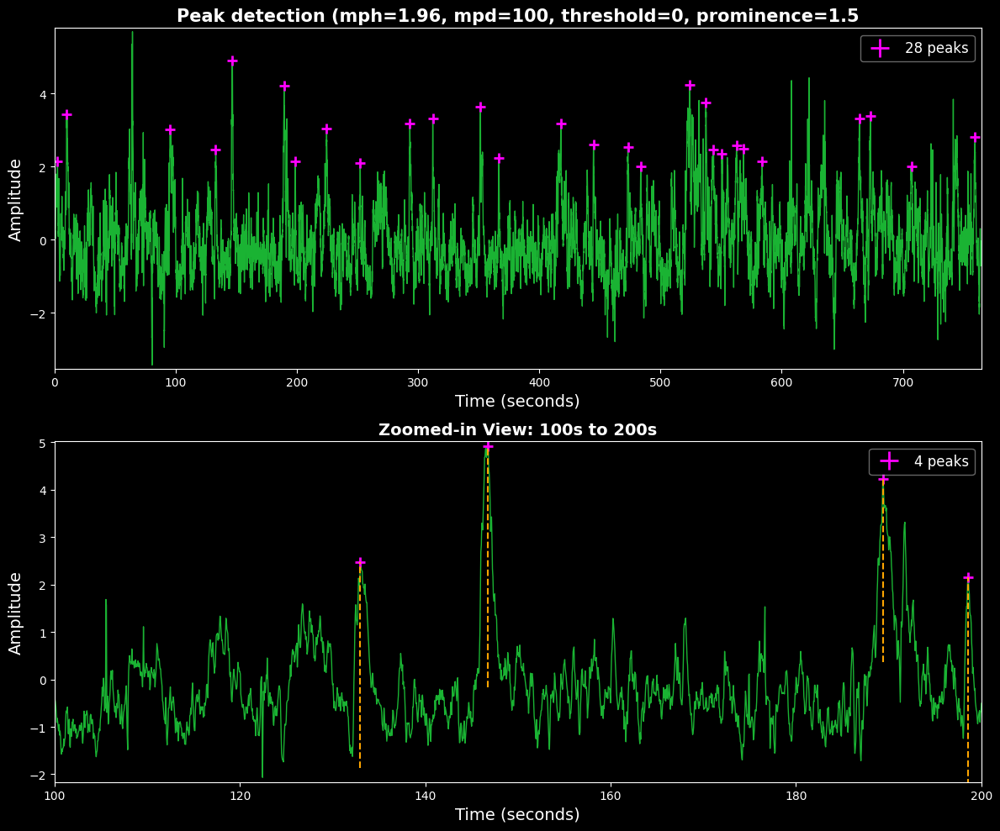

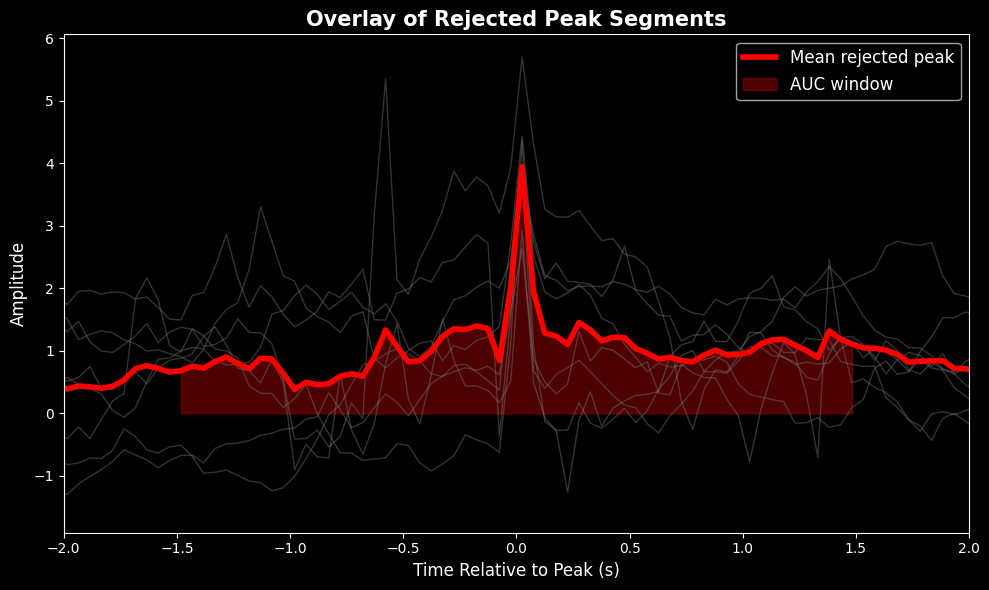

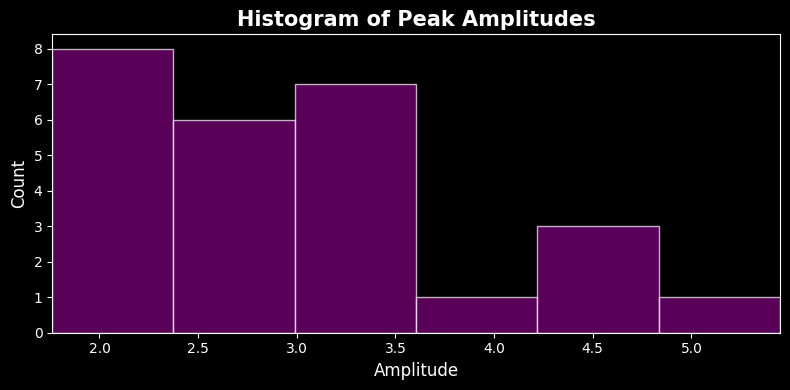

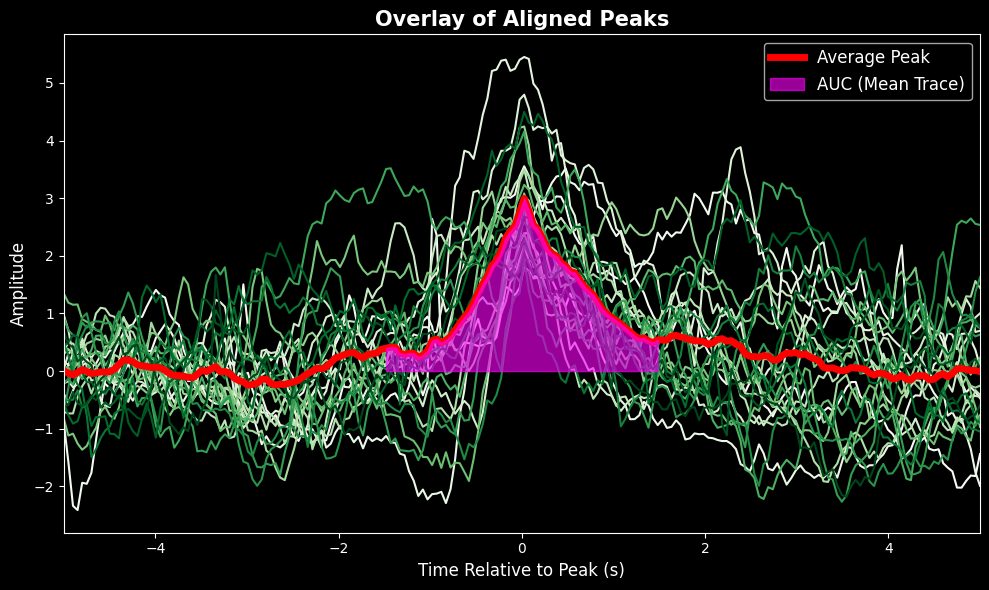


peak frequency is: 0.033998038574697624 Hz

peak amplitudes:
[3.06491189 3.5529627  1.81021705 5.44913569 4.79507212 2.39131188
 3.50777053 2.17231896 3.03656262 3.48723562 4.24390558 2.82244263
 3.08207146 2.37844453 3.23073377 1.93524986 4.15454723 2.78284351
 1.76029995 2.17399159 2.58451545 1.95490586 2.28020753 4.49665944
 2.03918315 2.67425139]

mean and SEM of peak amplitudes: 2.9946827686735724 +- 0.19338217073027336

🧪 Running perievent analysis for data type: GCaMP
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.
  ▶ Event: available_unavailable (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.

🧪 Running perievent analysis for data type: isosbestic
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one 

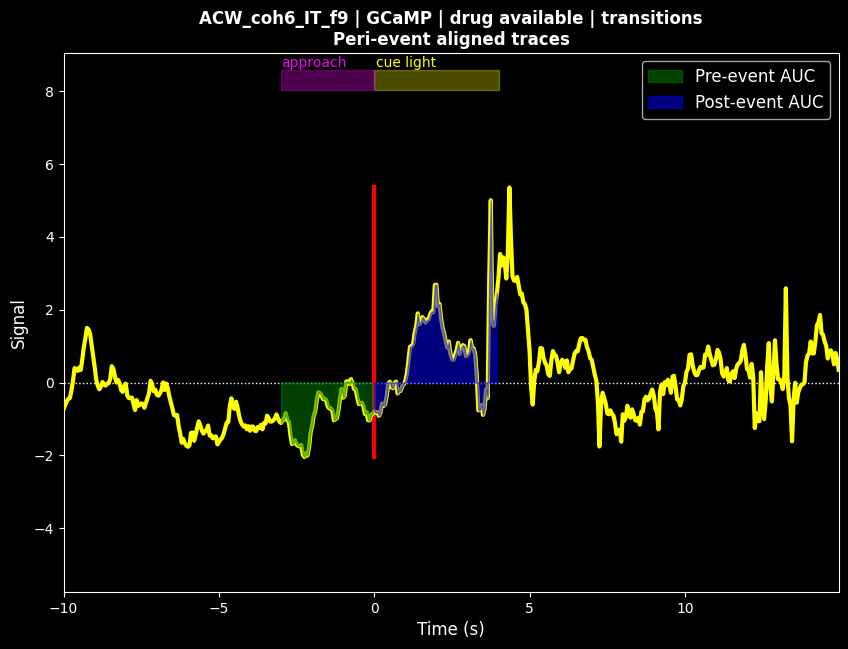

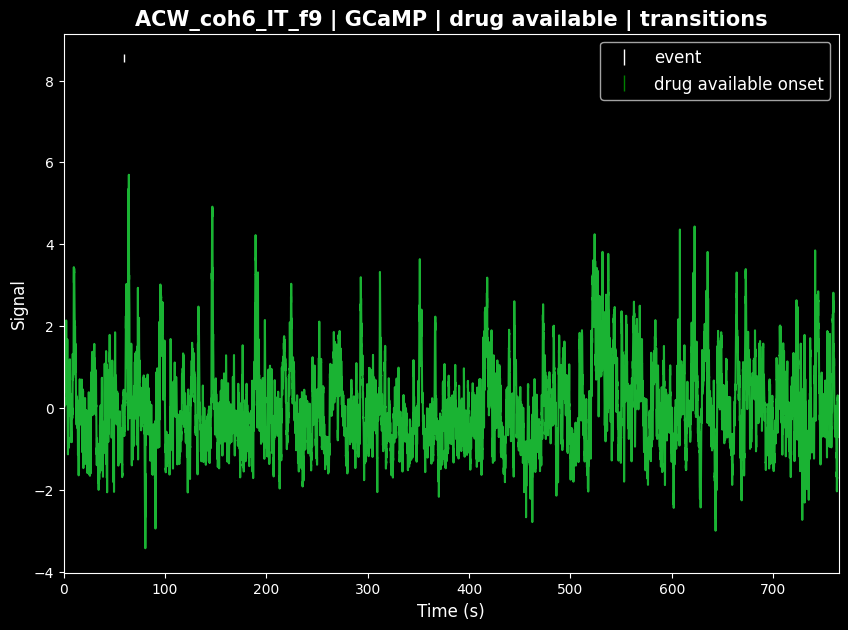

GCaMP | Event: available_unavailable


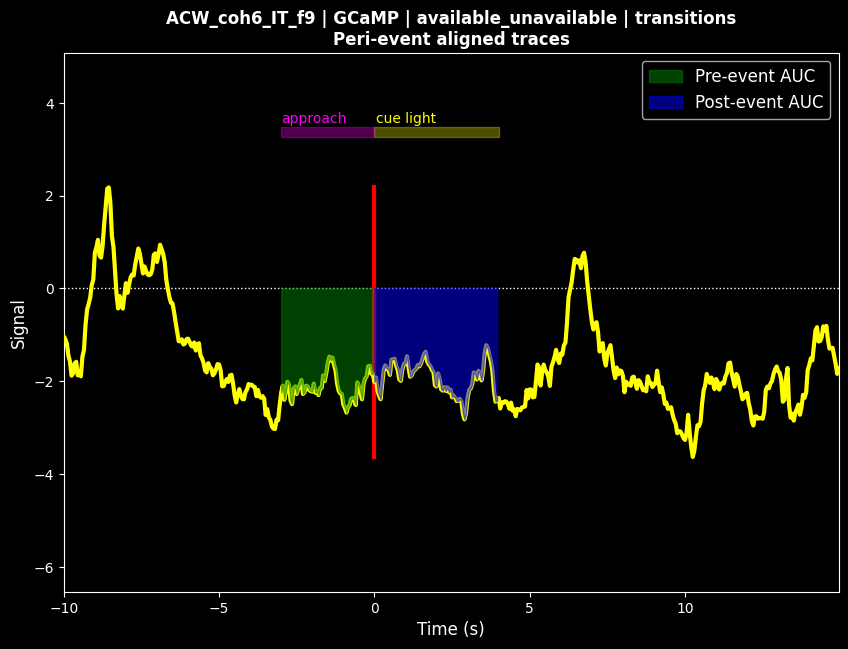

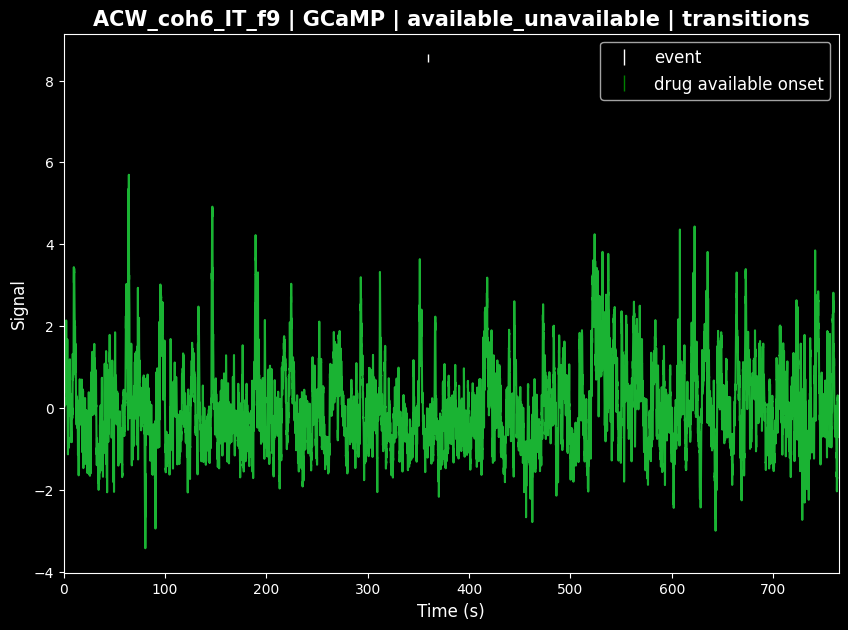

isosbestic | Event: drug available


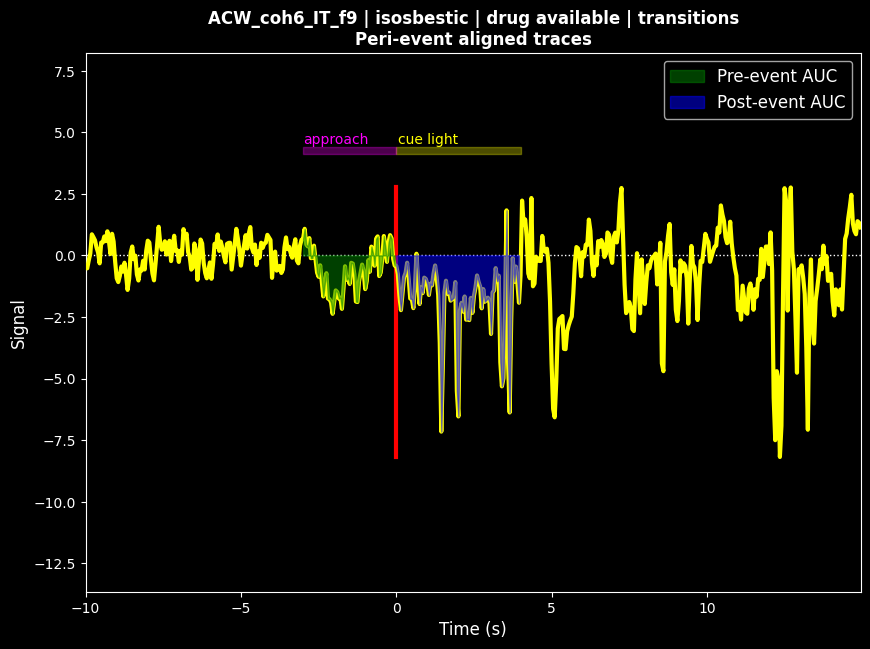

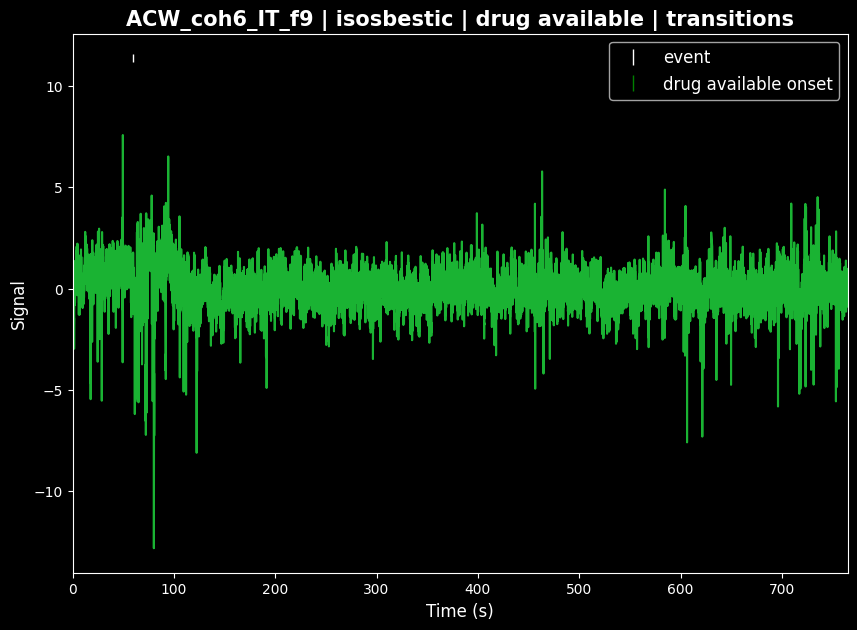

isosbestic | Event: available_unavailable


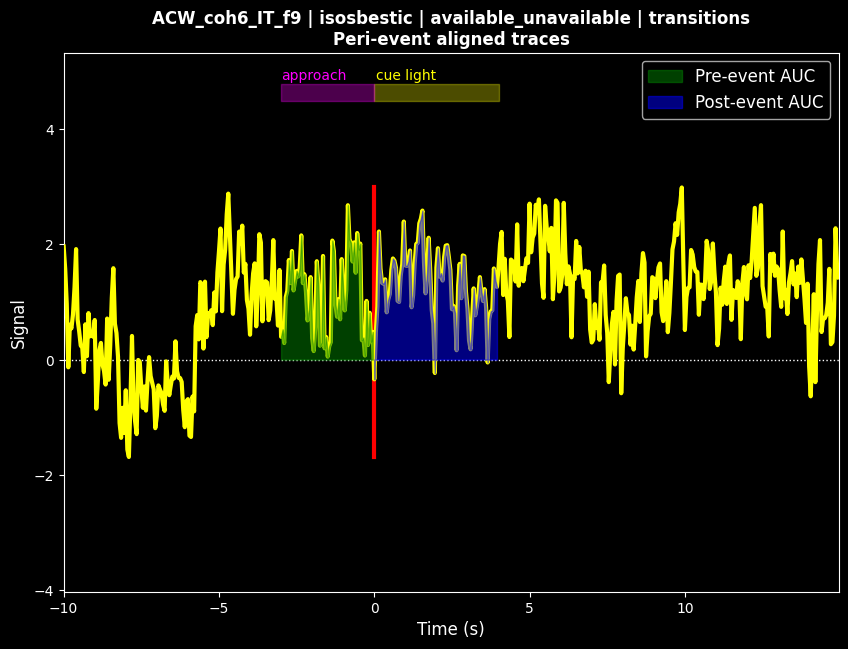

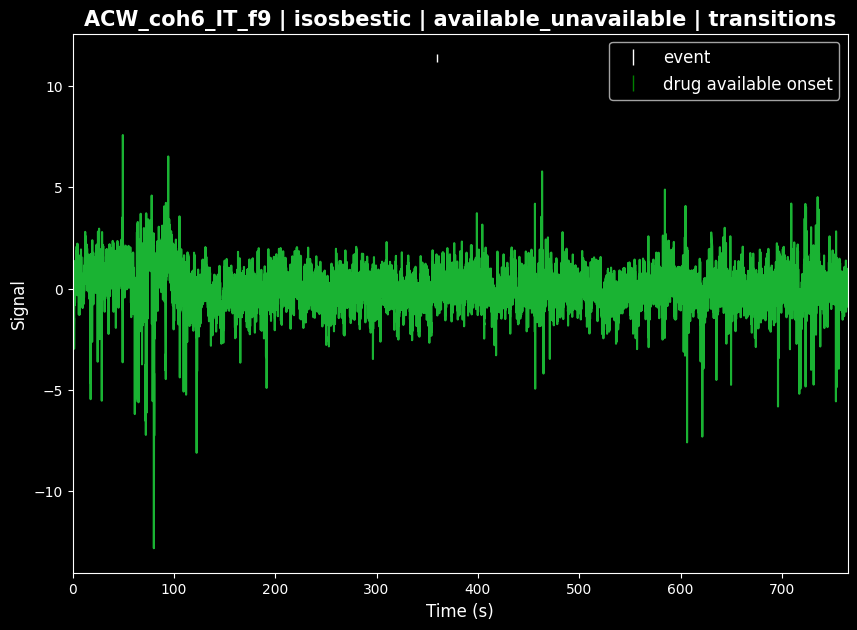

- GCaMP/
  - drug available/
    - epocs: DataFrame
    - epocs_baselined: DataFrame
    - epocs_mean_std_sem: DataFrame
    - mean_trace: ndarray
    - std_trace: ndarray
    - sem_trace: ndarray
    - events_info: DataFrame
    - fig_5: Figure
    - fig_15: Figure
    - subset_figs: NoneType
    - event_parameters/
      - rat: str
      - data type: str
      - preprocessed data stream: str
      - event type examined: str
      - event count: int
      - trange: list
      - baseline_trange: list
      - subset: NoneType
      - approach window: str
      - mean approach response: str
      - SEM approach response: str
      - cue window: str
      - mean cue response: str
      - SEM cue response: str
      - pre-event AUC window: str
      - mean pre-event AUC: str
      - SEM pre-event AUC: str
      - post-event AUC window: str
      - mean post-event AUC: str
      - SEM post-event AUC: str
    - n_events: int64
  - available_unavailable/
    - epocs: DataFrame
    - epocs_bas

,blockname,nickname,channel_raw,channel_name,fs,device_start_time,device_stop_time
0,ACW_coh6d_102226_0003,ACW_coh6_IT_f10,Headstage01LockIn01,Headstage01_470nm,100,10:40:30.189,10:57:24.266
1,ACW_coh6d_102226_0003,ACW_coh6_IT_f10,Headstage01LockIn02,Headstage01_415nm,100,10:40:30.189,10:57:24.266
2,ACW_coh6d_102226_0003,ACW_coh6_IT_f9,Headstage02LockIn01,Headstage02_470nm,100,10:40:30.189,10:57:24.266
3,ACW_coh6d_102226_0003,ACW_coh6_IT_f9,Headstage02LockIn02,Headstage02_415nm,100,10:40:30.189,10:57:24.266


,blockname,channel_raw,channel_name,nickname,time,raw_au
0,ACW_coh6d_102226_0003,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.314617,0.061376
1,ACW_coh6d_102226_0003,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.324617,0.061367
2,ACW_coh6d_102226_0003,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.334617,0.061269
3,ACW_coh6d_102226_0003,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.344617,0.061165
4,ACW_coh6d_102226_0003,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.354617,0.061139
...,...,...,...,...,...,...
402731,ACW_coh6d_102226_0003,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1014.134001,0.006911
402732,ACW_coh6d_102226_0003,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1014.144001,0.009336
402733,ACW_coh6d_102226_0003,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1014.269201,0.009260
402734,ACW_coh6d_102226_0003,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1014.279201,0.006797


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,402.892
1,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,14.477
2,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,14.627
3,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,50.438
4,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,53.668
5,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,55.048
6,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,427.413
7,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,428.753
8,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,652.793
9,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO15,D15 Raw_InactiveLever_box3,66.669


Moved ACW_coh6d_102226_0003_streams_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0003_streams_info.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0003_epocs_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
File not found, skipping: ACW_coh6d_102226_0003_epocs_info.feather
🔍 Detected format: Doric
⚠️ Missing expected channels for BOX2 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX4 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX5 (ACW_coh5_IT_). Skipping.

✅ Found photometry data for boxes: BOX3



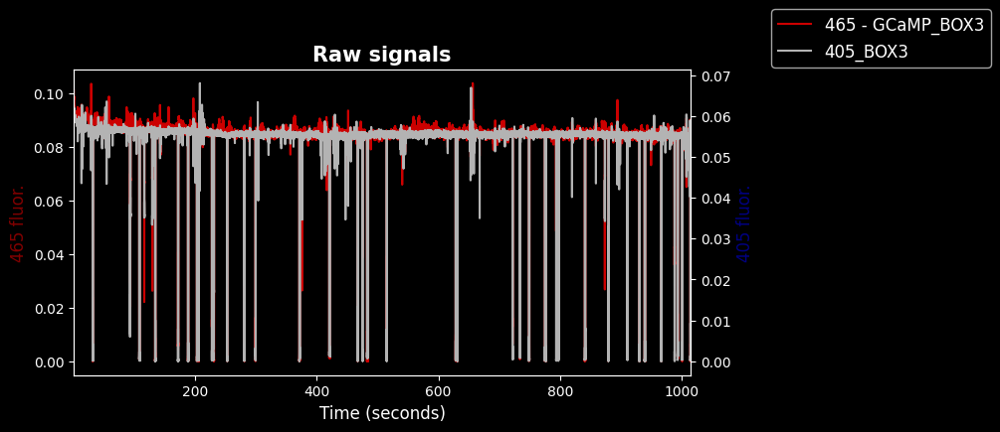

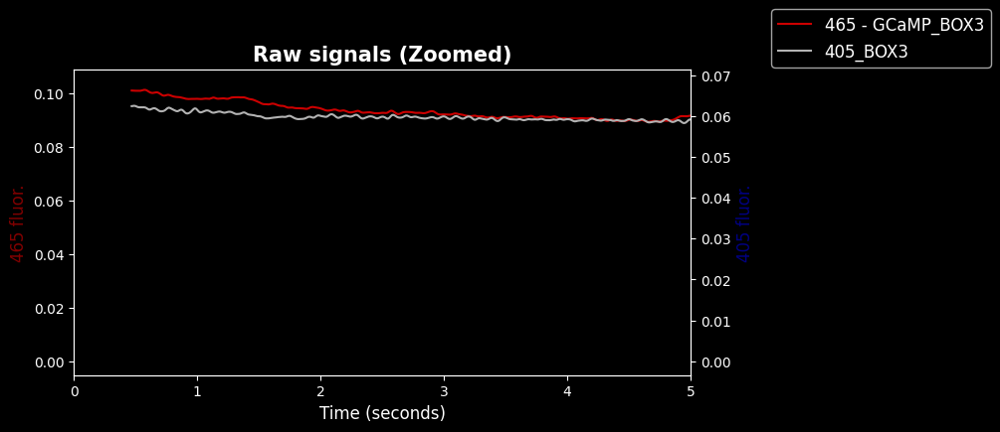

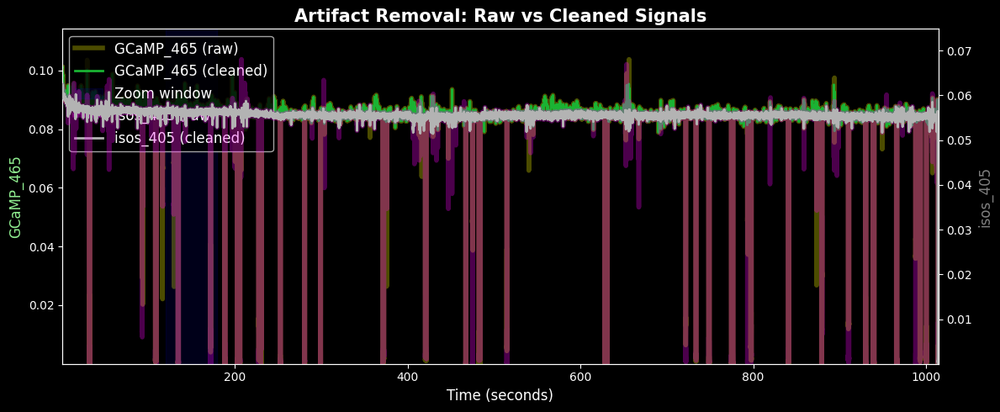

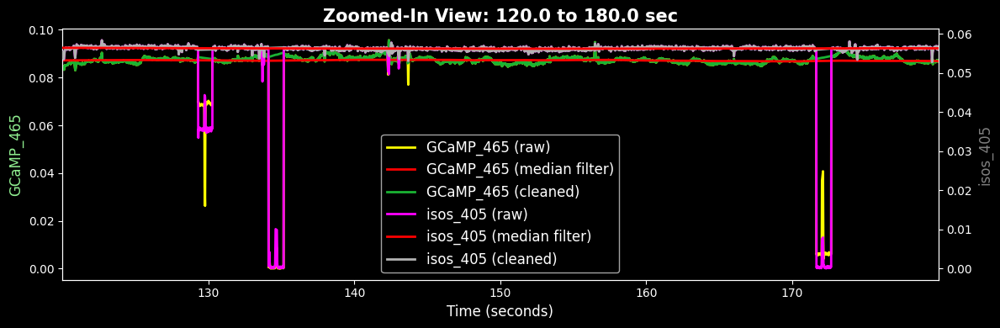

20.0


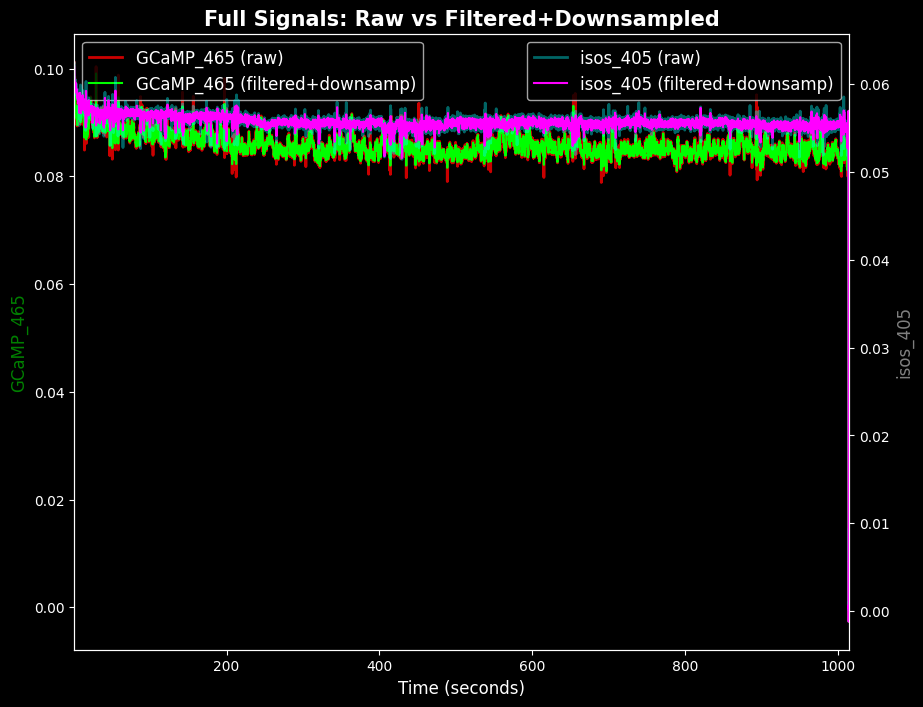

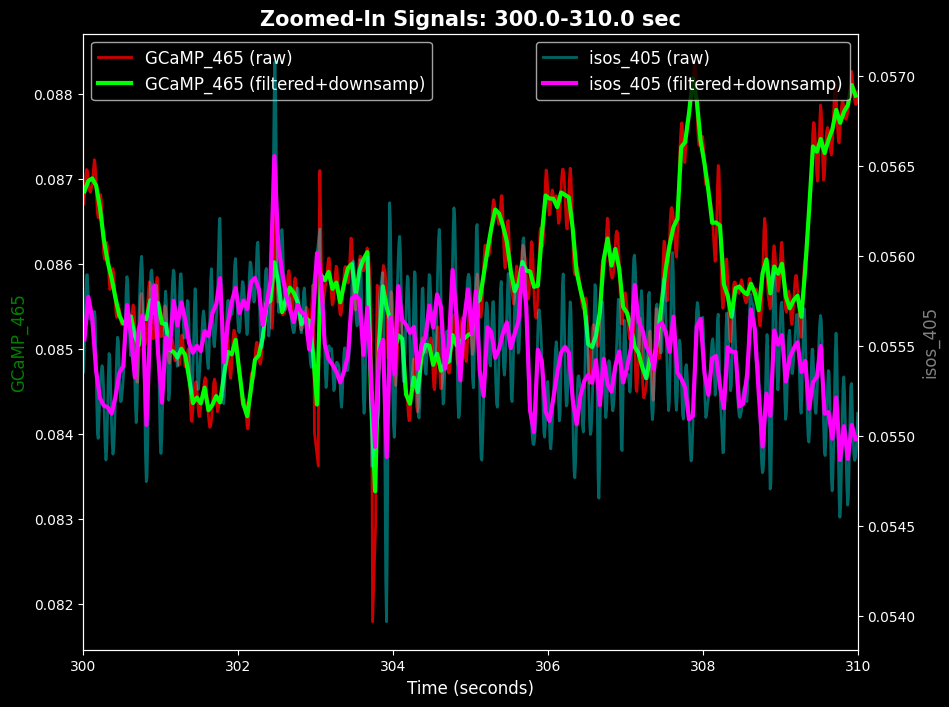

isos_405 length: 99964
isos_405_downsamp length: 20277
GCaMP_465 length: 99964
GCaMP_465_downsamp length: 20277
ts_all length: 99964
ts_downsamp length: 20277

the duration of the stream data is 1014.2704009900008 seconds, aka 16.90450668316668 mins


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,402.892
1,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,14.477
2,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,14.627
3,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,50.438
4,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,53.668
5,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,55.048
6,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,427.413
7,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,428.753
8,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,652.793
9,ACW_coh6d_102226_0003,Series0001/DigitalIO/DIO15,D15 Raw_InactiveLever_box3,66.669


detected data format: Doric

📋 Unique D## codes found: ['D13' 'D14' 'D15' 'D16' 'D29' 'D30' 'D31' 'D32']
📌 dropsec_code reflects beginning of the Med Associates program
📌 dropsec_code reflects onset of drug availability

⏱ dropsec code D13 corresponds to timepoints: [402.892]

✅ Using dropsec = 402.892 seconds from epoc data.
the downsampled sampling rate is 20.0 Hz

discard the first 402.892 seconds, data points from 0 to 8057

keep a duration of 15 minutes
including to end of stream: data points 6849 to 20277

- - - - - initial vector lengths - - - - -

len(isos_405_filt_downsamp): 20277
len(ts_downsamp): 20277

start index: 6849
end index: 20277

Trimmed duration: 671.35 sec (~11.19 min) (requested 15 min, pre_buffer 0s, post_buffer 0s)

Plotting TRANSITION segment (1 min before → 1 min after available period, total 17.0 min) ...


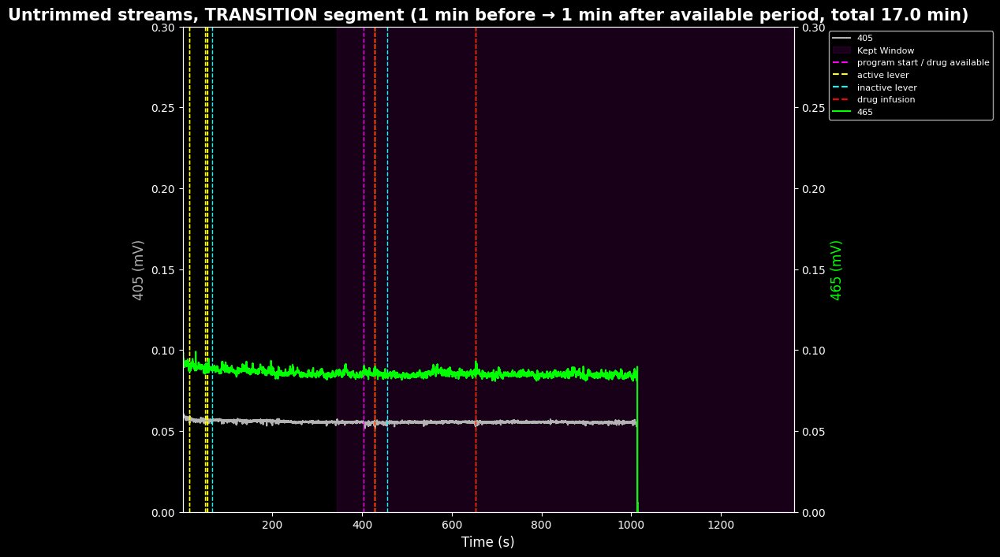

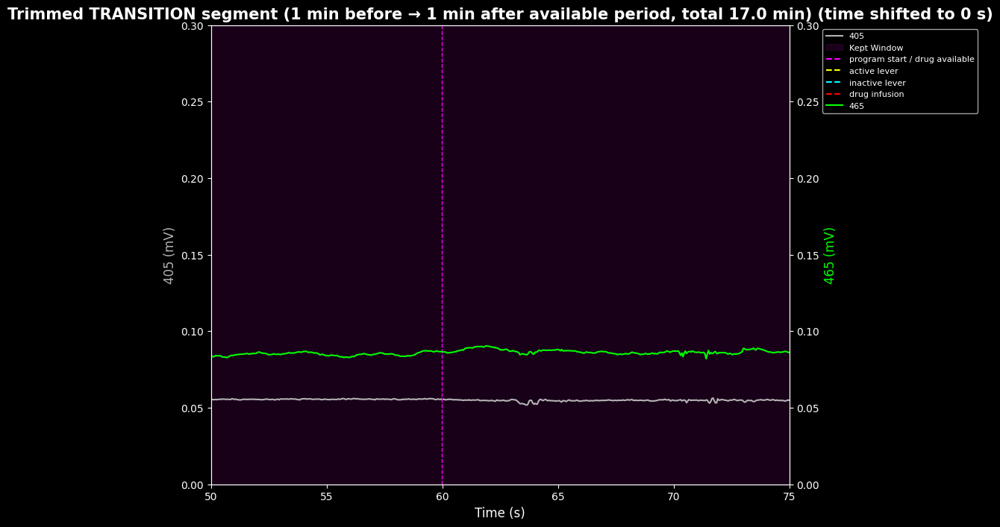

examining 15 minutes of the epoc data
the dropsec code is D13
the start code is 0
dropsec is equal to 402.892
Intermittent access self-admin epoc_ts_and_indices:


ACW_coh6_IT_f9 epoc timestamps,epoc_ts,epoc_indices,data,event
0,60.000,1200,D13,drug available
1,84.521,1690,D14,active lever
2,85.861,1717,D14,active lever
3,309.901,6198,D14,active lever
4,360.000,7199,NaN,available_unavailable
5,84.521,1690,D16,drug infusion
6,309.901,6198,D16,drug infusion
7,112.693,2253,D15,inactive lever


Detected 2 artifact segments.


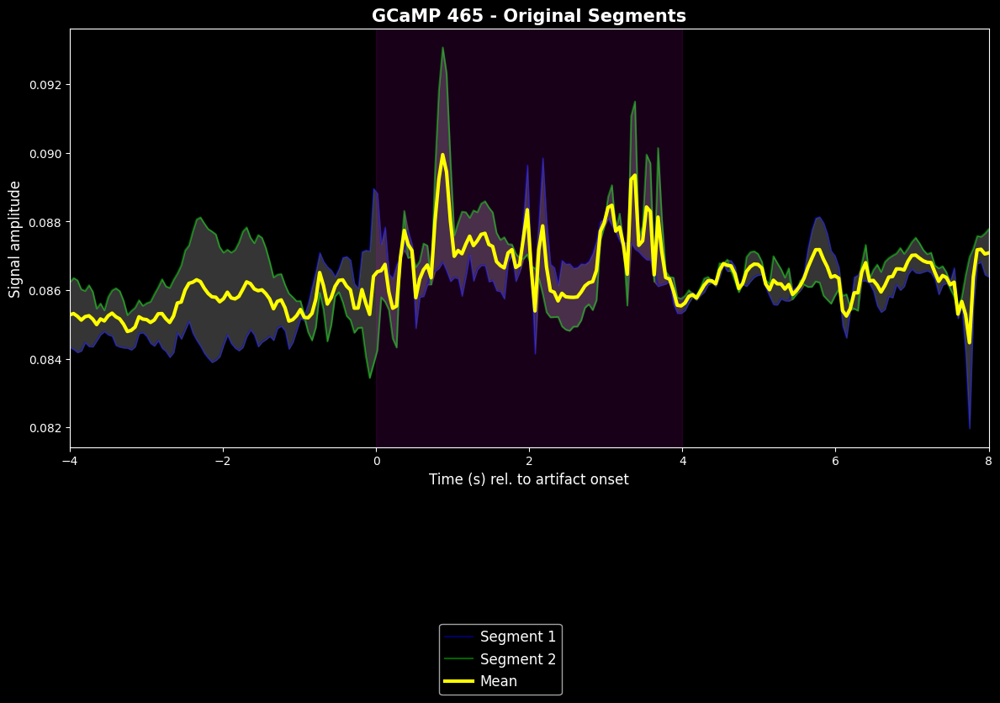

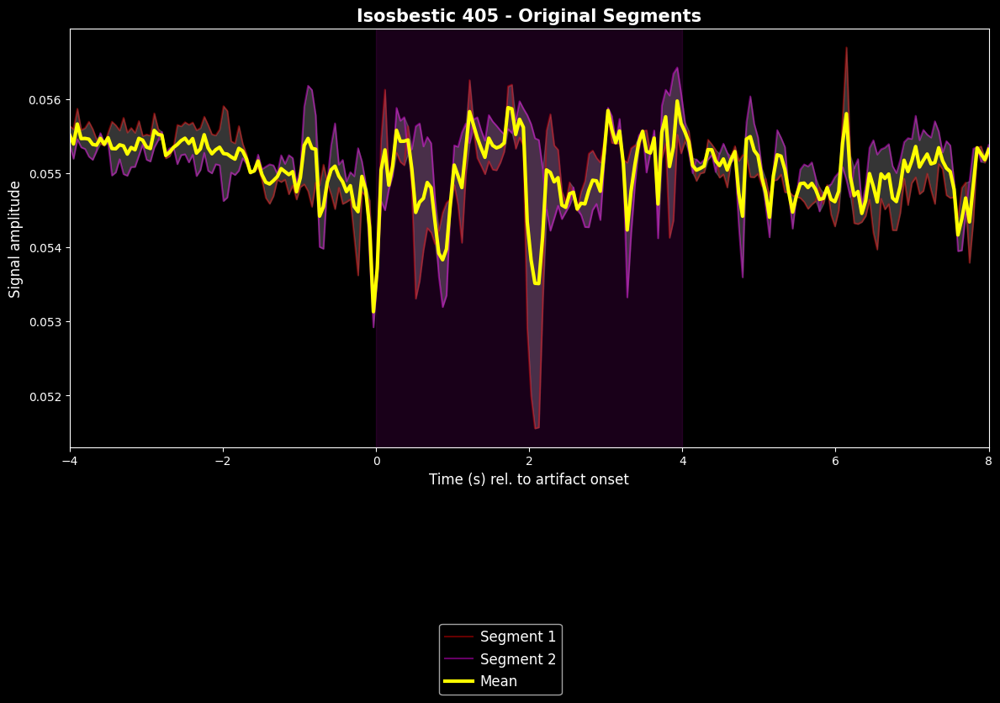

Detected 1 perievent segments.


C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:252: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


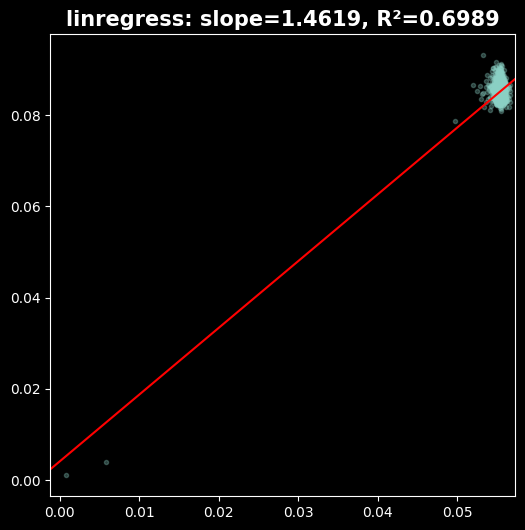

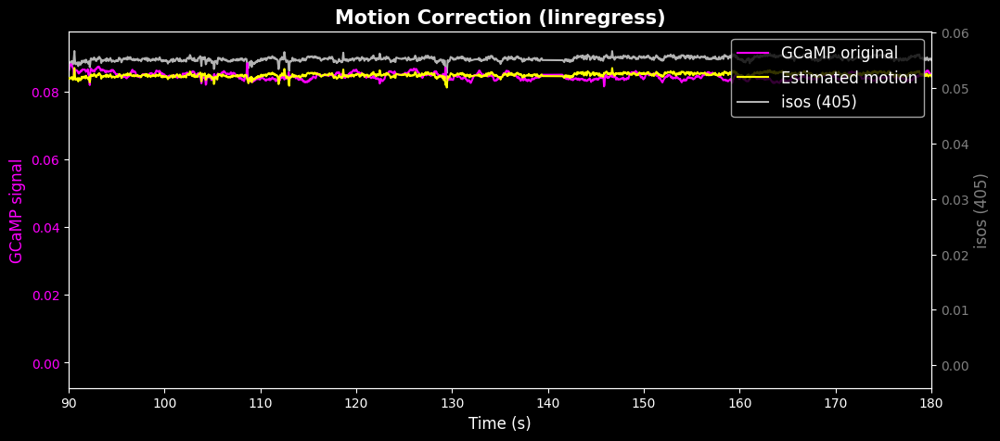

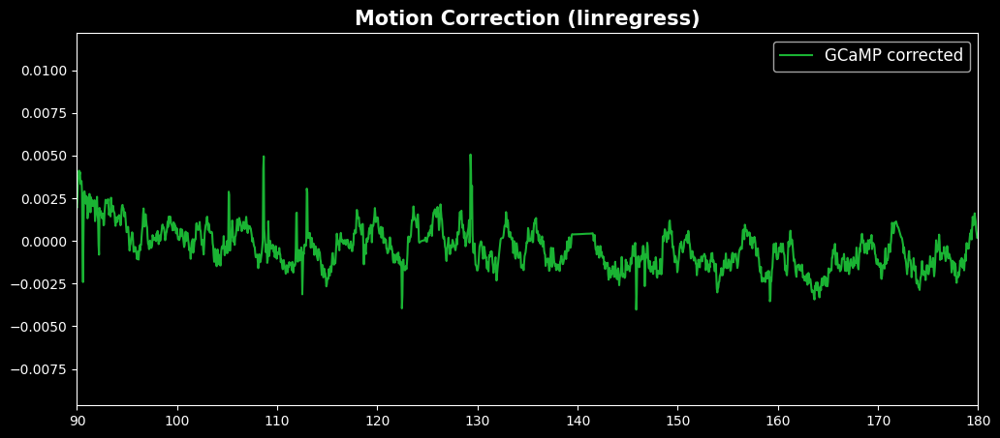

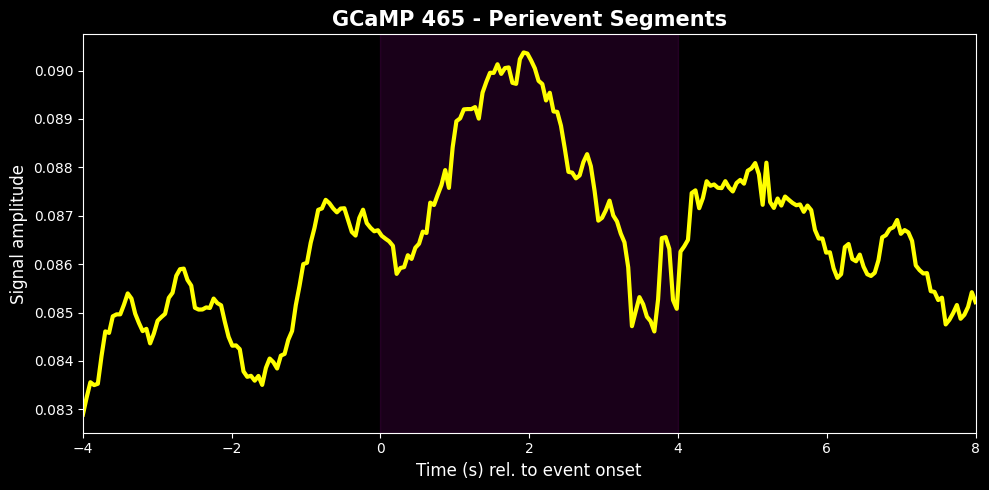

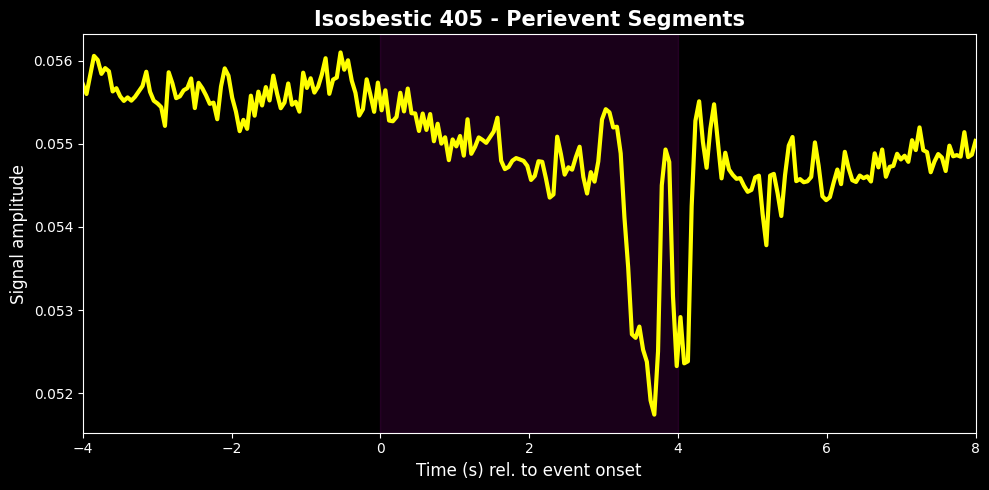

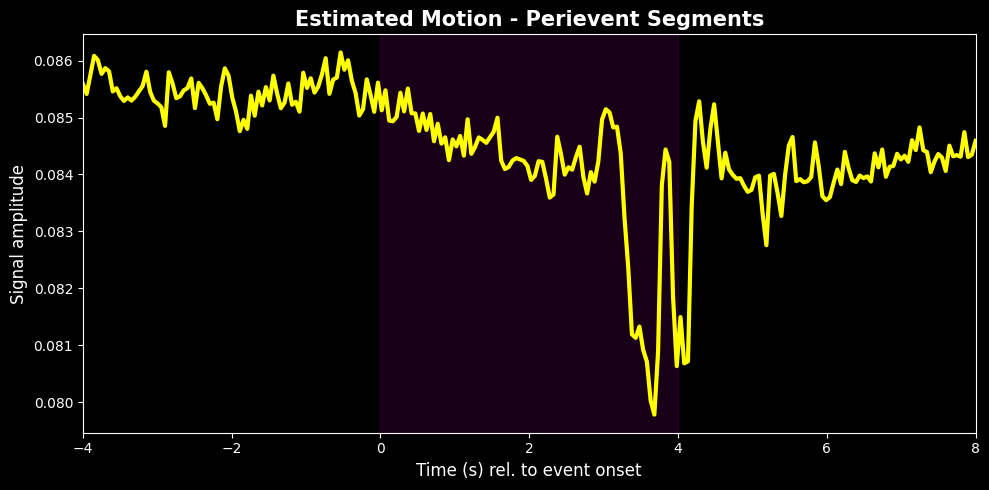

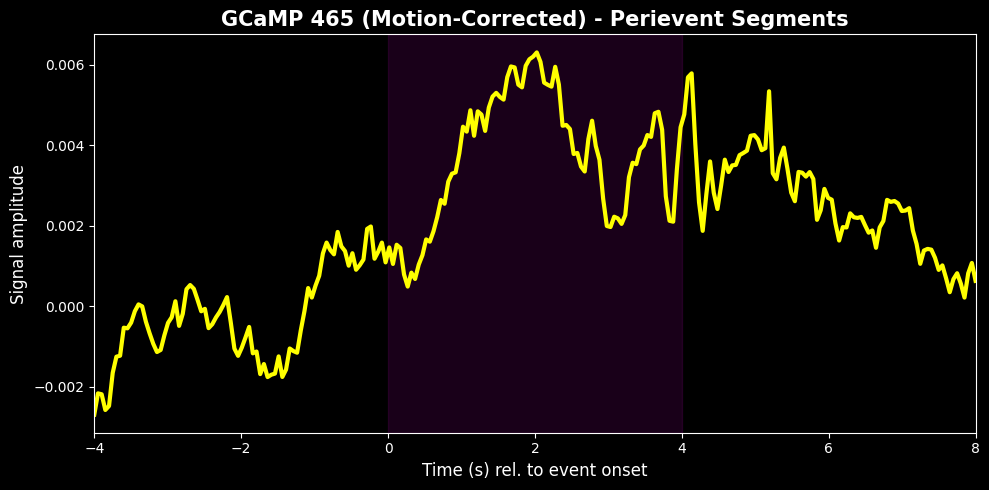

ACW_coh6_IT_f9 preprocessed streams,ts,isosbestic 405nm,"isosbestic 405nm, artifacts corrected",GCaMP 465nm,estimated motion,GCaMP 465nm motion correction,"GCaMP 465nm motion correction, exponential fit","GCaMP 465nm motion correction, exponential fit, airPLS","GCaMP 465nm motion correction, exponential fit, airPLS, z-scored","GCaMP 465nm, dF/F",isosbestic 405nm exponential fit,"isosbestic 405nm exponential fit, airPLS","isosbestic 405nm exponential fit, airPLS, z-scored"
0,0.00,0.055618,0.055618,0.084936,0.085443,-0.000507,-0.001482,-0.001434,-0.953224,-0.593817,0.000169,-0.001125,-0.324189
1,0.05,0.055645,0.055645,0.085038,0.085483,-0.000445,-0.001419,-0.001371,-0.911393,-0.520573,0.000196,-0.001097,-0.316286
2,0.10,0.055615,0.055615,0.085340,0.085439,-0.000099,-0.001073,-0.001025,-0.681187,-0.116152,0.000166,-0.001127,-0.324912
3,0.15,0.055363,0.055363,0.085807,0.085070,0.000738,-0.000235,-0.000187,-0.124513,0.867130,-0.000087,-0.001380,-0.397744
4,0.20,0.055643,0.055643,0.085769,0.085479,0.000290,-0.000683,-0.000635,-0.421854,0.339008,0.000193,-0.001100,-0.317080
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13423,671.15,0.000322,0.000322,0.000200,0.004606,-0.004406,-0.004407,-0.003631,-2.413696,-95.654946,-0.054936,-0.042724,-12.312807
13424,671.20,0.003985,0.003985,0.002826,0.009961,-0.007136,-0.007136,-0.006361,-4.227926,-71.632289,-0.051272,-0.039059,-11.256630
13425,671.25,0.005751,0.005751,0.003903,0.012543,-0.008640,-0.008641,-0.007865,-5.228087,-68.886282,-0.049506,-0.037292,-10.747366
13426,671.30,0.005701,0.005701,0.003918,0.012470,-0.008552,-0.008552,-0.007776,-5.169074,-68.577476,-0.049556,-0.037341,-10.761502


r = 0.5865
slope = 0.1702
intercept = 0.0115
R² = 0.3440
Correlation between z(dF/F) and z-score = 0.5865
🚫 Rejected 13 artifactual peaks


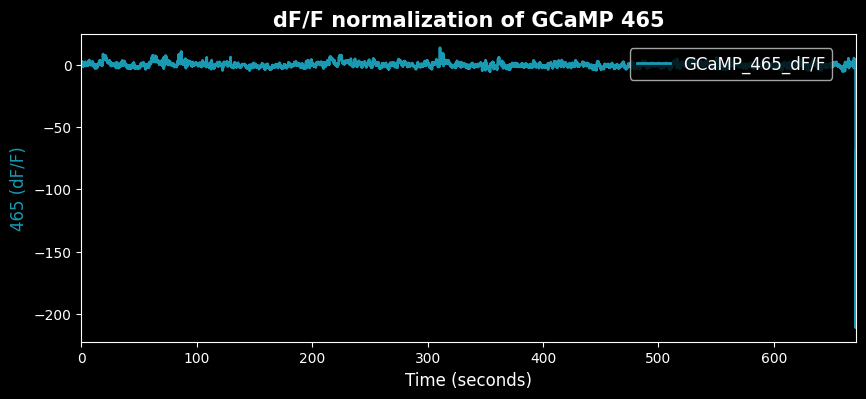

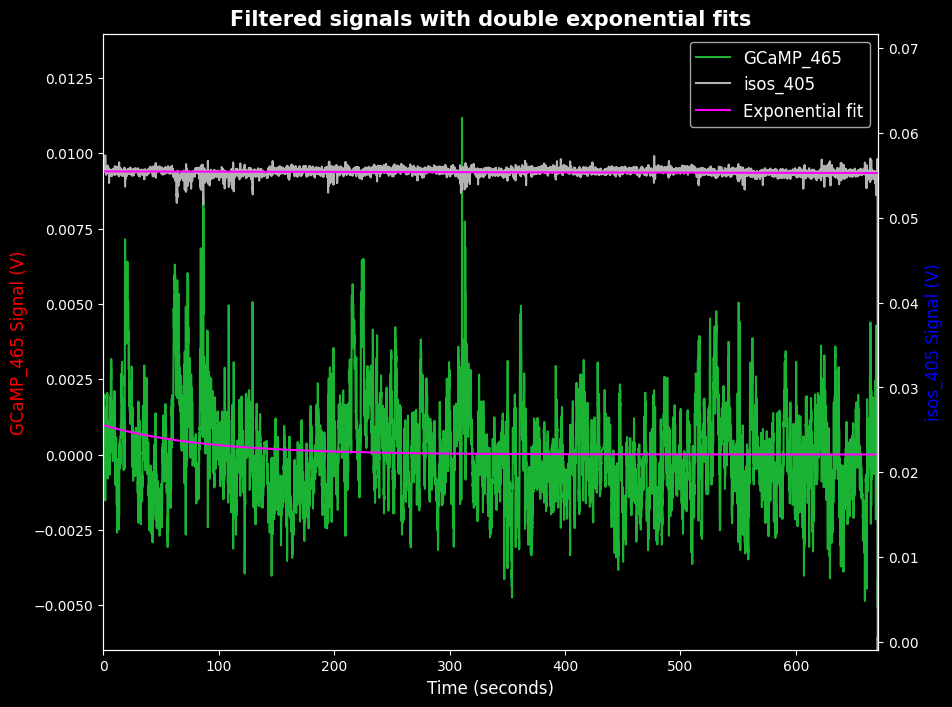

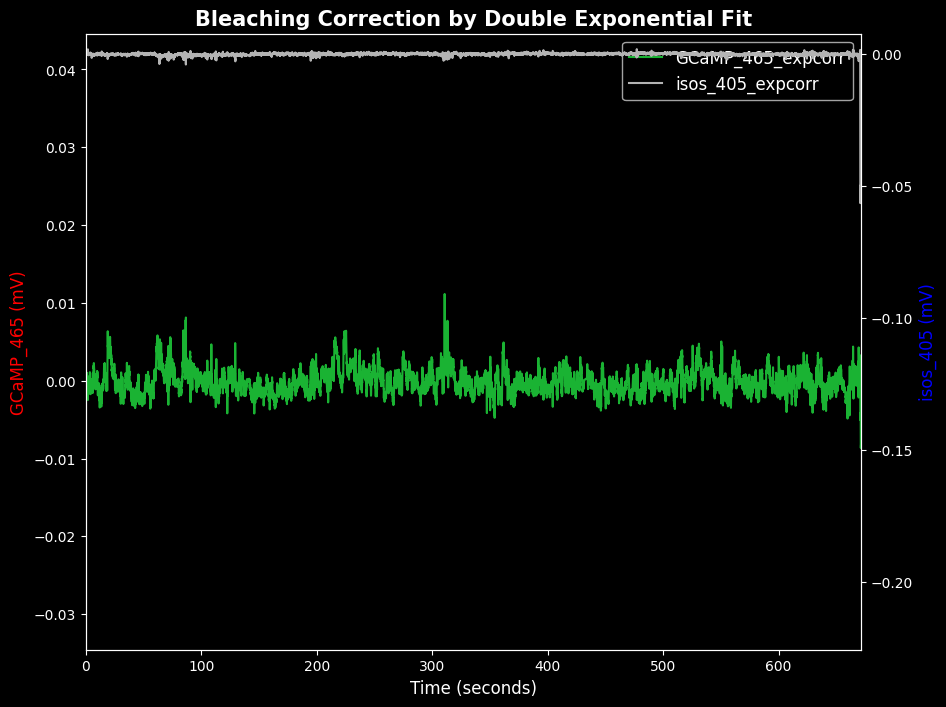

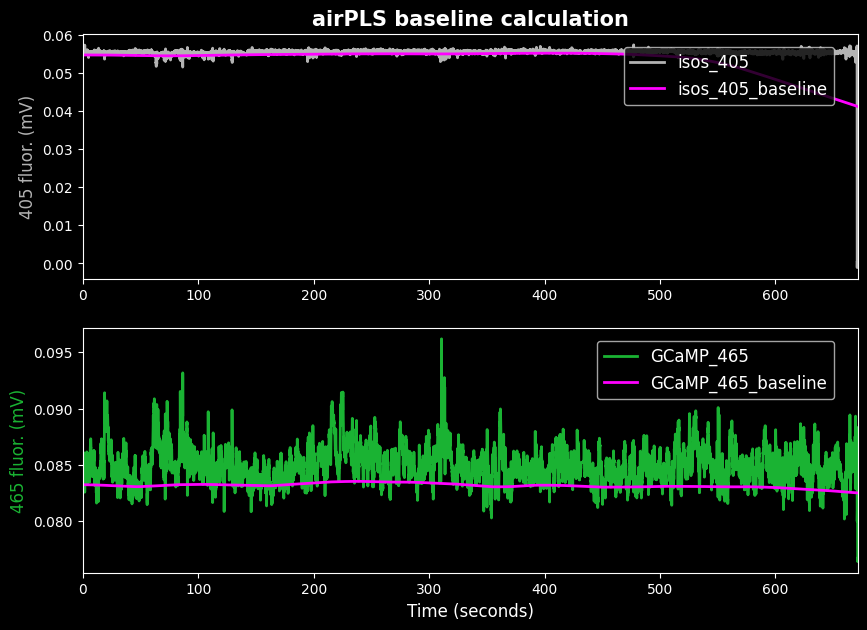

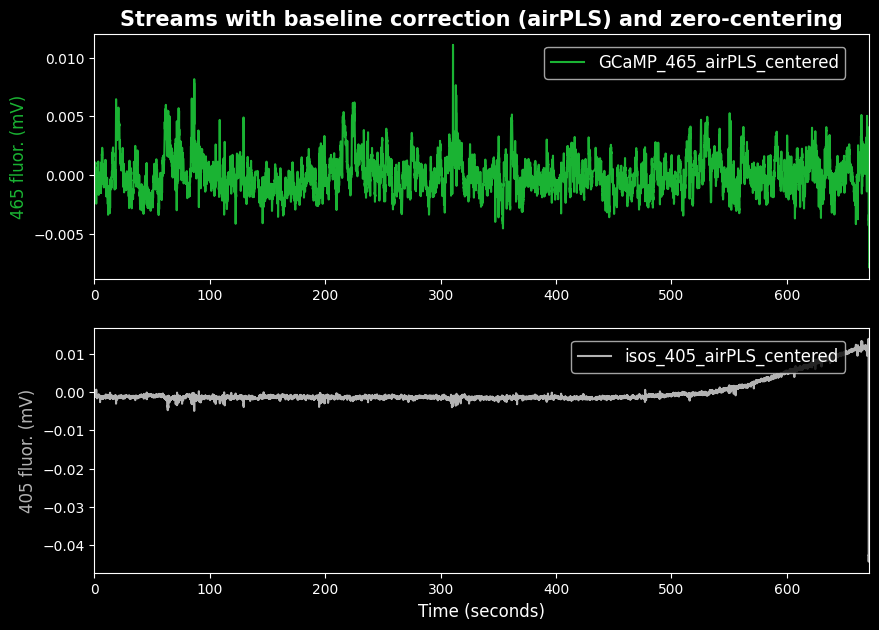

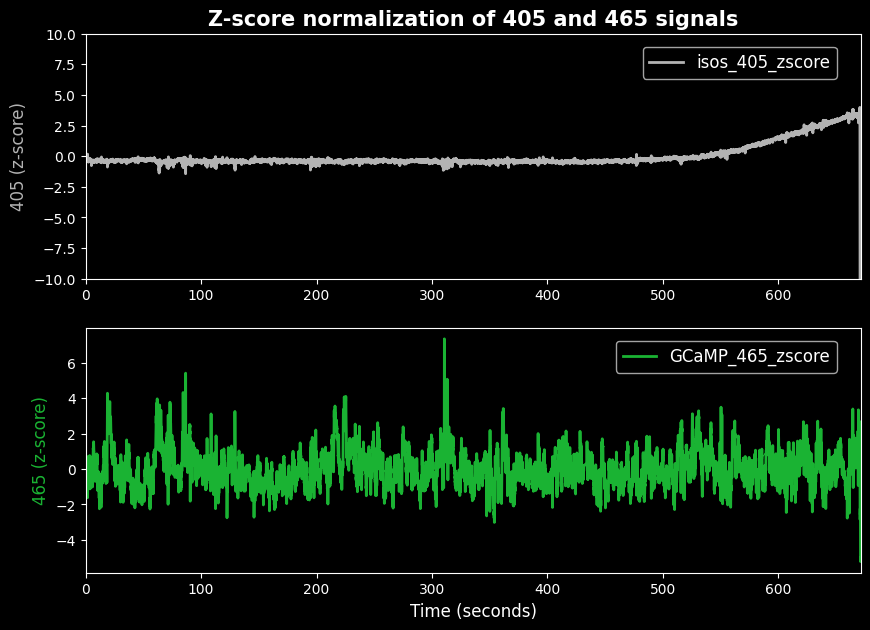

<Figure size 1000x700 with 0 Axes>

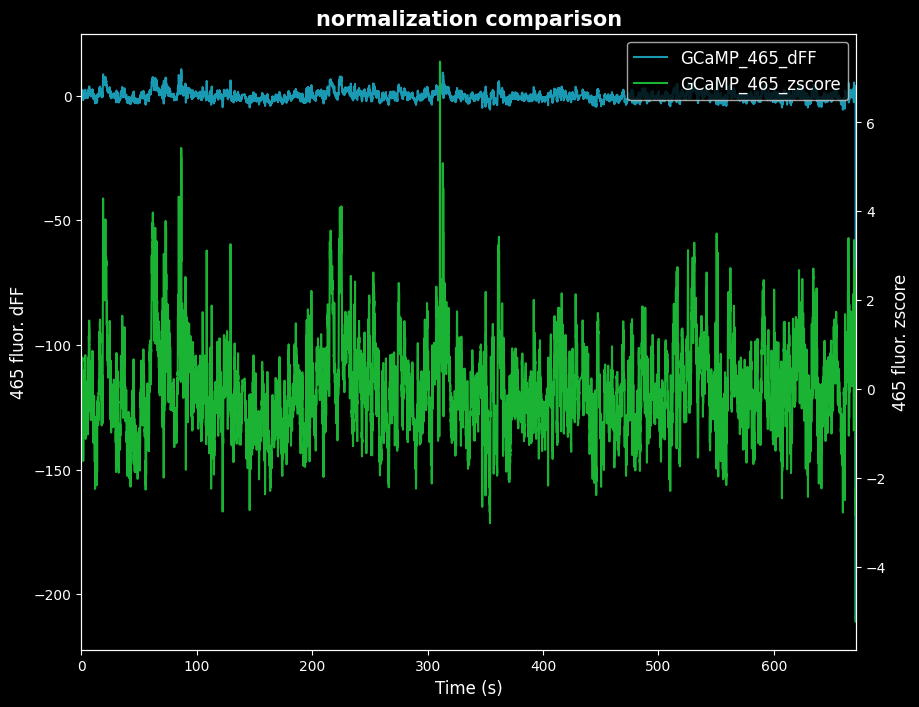

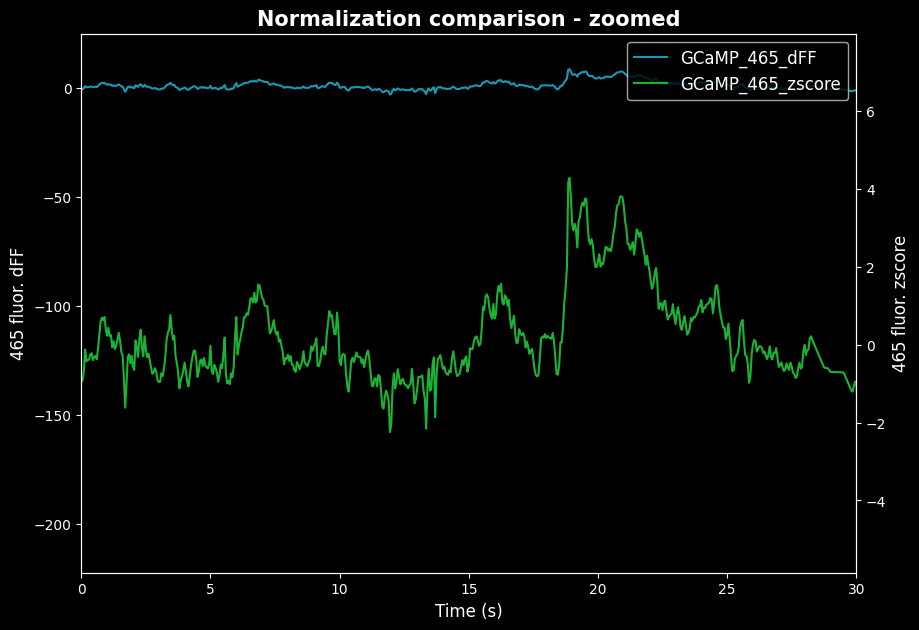

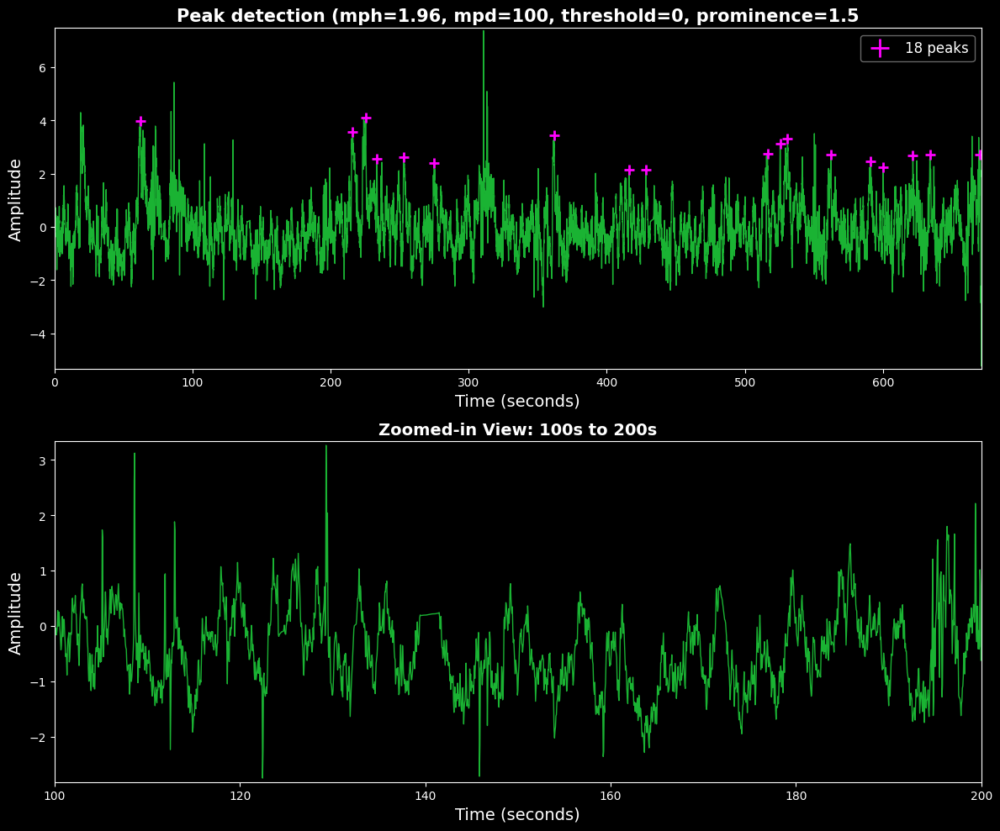

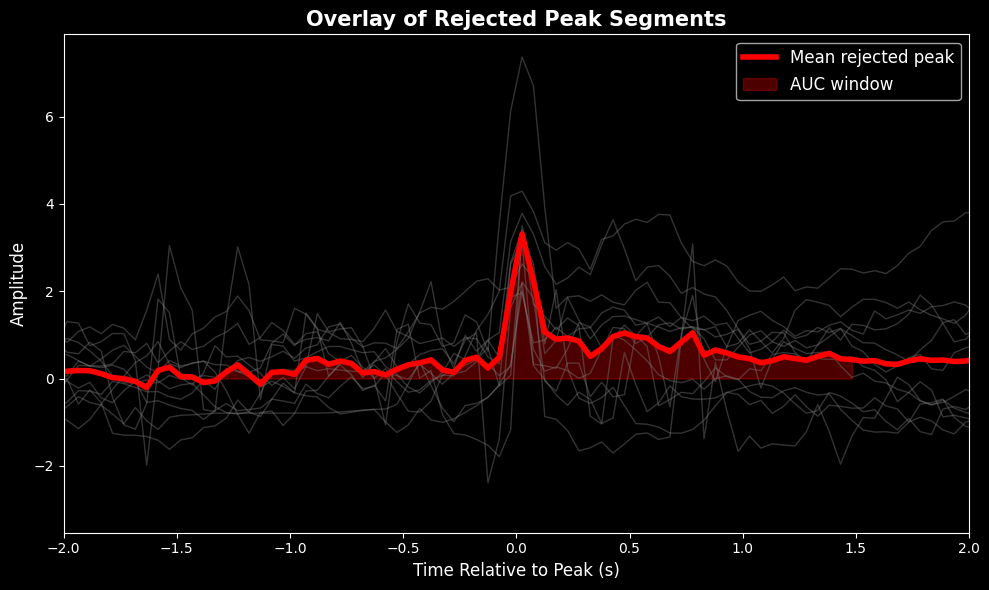

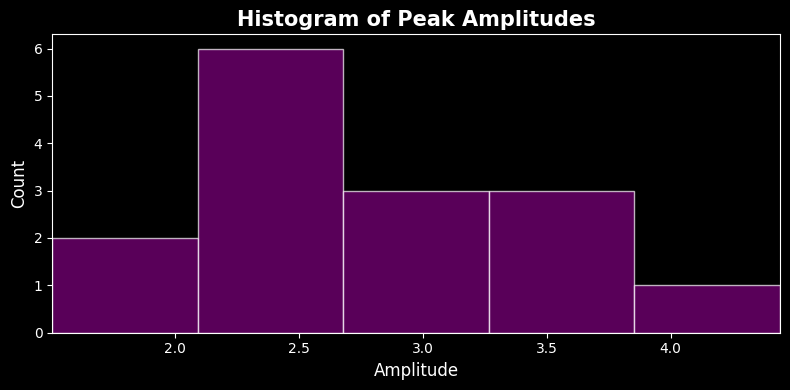

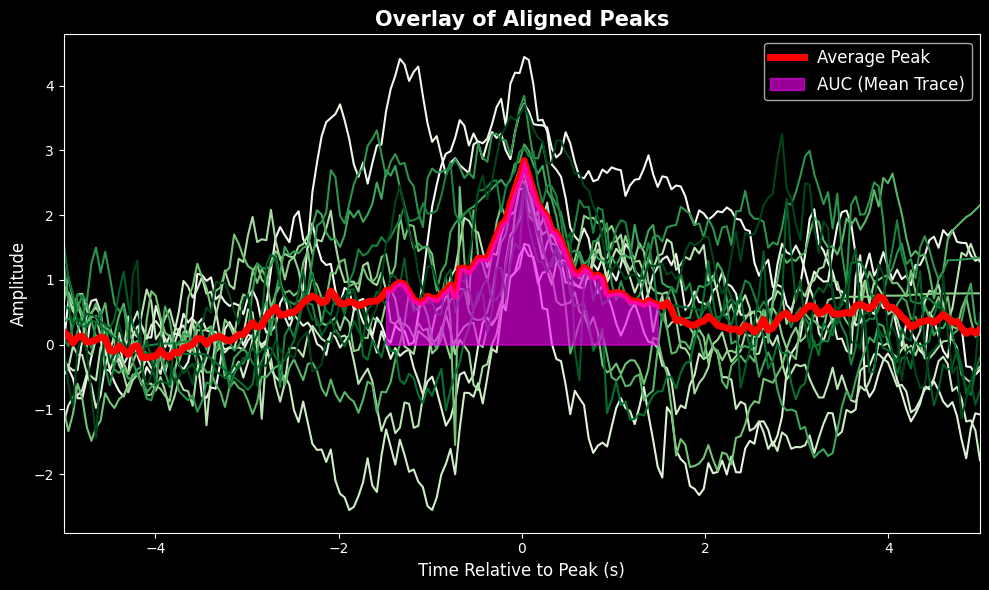


peak frequency is: 0.02234304014299544 Hz

peak amplitudes:
[3.71822768 4.44110311 1.50533509 1.55605942 2.4101784  2.40136377
 2.66673688 2.52592521 2.80720506 3.09287686 3.84087539 3.04207911
 2.46829771 2.44739552 3.69889107]

mean and SEM of peak amplitudes: 2.8415033520321087 +- 0.21166045166396127

🧪 Running perievent analysis for data type: GCaMP
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.
  ▶ Event: available_unavailable (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.

🧪 Running perievent analysis for data type: isosbestic
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.
  ▶ Eve

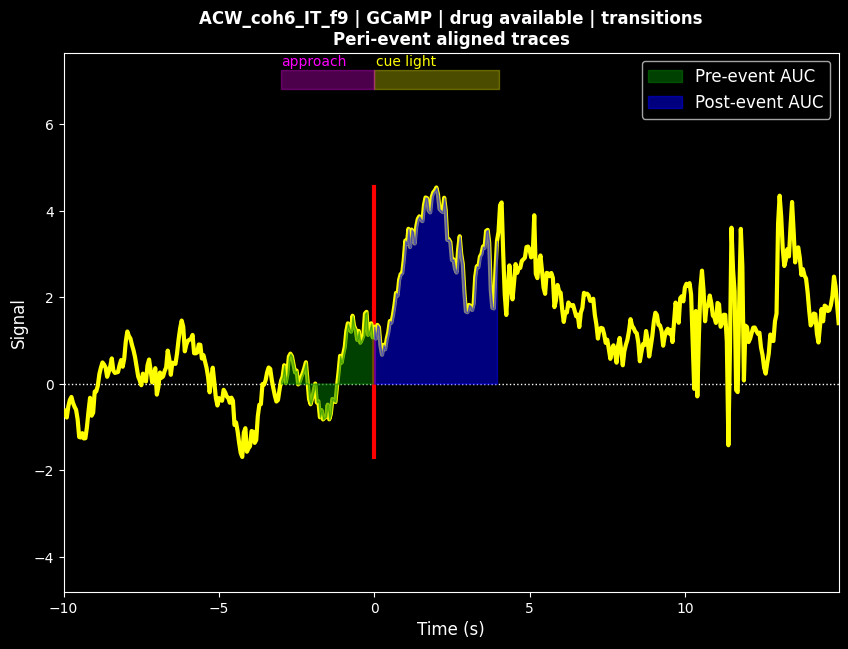

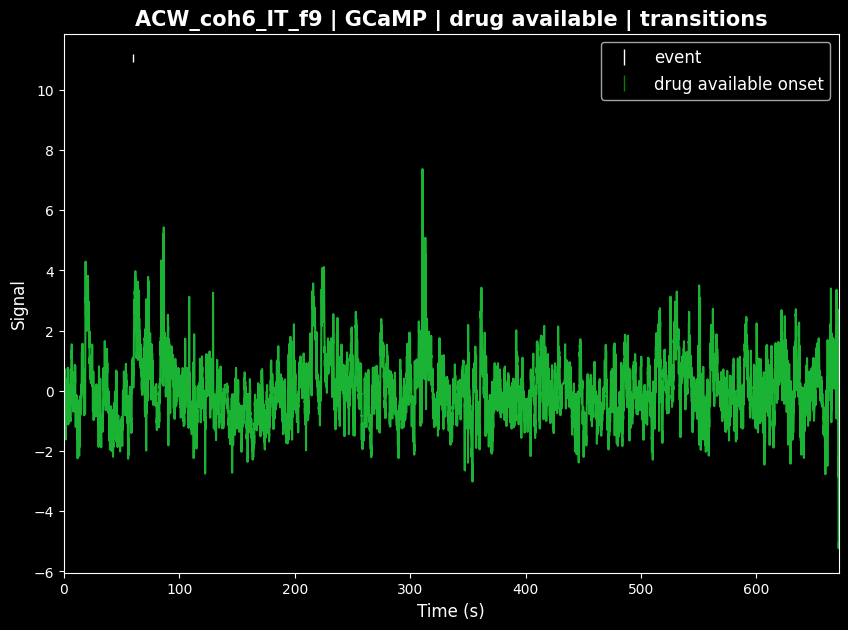

GCaMP | Event: available_unavailable


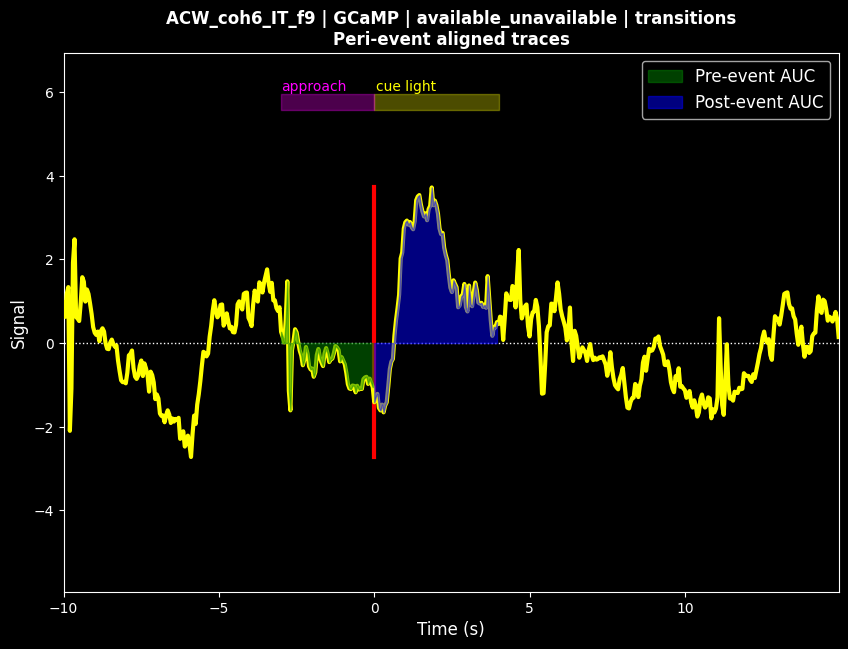

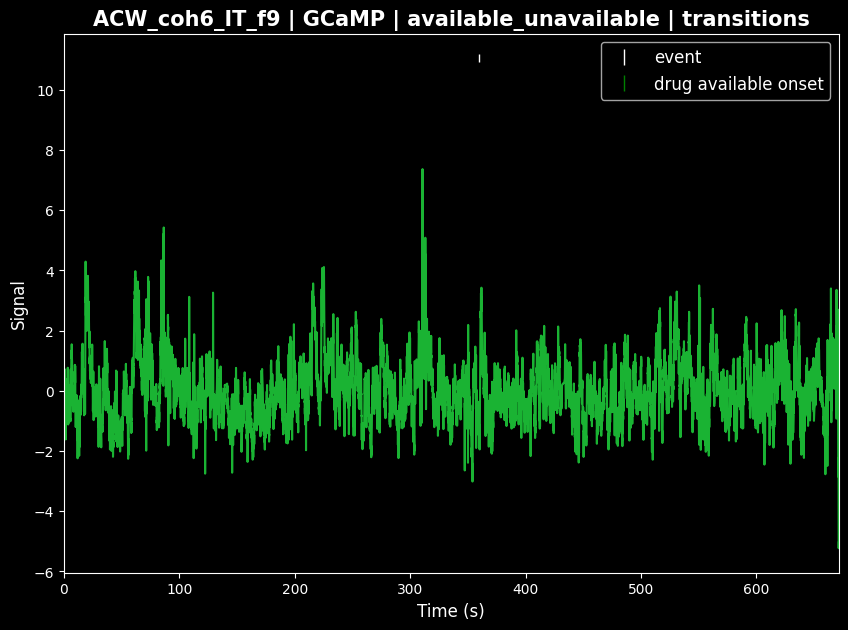

isosbestic | Event: drug available


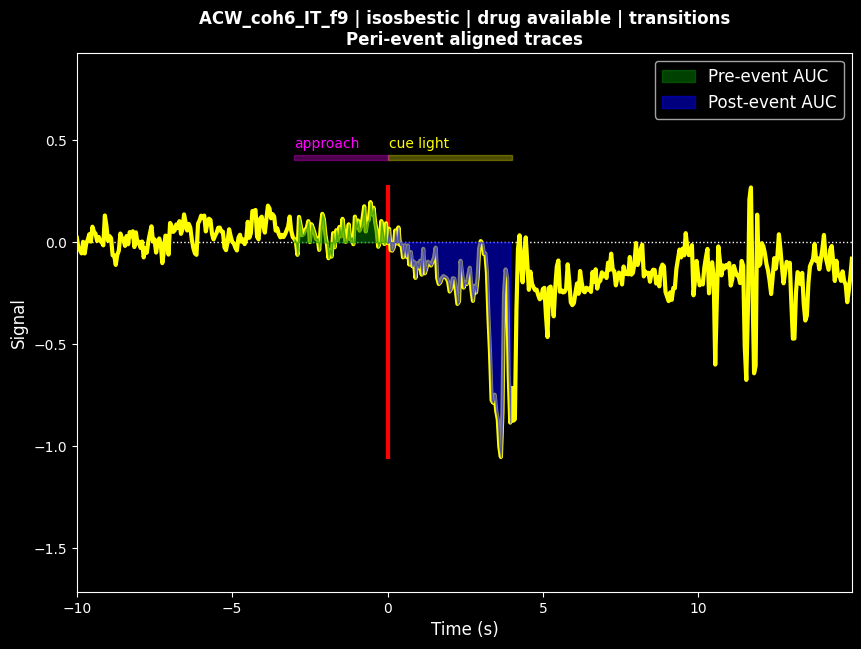

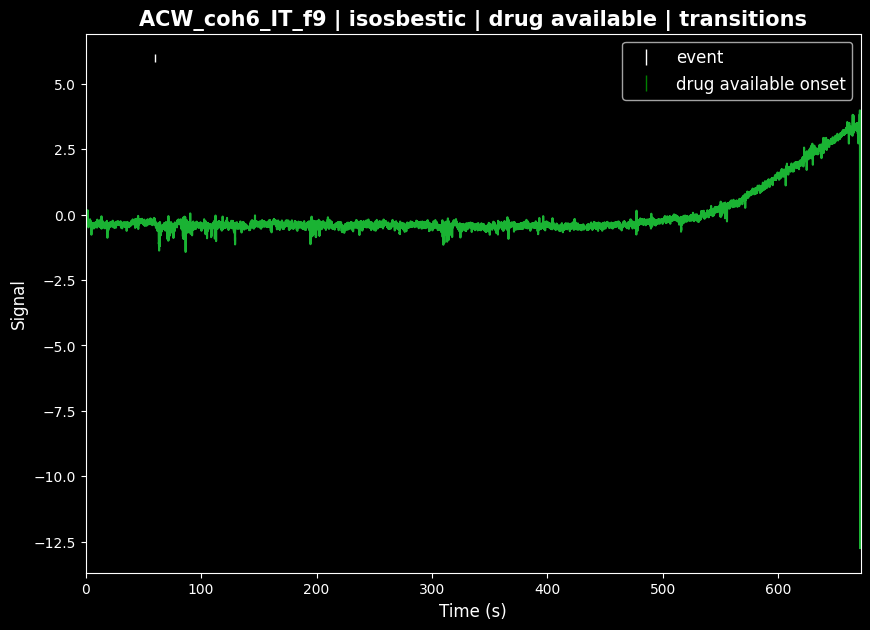

isosbestic | Event: available_unavailable


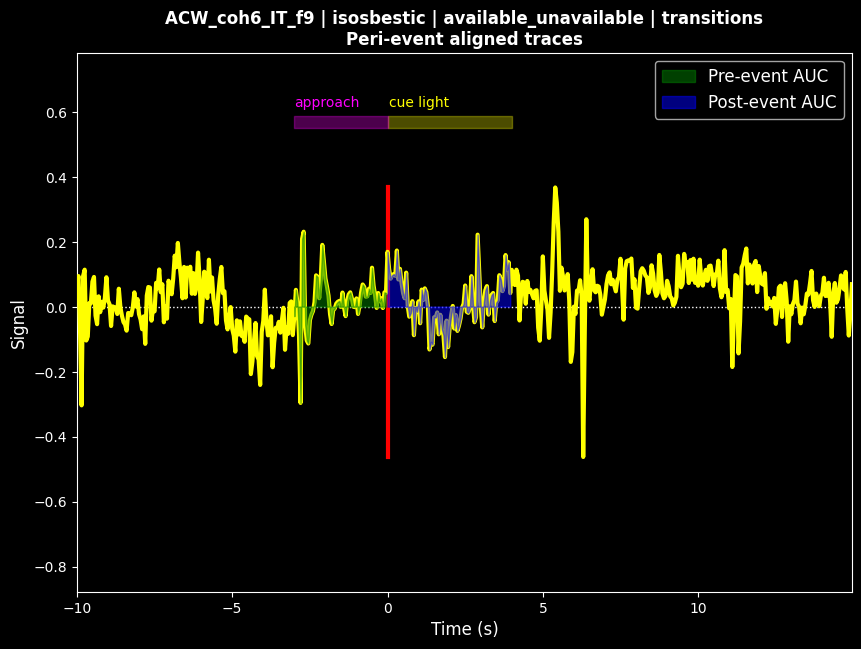

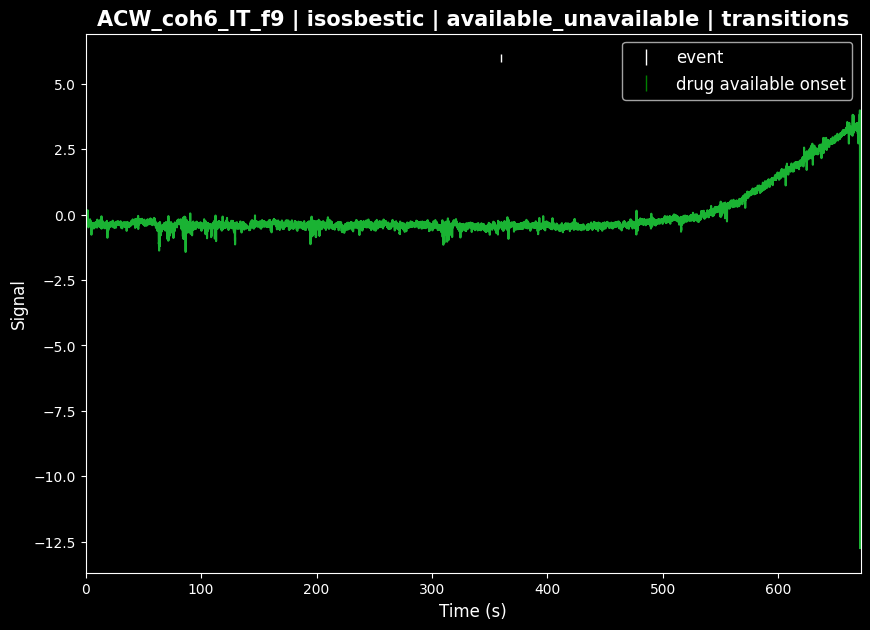

- GCaMP/
  - drug available/
    - epocs: DataFrame
    - epocs_baselined: DataFrame
    - epocs_mean_std_sem: DataFrame
    - mean_trace: ndarray
    - std_trace: ndarray
    - sem_trace: ndarray
    - events_info: DataFrame
    - fig_5: Figure
    - fig_15: Figure
    - subset_figs: NoneType
    - event_parameters/
      - rat: str
      - data type: str
      - preprocessed data stream: str
      - event type examined: str
      - event count: int
      - trange: list
      - baseline_trange: list
      - subset: NoneType
      - approach window: str
      - mean approach response: str
      - SEM approach response: str
      - cue window: str
      - mean cue response: str
      - SEM cue response: str
      - pre-event AUC window: str
      - mean pre-event AUC: str
      - SEM pre-event AUC: str
      - post-event AUC window: str
      - mean post-event AUC: str
      - SEM post-event AUC: str
    - n_events: int64
  - available_unavailable/
    - epocs: DataFrame
    - epocs_bas

,blockname,nickname,channel_raw,channel_name,fs,device_start_time,device_stop_time
0,ACW_coh6d_102226_0004,ACW_coh6_IT_f10,Headstage01LockIn01,Headstage01_470nm,100,13:10:21.962,13:27:29.623
1,ACW_coh6d_102226_0004,ACW_coh6_IT_f10,Headstage01LockIn02,Headstage01_415nm,100,13:10:21.962,13:27:29.623
2,ACW_coh6d_102226_0004,ACW_coh6_IT_f9,Headstage02LockIn01,Headstage02_470nm,100,13:10:21.962,13:27:29.623
3,ACW_coh6d_102226_0004,ACW_coh6_IT_f9,Headstage02LockIn02,Headstage02_415nm,100,13:10:21.962,13:27:29.623


,blockname,channel_raw,channel_name,nickname,time,raw_au
0,ACW_coh6d_102226_0004,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.273528,0.062332
1,ACW_coh6d_102226_0004,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.283528,0.062232
2,ACW_coh6d_102226_0004,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.293528,0.062103
3,ACW_coh6d_102226_0004,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.303528,0.062015
4,ACW_coh6d_102226_0004,Headstage01LockIn01,Headstage01_470nm,ACW_coh6_IT_f10,0.313528,0.062052
...,...,...,...,...,...,...
410795,ACW_coh6d_102226_0004,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1027.506825,0.042328
410796,ACW_coh6d_102226_0004,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1027.516825,0.042394
410797,ACW_coh6d_102226_0004,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1027.526825,0.042512
410798,ACW_coh6d_102226_0004,Headstage02LockIn02,Headstage02_415nm,ACW_coh6_IT_f9,1027.536825,0.042667


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,411.453
1,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,169.243
2,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,183.224
3,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,422.113
4,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,571.179
5,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,572.259
6,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,572.409
7,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,973.266
8,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,990.616
9,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO16,D16 Raw_DrugInfusion_box3,422.113


Moved ACW_coh6d_102226_0004_streams_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0004_streams_info.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
Moved ACW_coh6d_102226_0004_epocs_data.feather → D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\processed_sessions
File not found, skipping: ACW_coh6d_102226_0004_epocs_info.feather
🔍 Detected format: Doric
⚠️ Missing expected channels for BOX2 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX4 (ACW_coh5_IT_). Skipping.
⚠️ Missing expected channels for BOX5 (ACW_coh5_IT_). Skipping.

✅ Found photometry data for boxes: BOX3



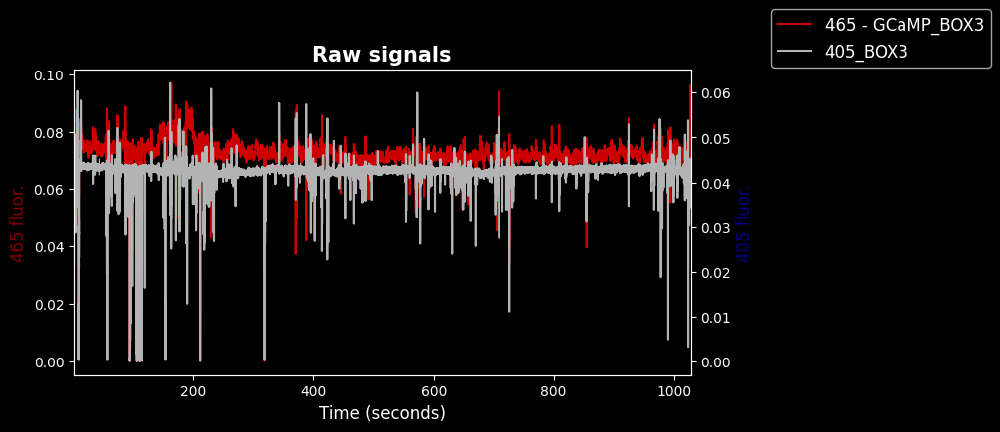

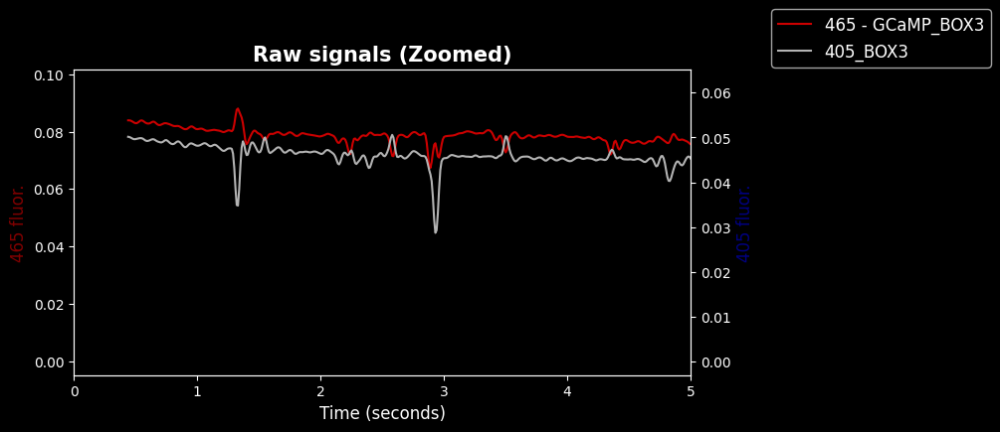

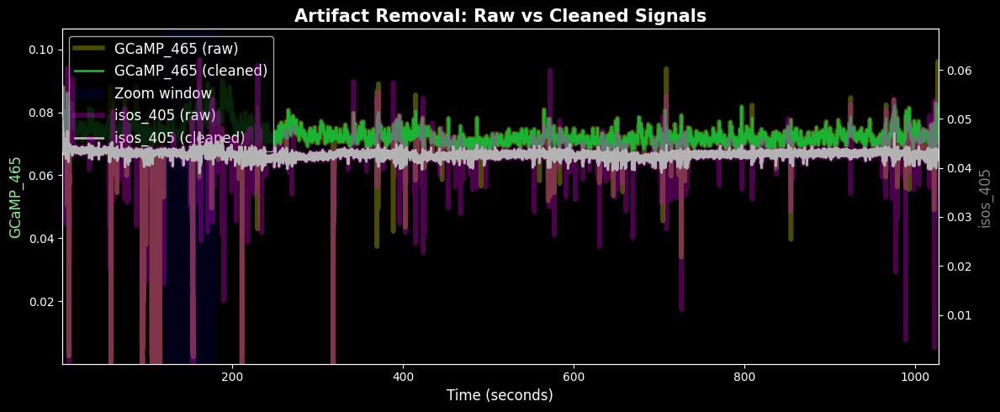

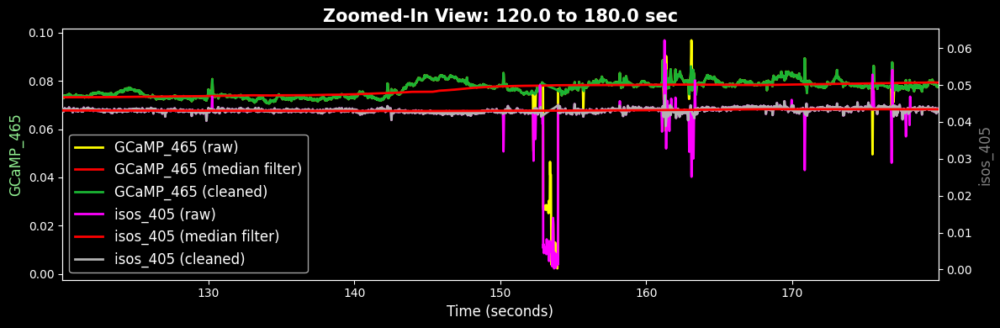

20.0


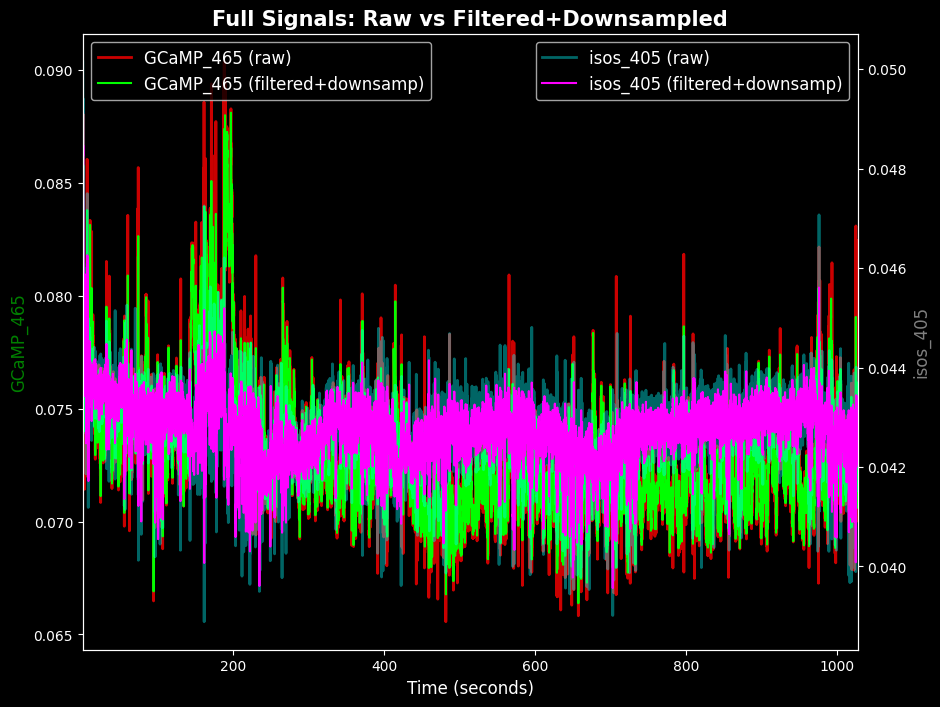

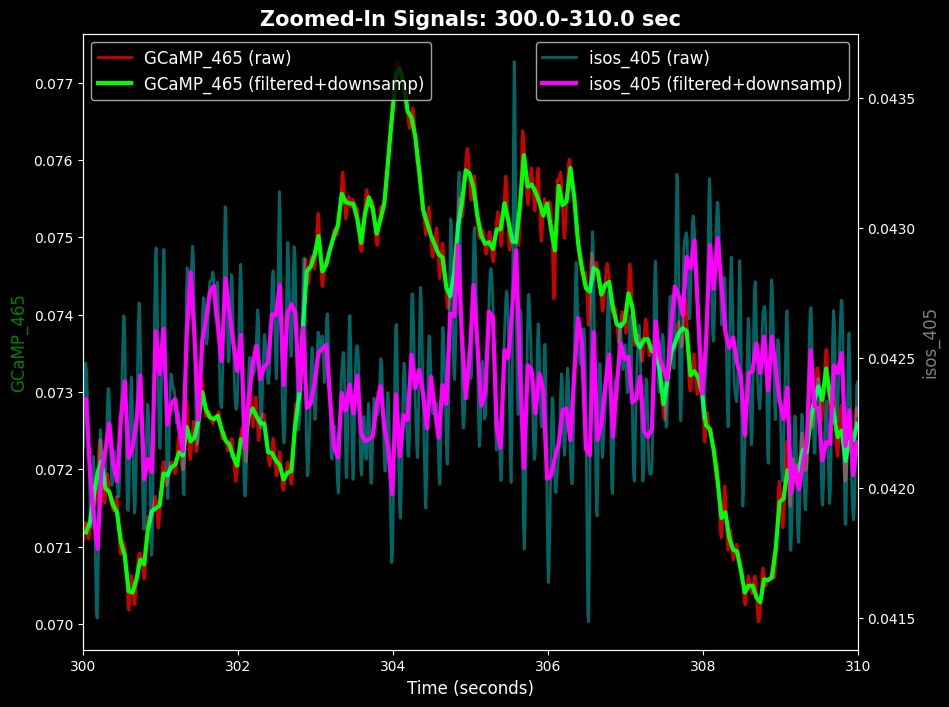

isos_405 length: 102700
isos_405_downsamp length: 20543
GCaMP_465 length: 102700
GCaMP_465_downsamp length: 20543
ts_all length: 102700
ts_downsamp length: 20543

the duration of the stream data is 1027.5416251099996 seconds, aka 17.125693751833328 mins


,blockname,source_path,input code,onset
0,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO13,D13 Raw_DrugAvail_box3,411.453
1,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,169.243
2,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,183.224
3,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,422.113
4,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,571.179
5,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,572.259
6,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,572.409
7,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,973.266
8,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO14,D14 Raw_ActiveLever_box3,990.616
9,ACW_coh6d_102226_0004,Series0001/DigitalIO/DIO16,D16 Raw_DrugInfusion_box3,422.113


detected data format: Doric

📋 Unique D## codes found: ['D13' 'D14' 'D16' 'D29' 'D30' 'D31' 'D32']
📌 dropsec_code reflects beginning of the Med Associates program
📌 dropsec_code reflects onset of drug availability

⏱ dropsec code D13 corresponds to timepoints: [411.453]

✅ Using dropsec = 411.453 seconds from epoc data.
the downsampled sampling rate is 20.0 Hz

discard the first 411.453 seconds, data points from 0 to 8229

keep a duration of 15 minutes
including to end of stream: data points 7021 to 20543

- - - - - initial vector lengths - - - - -

len(isos_405_filt_downsamp): 20543
len(ts_downsamp): 20543

start index: 7021
end index: 20543

Trimmed duration: 676.05 sec (~11.27 min) (requested 15 min, pre_buffer 0s, post_buffer 0s)

Plotting TRANSITION segment (1 min before → 1 min after available period, total 17.0 min) ...


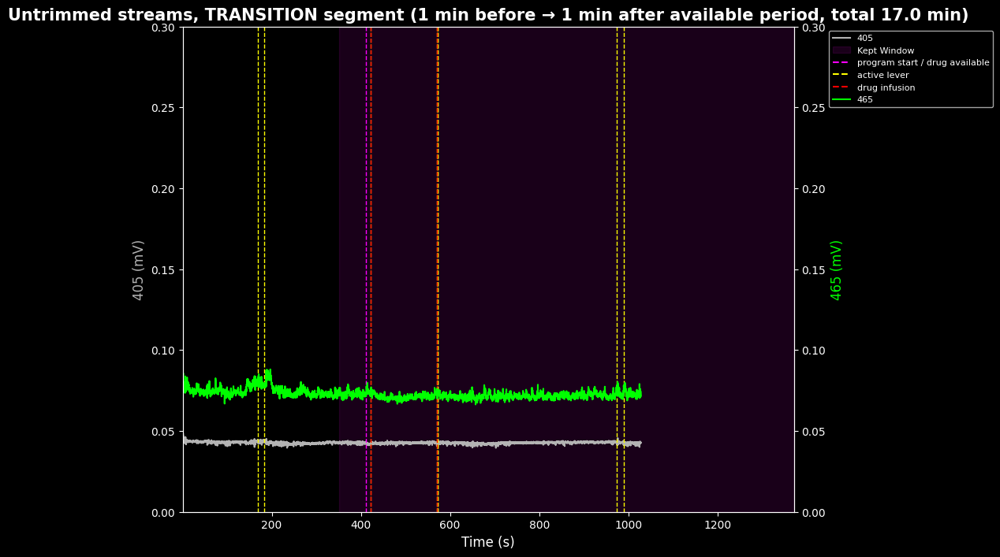

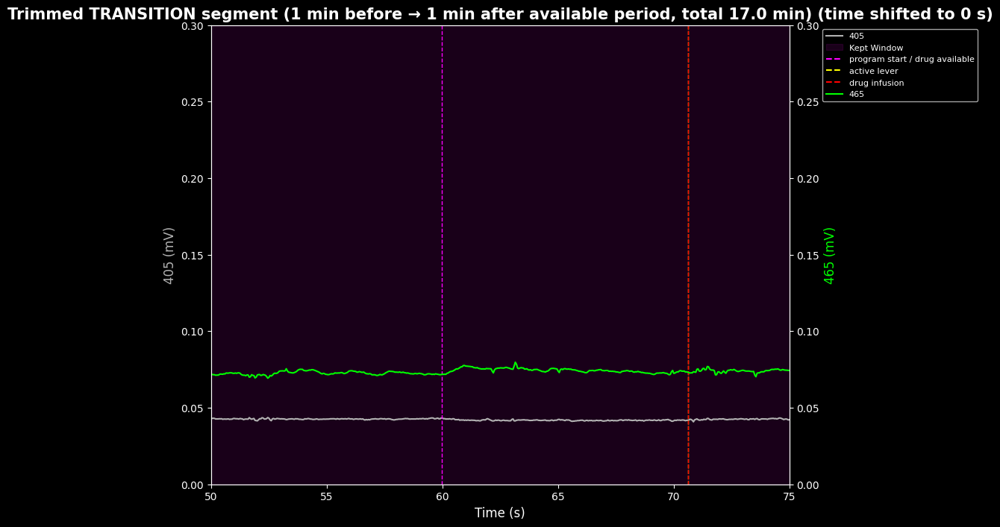

examining 15 minutes of the epoc data
the dropsec code is D13
the start code is 0
dropsec is equal to 411.453
Intermittent access self-admin epoc_ts_and_indices:


ACW_coh6_IT_f9 epoc timestamps,epoc_ts,epoc_indices,data,event
0,60.000,1200,D13,drug available
1,70.660,1413,D14,active lever
2,219.726,4394,D14,active lever
3,220.806,4416,D14,active lever
4,220.956,4419,D14,active lever
5,360.000,7200,NaN,available_unavailable
6,70.660,1413,D16,drug infusion
7,219.726,4394,D16,drug infusion


Detected 2 artifact segments.


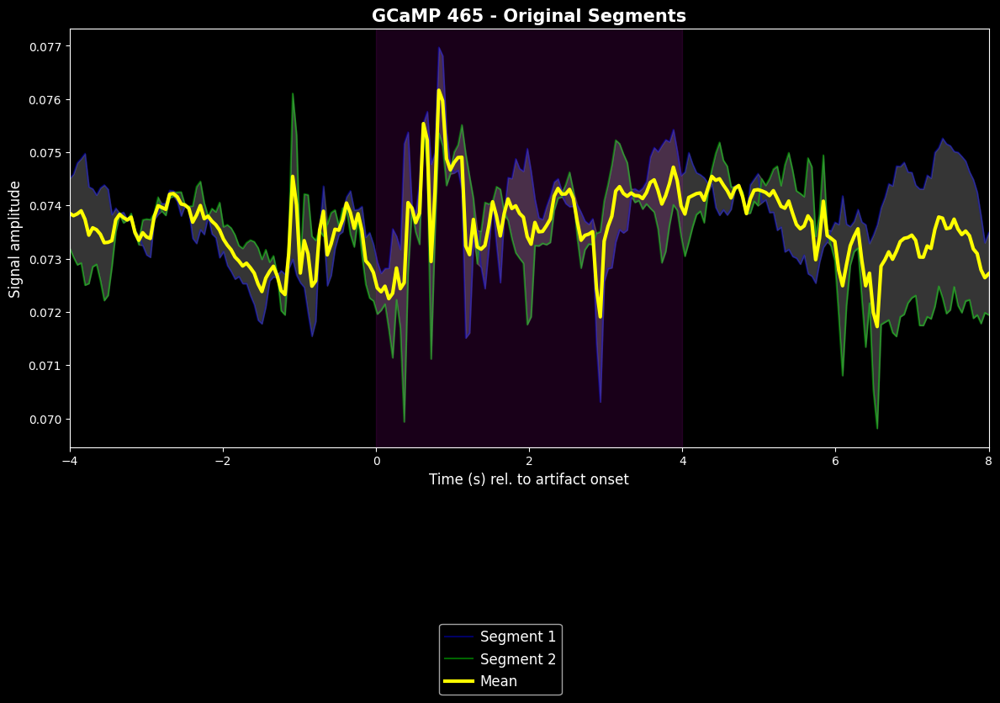

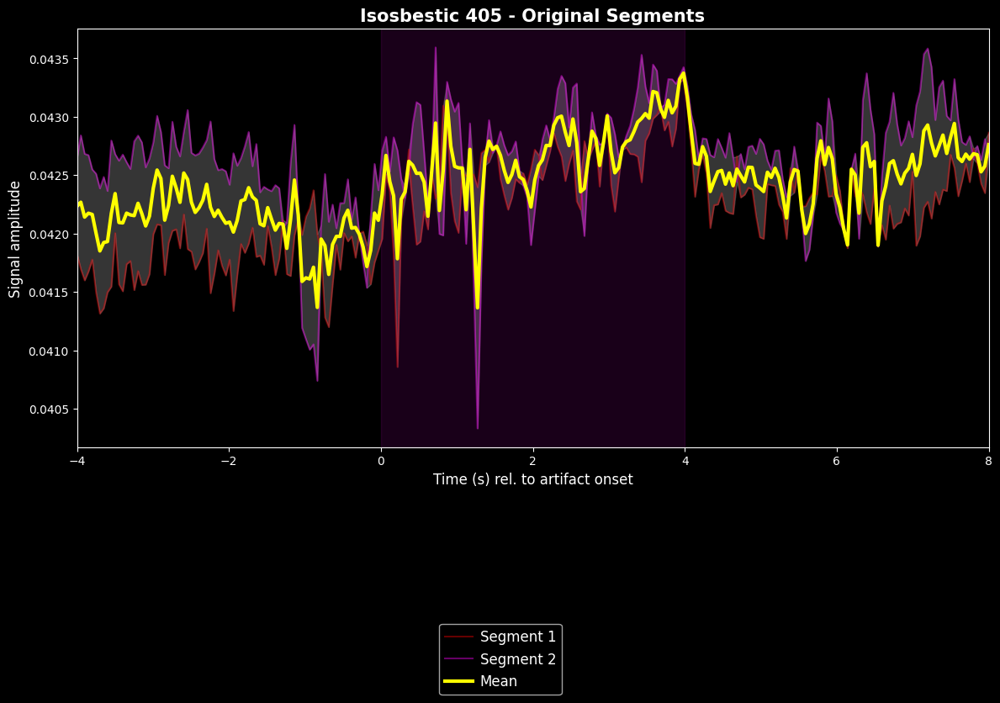

negative regression slope, correction not applied
Detected 1 perievent segments.


C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:252: RuntimeWarning: invalid value encountered in true_divide
  ret, rcount, out=ret, casting='unsafe', subok=False)


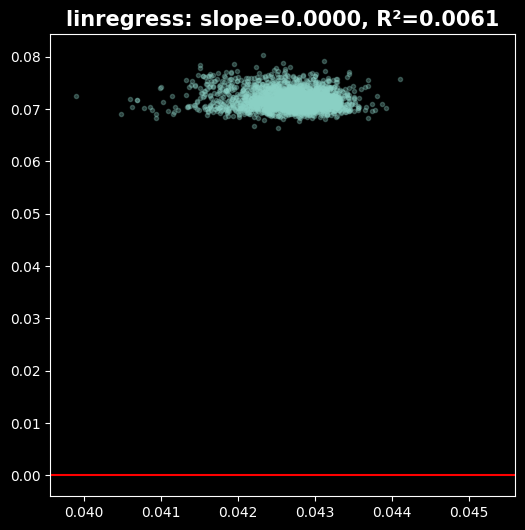

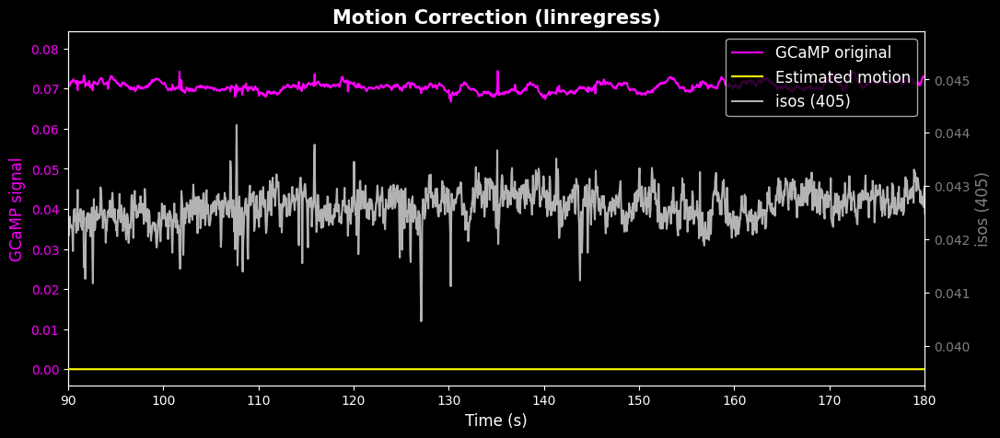

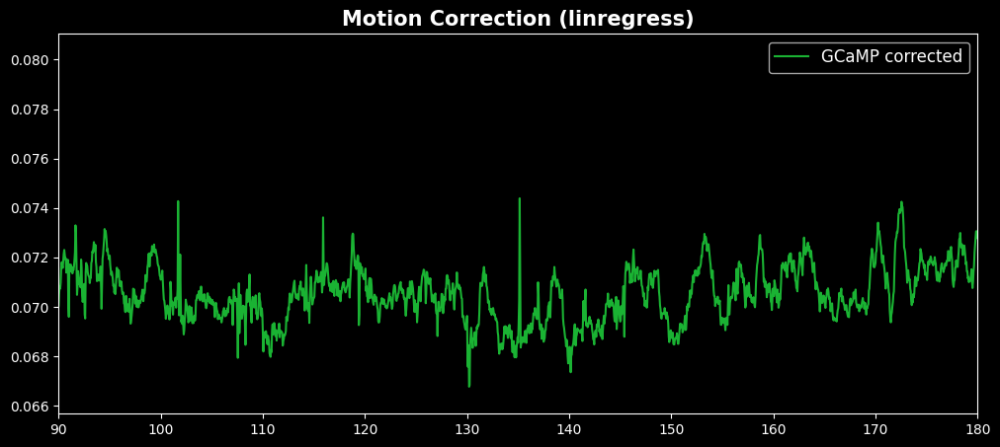

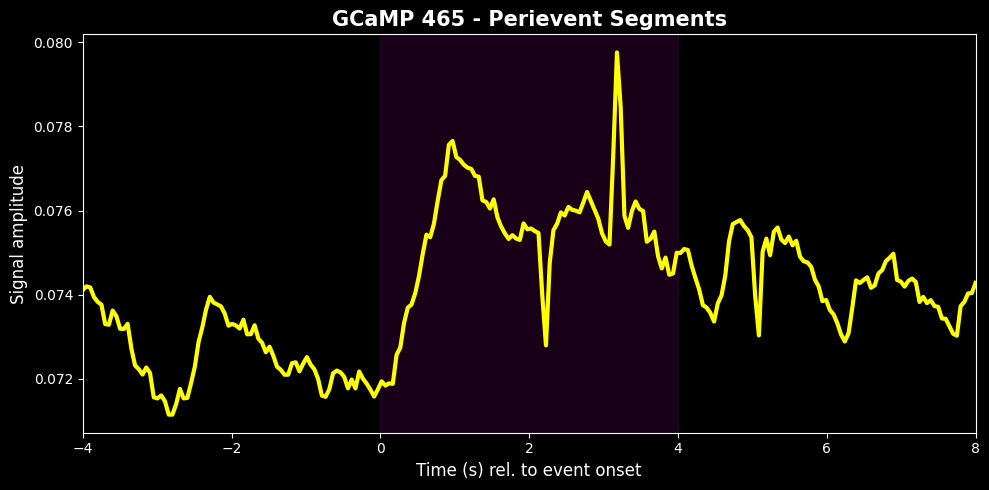

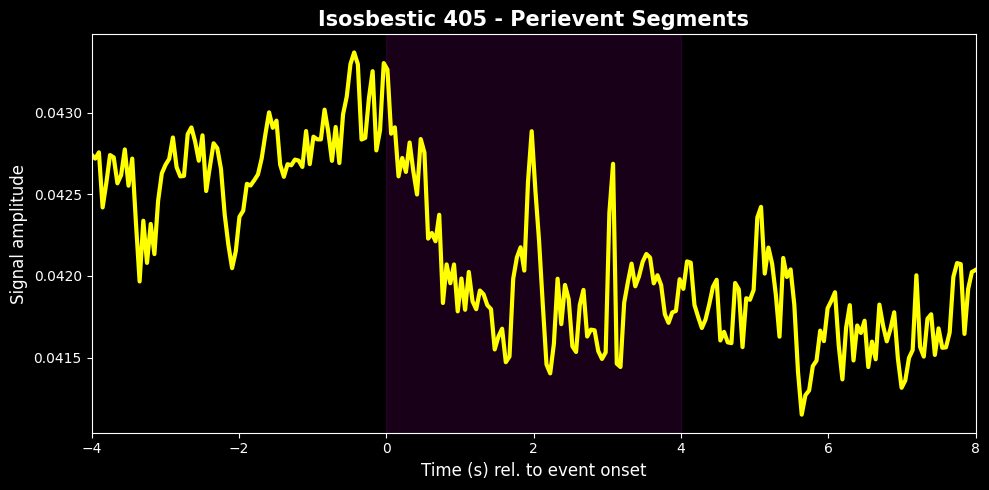

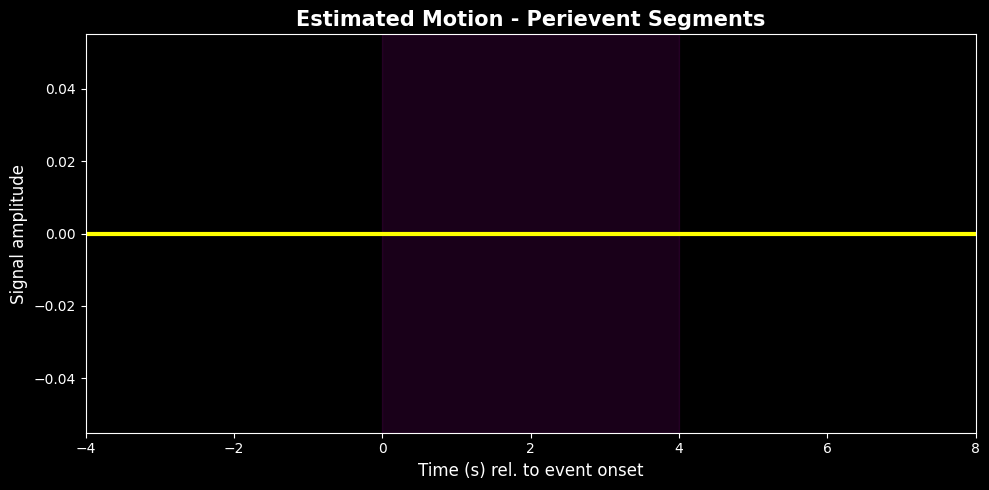

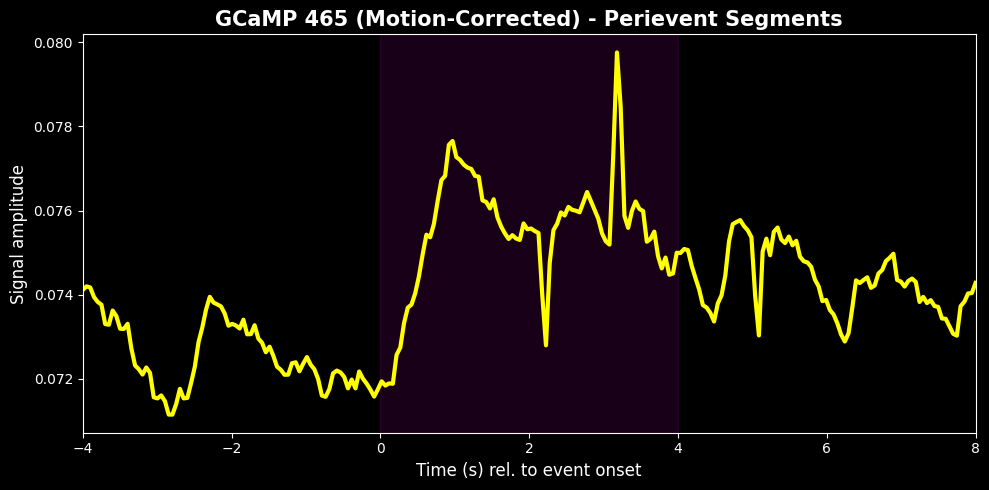

c:\Python\Whitebirch_python\fp_func_acw.py:3812: RuntimeWarning: divide by zero encountered in true_divide
  normData = np.divide(res, control) # (F(t)-f0)/F0


ACW_coh6_IT_f9 preprocessed streams,ts,isosbestic 405nm,"isosbestic 405nm, artifacts corrected",GCaMP 465nm,estimated motion,GCaMP 465nm motion correction,"GCaMP 465nm motion correction, exponential fit","GCaMP 465nm motion correction, exponential fit, airPLS","GCaMP 465nm motion correction, exponential fit, airPLS, z-scored","GCaMP 465nm, dF/F",isosbestic 405nm exponential fit,"isosbestic 405nm exponential fit, airPLS","isosbestic 405nm exponential fit, airPLS, z-scored"
0,0.00,0.042437,0.042437,0.076785,0.0,0.076785,0.004977,0.004437,2.772092,inf,-0.000246,-0.000121,-0.317865
1,0.05,0.042931,0.042931,0.076653,0.0,0.076653,0.004846,0.004306,2.690088,inf,0.000248,0.000373,0.982532
2,0.10,0.042827,0.042827,0.076360,0.0,0.076360,0.004553,0.004013,2.506920,inf,0.000143,0.000269,0.706810
3,0.15,0.042783,0.042783,0.075979,0.0,0.075979,0.004172,0.003632,2.268931,inf,0.000100,0.000225,0.592528
4,0.20,0.042554,0.042554,0.075633,0.0,0.075633,0.003826,0.003286,2.052863,inf,-0.000129,-0.000004,-0.009475
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13517,675.85,0.042563,0.042563,0.071478,0.0,0.071478,-0.000330,-0.001245,-0.777992,inf,-0.000120,-0.000051,-0.133765
13518,675.90,0.042924,0.042924,0.074610,0.0,0.074610,0.002803,0.001887,1.179041,inf,0.000241,0.000310,0.814736
13519,675.95,0.043202,0.043202,0.074511,0.0,0.074511,0.002704,0.001788,1.117159,inf,0.000519,0.000588,1.546270
13520,676.00,0.042491,0.042491,0.071680,0.0,0.071680,-0.000128,-0.001043,-0.651818,inf,-0.000192,-0.000123,-0.324199


C:\Python\envs\python_acw\lib\site-packages\numpy\lib\function_base.py:2536: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
c:\Python\Whitebirch_python\fp_func_acw.py:3946: RuntimeWarning: invalid value encountered in subtract
  GCaMP_465_dFF - np.mean(GCaMP_465_dFF)
C:\Python\envs\python_acw\lib\site-packages\numpy\core\_methods.py:230: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


r = nan
slope = nan
intercept = nan
R² = nan
Correlation between z(dF/F) and z-score = nan
🚫 Rejected 15 artifactual peaks


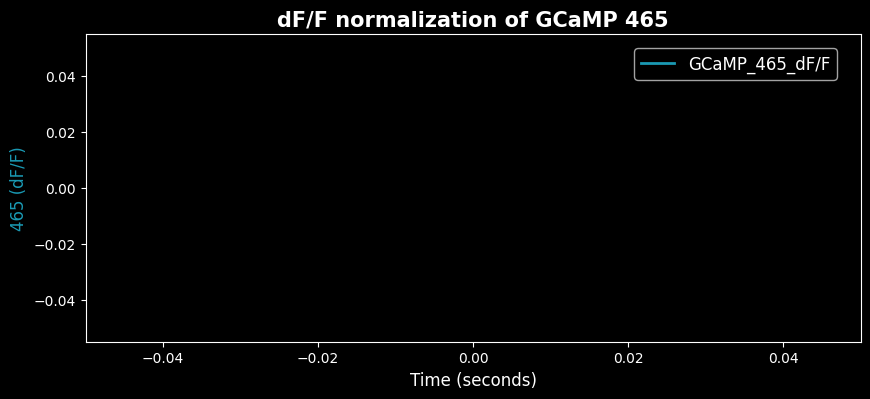

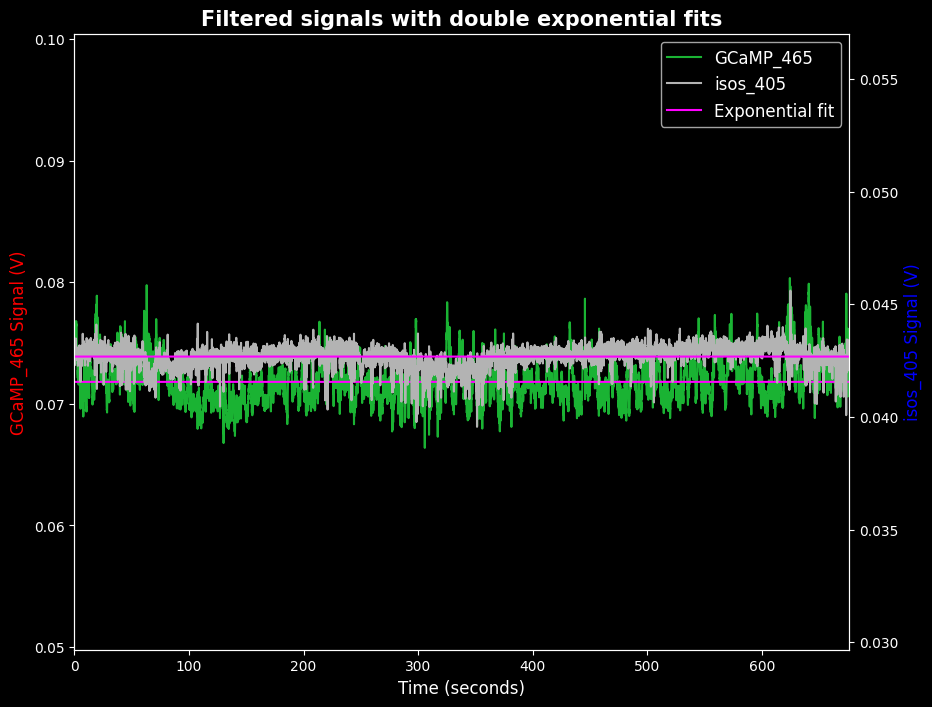

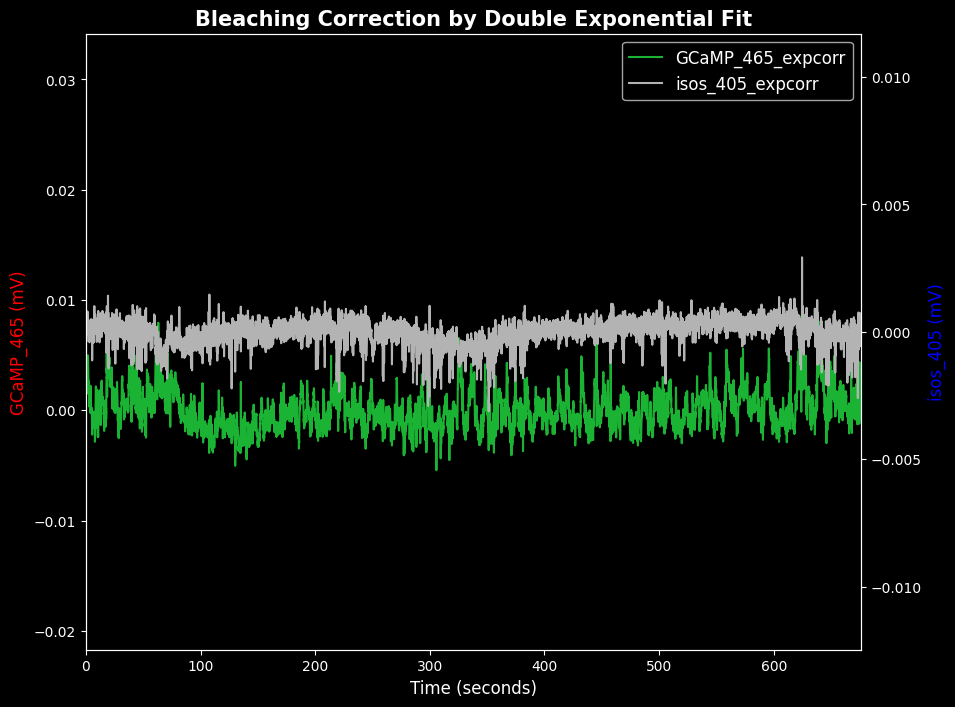

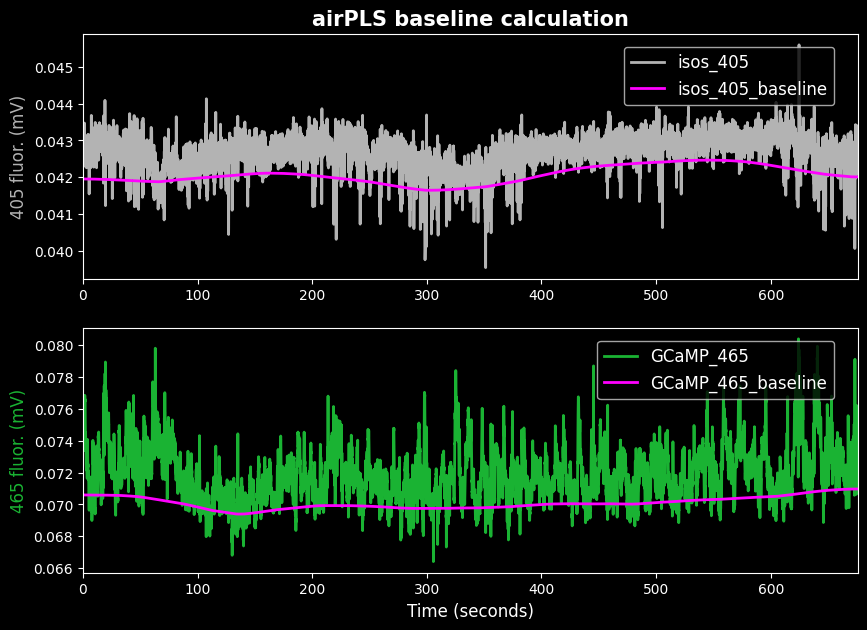

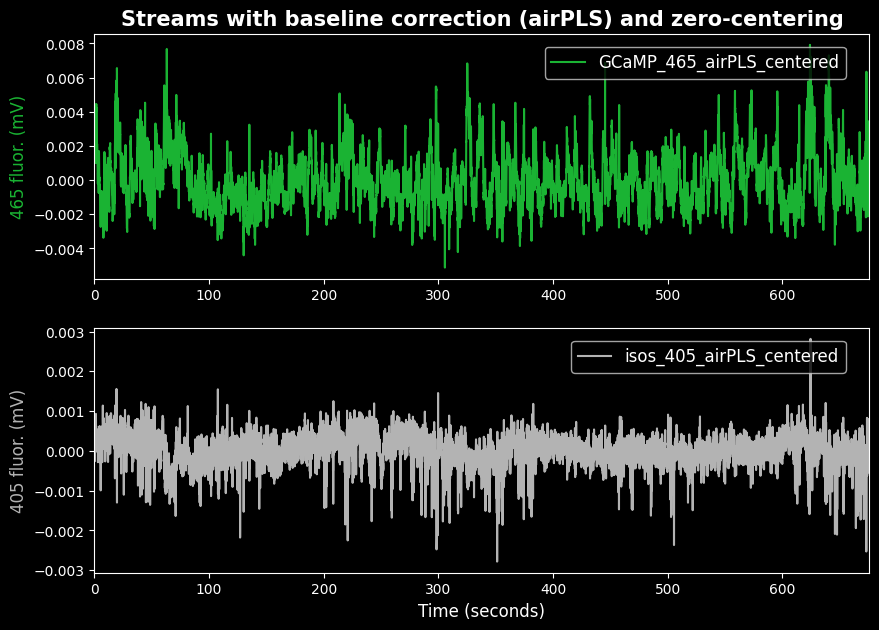

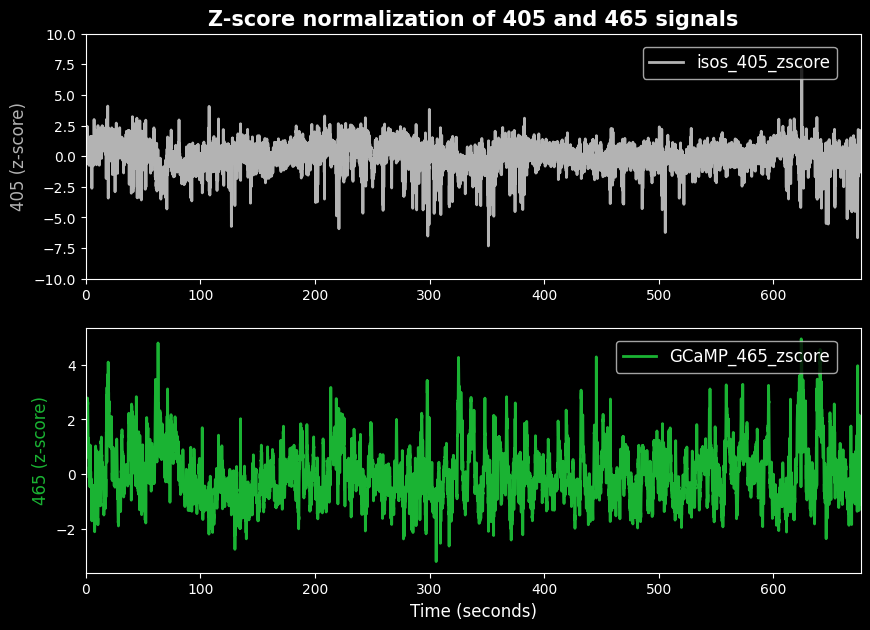

<Figure size 1000x700 with 0 Axes>

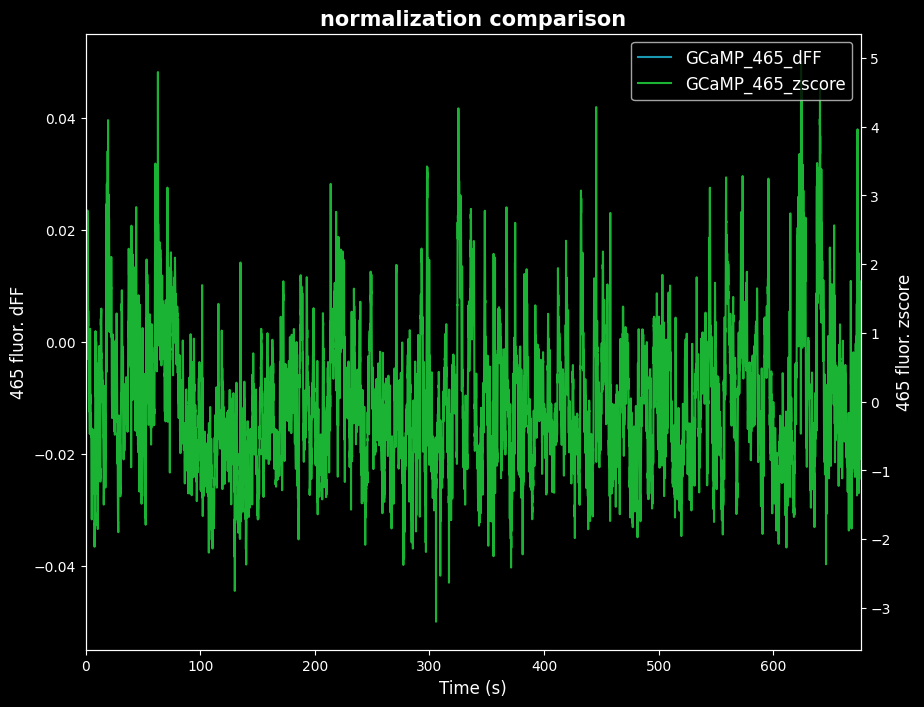

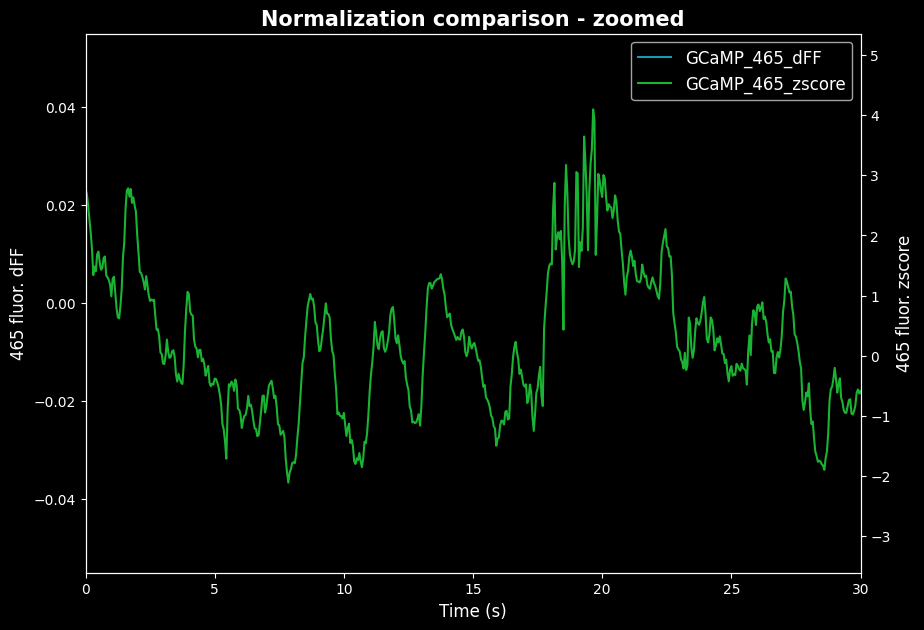

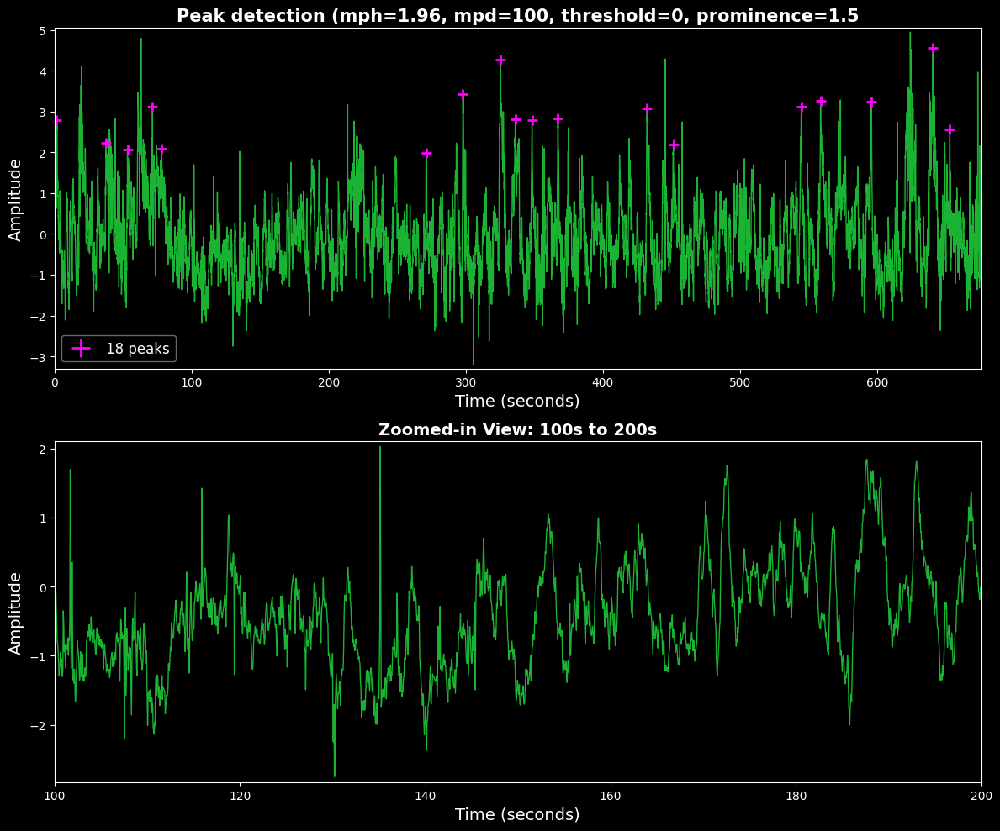

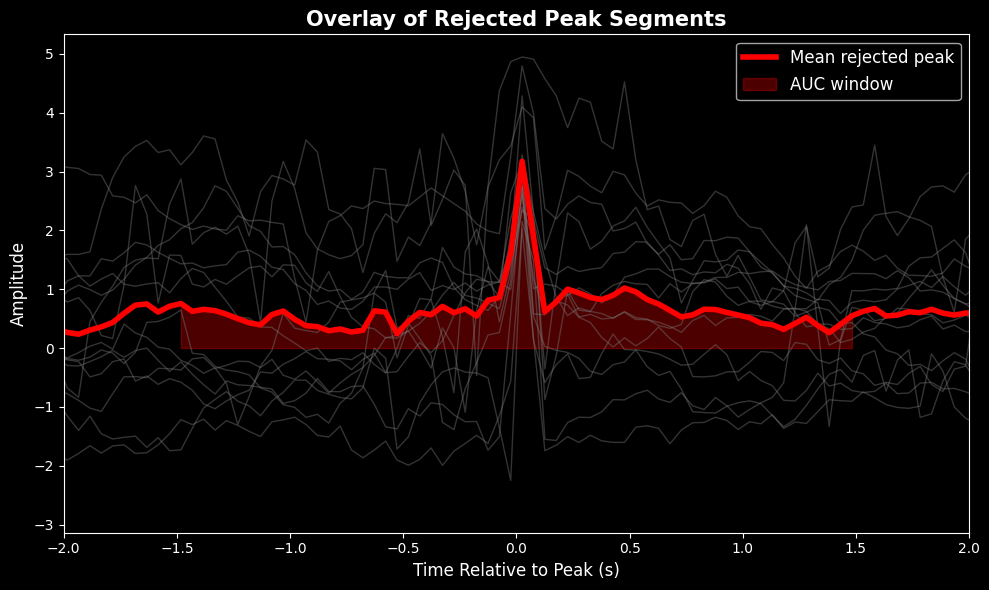

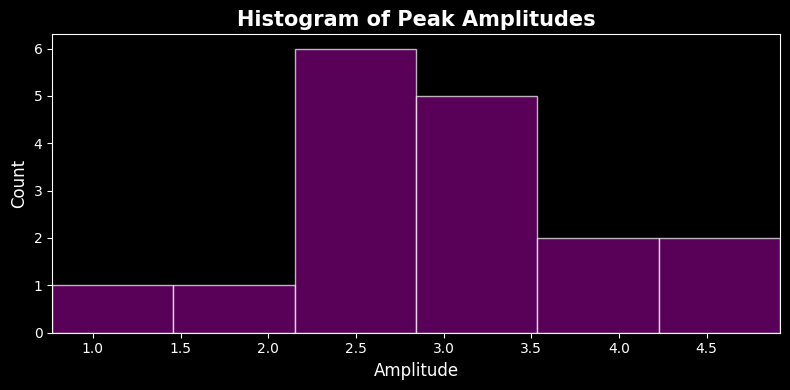

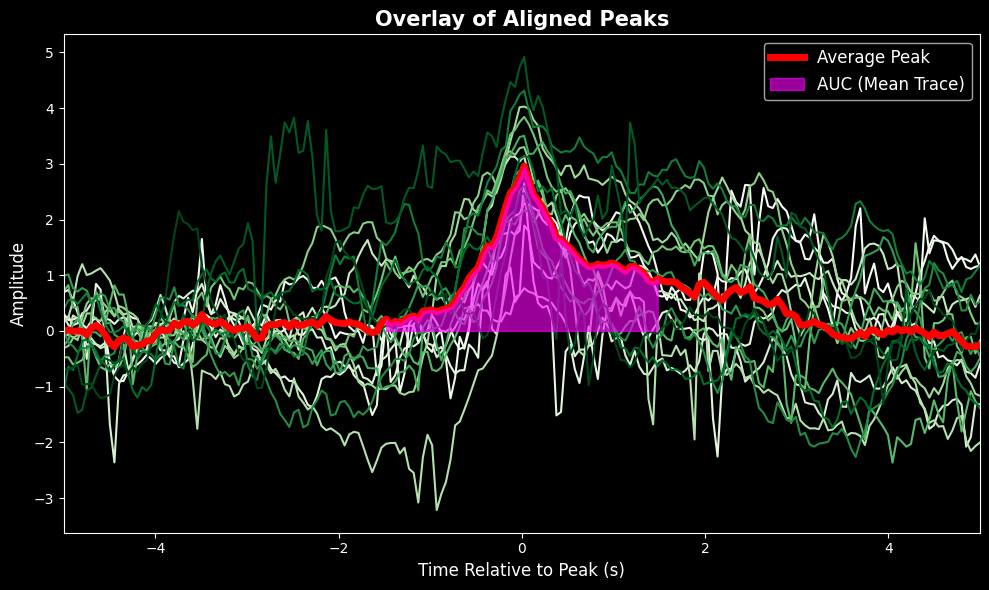


peak frequency is: 0.025146069077730947 Hz

peak amplitudes:
[2.28711959 2.64937318 1.89157536 0.76746222 3.13663362 2.39295185
 4.02750332 3.30115487 3.84180925 2.8778837  3.5026274  2.1646622
 2.60179042 4.31315547 3.13576454 4.91809085 2.47362645]

mean and SEM of peak amplitudes: 2.9578343707841315 +- 0.24161585933400426

🧪 Running perievent analysis for data type: GCaMP
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.
  ▶ Event: available_unavailable (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch for y-limits.

🧪 Running perievent analysis for data type: isosbestic
  ▶ Event: drug available (1 events)
Number of events found: 1
⚠ Only one valid epoch left — STD and SEM cannot be computed.
⚠ Only one valid epoch. Using min/max of that epoch

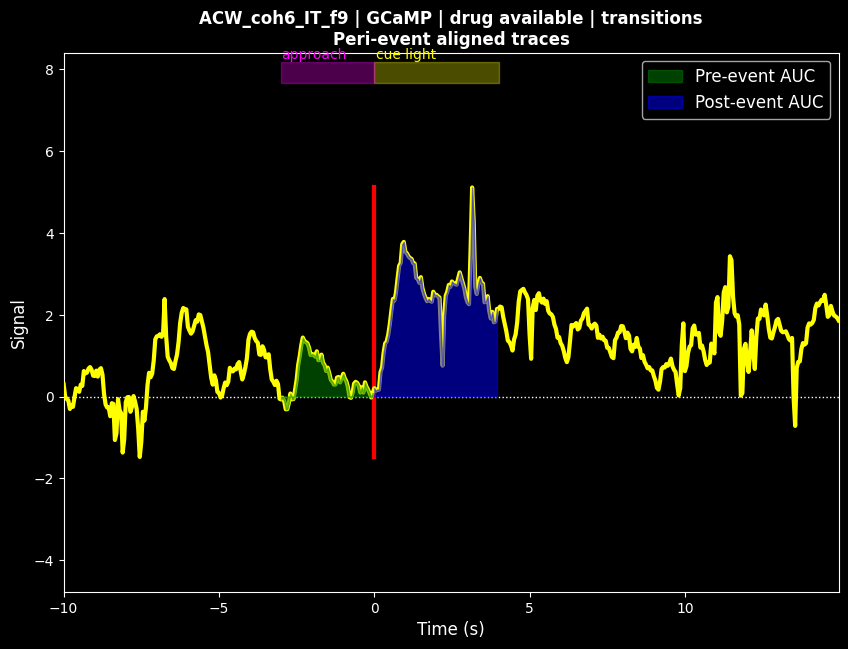

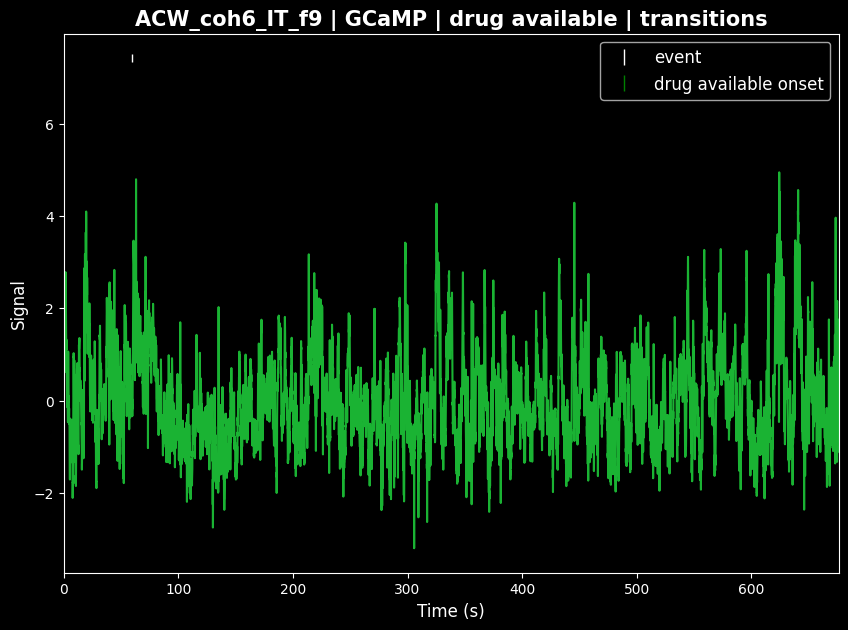

GCaMP | Event: available_unavailable


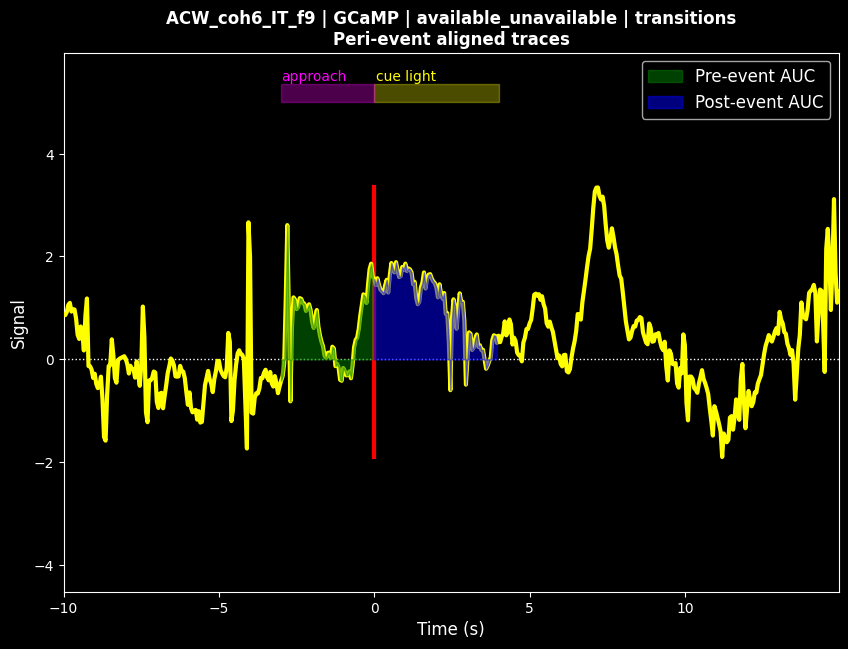

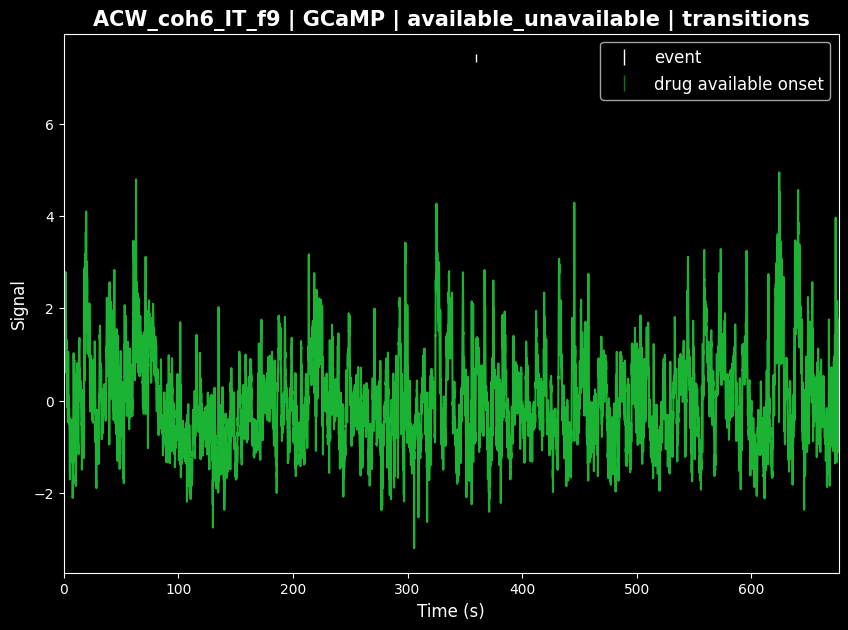

isosbestic | Event: drug available


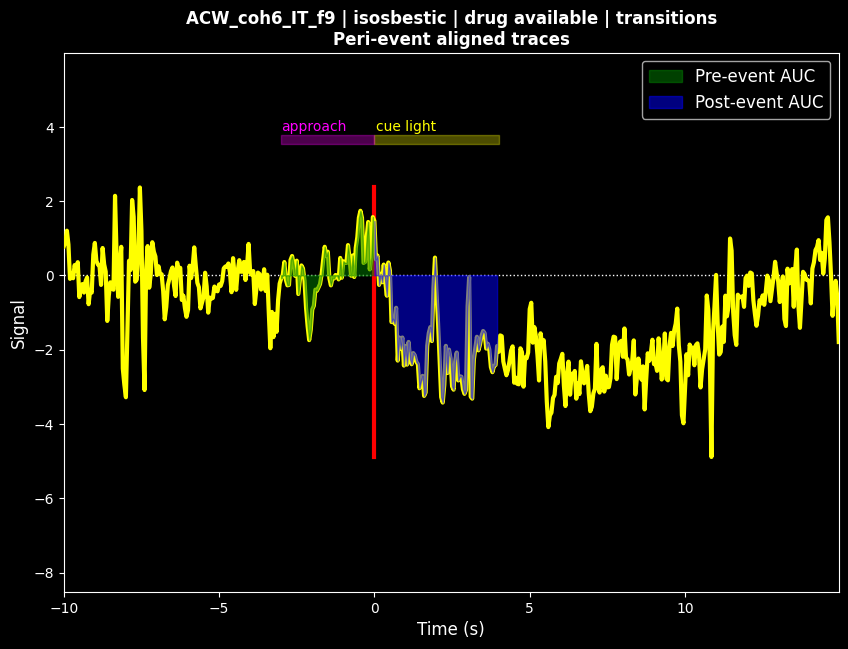

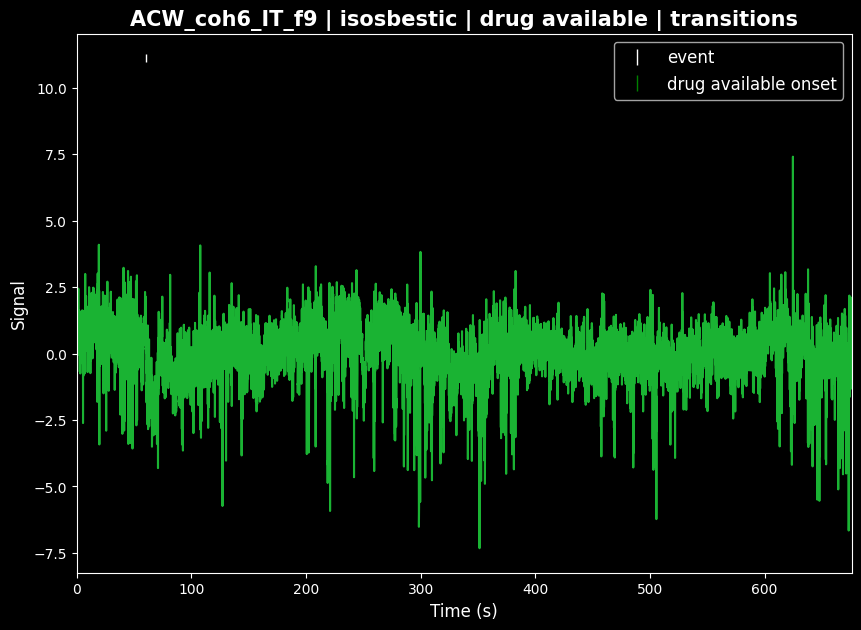

isosbestic | Event: available_unavailable


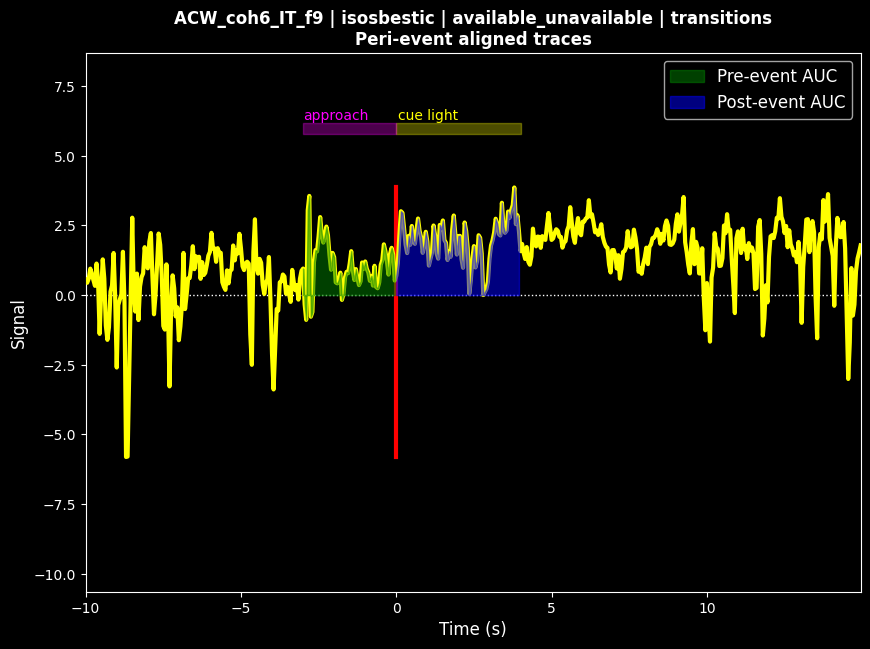

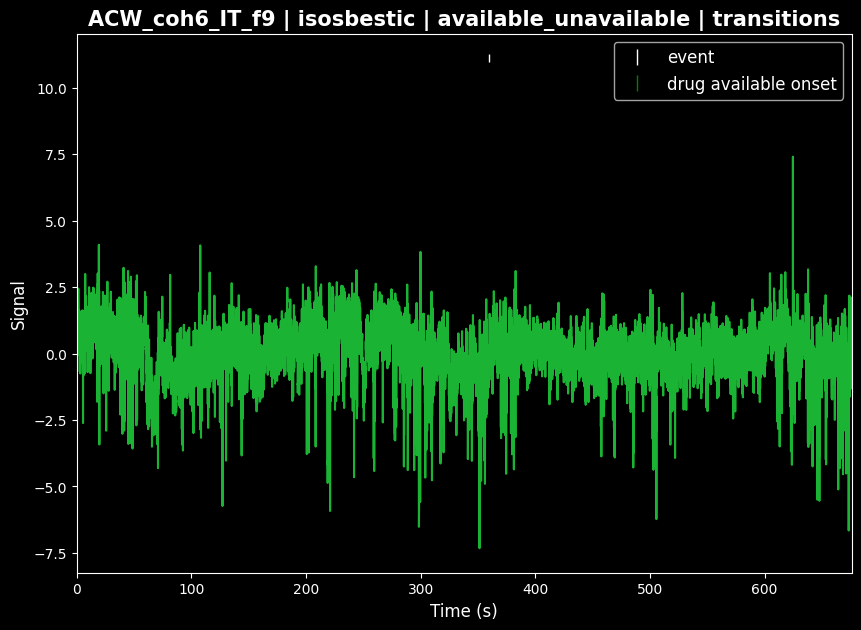

- GCaMP/
  - drug available/
    - epocs: DataFrame
    - epocs_baselined: DataFrame
    - epocs_mean_std_sem: DataFrame
    - mean_trace: ndarray
    - std_trace: ndarray
    - sem_trace: ndarray
    - events_info: DataFrame
    - fig_5: Figure
    - fig_15: Figure
    - subset_figs: NoneType
    - event_parameters/
      - rat: str
      - data type: str
      - preprocessed data stream: str
      - event type examined: str
      - event count: int
      - trange: list
      - baseline_trange: list
      - subset: NoneType
      - approach window: str
      - mean approach response: str
      - SEM approach response: str
      - cue window: str
      - mean cue response: str
      - SEM cue response: str
      - pre-event AUC window: str
      - mean pre-event AUC: str
      - SEM pre-event AUC: str
      - post-event AUC window: str
      - mean post-event AUC: str
      - SEM post-event AUC: str
    - n_events: int64
  - available_unavailable/
    - epocs: DataFrame
    - epocs_bas

In [7]:
#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-

from fp_func_acw import streams_peek_ratpack_tdt_or_doric
from fp_func_acw import remove_artifacts_dual_signal
from fp_func_acw import filt_downsamp_streams
from fp_func_acw import streams_trim_events_doric
from fp_func_acw import epoc_onsets_IntA     
from fp_func_acw import motcorr_unified
from fp_func_acw import plot_perievent_segments
from fp_func_acw import dubexp_correct
from fp_func_acw import baselinecorr
from fp_func_acw import zscore
from fp_func_acw import deltaFF
from fp_func_acw import detect_peaks
from fp_func_acw import epoc_streams
from collections import defaultdict


#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-
# decide if outputs should be saved 

save = False

# Save directory and info
save_folder = r"D:\ACW\photometry\cohort_6_101226\extracted\IntA_SA\analysis_loop_test\transitions_test"

#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-


# Define the box of interest to further process
box = 'BOX3'  
    

box_to_rat = {
    'BOX2': BOX2_rat,
    'BOX3': BOX3_rat,
    'BOX4': BOX4_rat,
    'BOX5': BOX5_rat,
}

print(box_to_rat)

# Look up the rat name for this box

rat = box_to_rat[box]
print(f'The rat to be further examined is: {rat}')



#_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-_-
session_ids = sorted(files)
print(session_ids)


bad_sessions = set()

# for before, transitions
'''
bad_sessions = {
    'ACW_coh5c_coh5d_110425_0003',  # skip
    'ACW_coh5c_coh5d_110425_0006'   # skip
}
'''

segment_mode = 'transitions'    ####### 'before', 'during', or 'after' for either unavail preceding, avail, or unavail following. 
                            # or 'transitions'
                            ## or None if not an intermittent access file
neg_peaks = False


session_ids = [s for s in session_ids if s not in bad_sessions]

print('Sessions to be processed:')
for s in session_ids:
    print('  ', s)

print('\n--- Starting processing ---\n')

for session_id in session_ids:
    print()
    print('#-#-#-#-#--#--#--#--#--#--#---#---#---#---#---#----#----#----#----#----#--------------------------------------#')
    print()
    print(f'Processing {session_id}')
    print()

    # ---------- Load data ----------
    streams_data = pd.read_feather(
        os.path.join(source_folder, session_id + '_streams_data.feather')
    )
    streams_info = pd.read_feather(
        os.path.join(source_folder, session_id + '_streams_info.feather')
    )

    display(streams_info)
    display(streams_data)
    
    '''
    # if the nickname isn't proper
    streams_info.loc[streams_info['nickname'] == 'Headstage01', 'nickname'] = 'ACW_coh5_IT_m3'
    streams_data.loc[streams_data['nickname'] == 'Headstage01', 'nickname'] = 'ACW_coh5_IT_m3'

    # temp for fixing file 102625_0003
    streams_info.loc[streams_info['channel_name'] == 'Headstage256LockIn01', 'channel_name'] = 'Headstage01_470nm'
    streams_data.loc[streams_data['channel_name'] == 'Headstage256LockIn01', 'channel_name'] = 'Headstage01_470nm'
    streams_info.loc[streams_info['channel_name'] == 'Headstage256LockIn02', 'channel_name'] = 'Headstage01_415nm'
    streams_data.loc[streams_data['channel_name'] == 'Headstage256LockIn02', 'channel_name'] = 'Headstage01_415nm'


    display(streams_info)
    display(streams_data)

    '''

    epoc_data = pd.read_feather(
        os.path.join(source_folder, session_id + '_epocs_data.feather')
    )
    display(epoc_data)

    # ---------- Move processed files ----------
    session_id_clean = session_id.lstrip('/\\').strip()

    processed_folder = os.path.join(source_folder, "processed_sessions")
    os.makedirs(processed_folder, exist_ok=True)

    session_files = [
        f"{session_id_clean}_streams_data.feather",
        f"{session_id_clean}_streams_info.feather",
        f"{session_id_clean}_epocs_data.feather",
        f"{session_id_clean}_epocs_info.feather",
    ]

    for fname in session_files:
        src_path = os.path.join(source_folder, fname)
        if os.path.exists(src_path):
            dst_path = os.path.join(processed_folder, fname)
            shutil.move(src_path, dst_path)
            print(f"Moved {fname} → {processed_folder}")
        else:
            print(f"File not found, skipping: {fname}")
            


    rat_data, fs, ts_dict, fig_0, fig_1, data_format = streams_peek_ratpack_tdt_or_doric(
        streams_info,
        streams_data,
        box_to_rat,
        zoomtemp = [0, 5]
    )

    display(fig_0)
    display(fig_1)
    plt.close(fig_0)
    plt.close(fig_1)
    
    # Extract the signals for this rat from the rat_data dictionary
    isos_405_all = rat_data[rat]['isos_405']
    GCaMP_465_all = rat_data[rat]['GCaMP_465']
    ts_all = ts_dict[box]  # Get the corresponding time vector for that box

    
    

    GCaMP_465_all_no_arts, isos_405_all_no_arts = remove_artifacts_dual_signal(
        ts_all,
        GCaMP_465_all,
        isos_405_all,
        threshold_drop_signal1=0.07, #0.05           # amplitude drop threshold for GCaMP
        threshold_drop_signal2=0.07,           # amplitude drop threshold for isosbestic
        sudden_drop_threshold_signal1=0.02, #0.02     # sudden drop threshold for GCaMP
        sudden_drop_threshold_signal2=0.02,    # sudden drop threshold for isosbestic+
        min_artifact_duration=1,                # minimum artifact length in samples
        max_artifact_duration=2000,              # max artifact length in samples
        sampling_rate=100,  
        median_filter_size=4000,
        baseline_exclusion_seconds=0,# <-- ignore first seconds for artifact detection
        manual_windows= None, #[(1320, 1380)], #[(3225,3235)], #None   # list of tuples
        plot=True,
        signal1_label='GCaMP_465',
        signal2_label='isos_405',
        zoom_start = 120,
        zoom_window = 60
    )



    plt.show()
    plt.close()
    
    new_fs = fs/5  # sampling rate of 20 Hz for Doric data, which saves the demodulated signals at 100 Hz.

    filt = 8

    print(new_fs)


    isos_405_filt_downsamp, GCaMP_465_filt_downsamp, ts_downsamp, fig_8, fig_zoom = filt_downsamp_streams(
        isos_405_all_no_arts, 
        GCaMP_465_all_no_arts, 
        ts_all, fs, 
        new_fs,
        filt,
        zoom_start=300, 
        zoom_window=10
    )

    display(fig_8)
    display(fig_zoom)
    plt.close(fig_8)
    plt.close(fig_zoom)
    
    print("isos_405 length:", isos_405_all.size)
    print("isos_405_downsamp length:", isos_405_filt_downsamp.size)
    print("GCaMP_465 length:", GCaMP_465_all.size)
    print("GCaMP_465_downsamp length:", GCaMP_465_filt_downsamp.size)
    print("ts_all length:", ts_all.size)
    print("ts_downsamp length:", ts_downsamp.size)

    print()
    print(f'the duration of the stream data is {ts_downsamp[-1]} seconds, aka {ts_downsamp[-1]/60} mins')

    display(epoc_data[epoc_data['input code'].str.contains(box, case=False, na=False)])
    print('detected data format: Doric')
    
    
    # Analysis parameters


    default_dropsec = 10  # seconds

    startcode = 0     # This is 0 except in cases like IntA where there are multiple possible starts

    #dropsec_code = 'D09' # for the new Med PC programs, beginning 10.01.25

    if box == 'BOX2':
        dropsec_code = 'D09'
        
    elif box == 'BOX3':
        dropsec_code = 'D13'
            
    elif box == 'BOX4':
        dropsec_code = 'D25'
            
    elif box == 'BOX5':
        dropsec_code = 'D29'

    
    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~#
    
    keepmin_streams = 15 # mins
    
            
    if segment_mode == 'during':
        pre_buffer_sec = 10 #0  #seconds
        post_buffer_sec = 15 # seconds
        tzoom=[-10,30]
        
    elif segment_mode == None:
        pre_buffer_sec = 10 # seconds
        post_buffer_sec = 15 # seconds
        tzoom=[-10,60]
        
    elif segment_mode == 'transitions':
        pre_buffer_sec = 0 # seconds
        post_buffer_sec = 0 # seconds
        tzoom=[50,75]
        
    else:
        pre_buffer_sec = 0 # seconds
        post_buffer_sec = 0 # seconds
        tzoom=[-10,15]
    
    
    
    # Try to load epoc data and determine dropsec_streams

    epoc_data = None
    dropsec_streams = default_dropsec

    try:
        #epoc_data_path = os.path.join(subcoh + session_id + '_epocs_data.feather')  # already loaded above
        #epoc_data = pd.read_feather(epoc_data_path)
        # Path to the moved file
        epoc_data_path = os.path.join(source_folder, "processed_sessions", f"{session_id}_epocs_data.feather")

        # Load epoc data if it exists
        if os.path.exists(epoc_data_path):
            epoc_data = pd.read_feather(epoc_data_path)
            #display(epoc_data)
        else:
            print(f"Epoc data file not found in processed_sessions: {epoc_data_path}")
            epoc_data = None


        # 🔍 DEBUG: Show unique TTL codes for the current box
        # Extract the D## part from the 'input code' column
        epoc_data['D_code'] = epoc_data['input code'].str.extract(r'^(D\d{2})')

        # Get unique D## codes
        unique_d_codes = epoc_data['D_code'].dropna().unique()

        # Display the result
        print(f"\n📋 Unique D## codes found: {unique_d_codes}")
        
        # Extract onsets for the selected TTL code
        # Define the allowed D## codes
        allowed_d_codes = ['D09', 'D13', 'D25', 'D29']

        # Filter the DataFrame
        filtered_rows = epoc_data[
            epoc_data['input code'].str.contains(box, case=False, na=False) &  # case-insensitive match to box
            epoc_data['input code'].str.extract(r'^(D\d{2})')[0].isin(allowed_d_codes)  # extract D## and filter
        ]

        # Extract onset values
        dropsec_all = filtered_rows['onset'].values
        
        
        # 🧾 Interpret the TTL code
        if dropsec_code in ['D09', 'D13', 'D25', 'D29']:
            print('📌 dropsec_code reflects beginning of the Med Associates program')

        if dropsec_code in ['D09', 'D13', 'D25', 'D29'] and epoc_data['input code'].str.contains('Avail').any():
            print('📌 dropsec_code reflects onset of drug availability')
        

        print(f'\n⏱ dropsec code {dropsec_code} corresponds to timepoints: {dropsec_all}\n')

        # Select the event instance to use
        if len(dropsec_all) > startcode:
            dropsec_streams = dropsec_all[startcode]
            print(f'✅ Using dropsec = {dropsec_streams:.3f} seconds from epoc data.')
        else:
            dropsec_streams = default_dropsec
            pre_buffer_sec = 0 # seconds
            post_buffer_sec = 0 # seconds
            print(f'⚠️ No TTL onset found at index {startcode}. Using default dropsec = {default_dropsec} seconds, no buffers')

            
    except FileNotFoundError as e:
        dropsec_streams = default_dropsec
        epoc_data = None
        print(f'\n⚠️ Missing file "{e.filename}". Using default dropsec = {default_dropsec} seconds.')

    except Exception as e:
        dropsec_streams = default_dropsec
        epoc_data = None
        print(f'\n⚠️ Unexpected error: {e}. Using default dropsec = {default_dropsec} seconds.')



    #print(f'\nThe time segment preceding the trial begin is {dropsec_streams} seconds.')

    if 'noncont' in source_folder:
        noncont = True
    else:
        noncont = False



    # Bounds for final plot
    x = [0, 10]
    y1 = [(0.9 * np.mean(GCaMP_465_filt_downsamp)), (1.1 * np.mean(GCaMP_465_filt_downsamp))]
    y2 = [(0.9 * np.mean(isos_405_filt_downsamp)), (1.1 * np.mean(isos_405_filt_downsamp))]




    # Run stream trimming
    
    fig_2a, fig_2b, isos_405, GCaMP_465, ts = streams_trim_events_doric(
        isos_405_filt_downsamp,
        GCaMP_465_filt_downsamp,
        dropsec_streams,
        keepmin_streams,
        ts_downsamp,
        new_fs,
        y1,
        y2,
        x,
        startcode,
        epoc_data=epoc_data,  # can now safely be None
        box=box,
        noncont=False,
        tzoom=tzoom,
        segment_mode = segment_mode,
        pre_buffer_sec=pre_buffer_sec, 
        post_buffer_sec=post_buffer_sec
    )

    display(fig_2a)
    display(fig_2b)
    plt.close(fig_2a)
    plt.close(fig_2b)
    
    epoc_data_path = os.path.join(source_folder, "processed_sessions", f"{session_id}_epocs_data.feather")

    # Load epoc data if it exists
    if os.path.exists(epoc_data_path):
        epoc_data = pd.read_feather(epoc_data_path)
        #display(epoc_data)
    else:
        print(f"Epoc data file not found in processed_sessions: {epoc_data_path}")
        epoc_data = None

    
    ####  importantly, these codes should match those above for the stream trimming!

    keepmin_epocs = keepmin_streams   # what is the duration in minutes of the epoc data I want to examine? 
    #keepmin_epocs = 90 # if I want to see all events


    print(f'examining {keepmin_epocs} minutes of the epoc data')

    dropsec_code = dropsec_code   # inherited from above. this is 1 for most cases, beginning of med pc program, but is 3 for start of IntA and 2 for remaining available periods

    print(f'the dropsec code is {dropsec_code}')

    startcode = startcode    # again, inherited from above. which index of dropsec_code to use, if there are multiple options. E.g. 1 would be the index for the second drug available onset. 

    print(f'the start code is {startcode}')

    #### 

    epoc_ts_and_indices, ts_epocs = epoc_onsets_IntA(epoc_data, keepmin_epocs, ts, box, new_fs, dropsec_streams, segment_mode, data_format)
    print('Intermittent access self-admin epoc_ts_and_indices:')
    epoc_ts_and_indices.columns.name = f'{rat} epoc timestamps'
    display(epoc_ts_and_indices)
    
    
    
    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    from fp_func_acw import visualize_and_correct_artifacts


    correct_stream='none'


    GCaMP_465_nocuearts, isos_405_nocuearts = visualize_and_correct_artifacts(
        epoc_ts_and_indices,
        new_fs,
        ts,
        GCaMP_465,
        isos_405,
        correct_stream=correct_stream,
        segments_to_correct=None,           # list of segment indices to correct (1-based) # e.g. [1,2,4,5] for subset, or "None" for all
        baseline_window_sec=2,
        artifact_duration_sec=4,          # customizable artifact duration, typically 4 sec but sometimes shorter
        buffer_sec=0.15,                   # how much time (sec) to smooth at artifact edges
        interpolation_ranges_sec=[(-0.2,0.2),(3.8,4.2)],      # list of tuples, e.g., [(-0.2, 0.2), (3.8, 4.2)] or None
        interpolation_position='both',
        correction_mode='interpolate'       # options: 'offset', 'interpolate', 'both', 'none'

    )


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    ## motion correction using a linear fit between isosbestic and GCaMP streams


    from fp_func_acw import motcorr_unified

    # Time vector and zoom window
    #tzoom = (500,750)  # example limits in seconds
    tzoom = (90,180)


    # ---  Linear regression or polyfit motion correction ---

    GCaMP_465_motcorr, est_motion, slope_linreg, intercept_linreg, r2_linreg, figs_linreg = motcorr_unified(
        ts=ts,
        isos=isos_405_nocuearts,
        gcamp=GCaMP_465,
        tzoom=tzoom,
        method="linregress",  #'linregress' or 'polyfit' 
        clamp_negative=True,
        r2_threshold=0.0001,
        plot=True
    )


    if segment_mode == 'transitions':
        event_filter='drug available'

    elif segment_mode == 'during':
        event_filter='infusion'

    elif segment_mode == None:
        event_filter= 'infusion|cue light'

    elif segment_mode in ['before', 'after']:
        event_filter='active lever'


    from fp_func_acw import plot_perievent_segments

    plot_perievent_segments(
        epoc_ts_and_indices=epoc_ts_and_indices,    # your DataFrame with event timestamps
        new_fs=new_fs,                                  # your sampling frequency
        ts=ts,                                      # your full time vector
        GCaMP_465=GCaMP_465,                        # raw GCaMP signal
        isos_405_nocuearts=isos_405_nocuearts,     # isosbestic signal without cue artifacts
        est_motion=est_motion,                      # estimated motion signal
        GCaMP_465_motcorr=GCaMP_465_motcorr,      # motion-corrected GCaMP signal
        event_filter=event_filter,
        pre_window_sec=4.0,
        post_window_sec=8.0
    )

    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    # compute the dF/F normalization of the GCaMP signal using the est_motion from motcorr_unified

    from fp_func_acw import deltaFF

    GCaMP_465_dFF = deltaFF(GCaMP_465, est_motion, ts)


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    # Further process the motion-corrected signal to correct baseline drift, photobleaching, etc.
    # Correct photobleaching for isosbestic and 465 channels by subtracting a double exponential fit 


    from fp_func_acw import dubexp_correct

    tzoom = [0,ts[-1]] 

    isos_405_expfit, isos_405_expcorr, GCaMP_465_expfit, GCaMP_465_motcorr_expcorr, fig_9, fig_10 = dubexp_correct(ts, isos_405_nocuearts, GCaMP_465_motcorr, tzoom, downsample_factor = 10)


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    ## Correct for photobleaching, baseline drift using an adaptive iteratively reweighted penalized least squares algorithm (airPLS)


    from fp_func_acw import baselinecorr

    lambda_ = 100000  #e.g. 100000 for longer, 10000 for shorter recordings
    porder = 1   # e.g. 1
    itermax = 50  # e.g. 50
    tzoom = [0,ts[-1]] 

    isos_405_baseline, GCaMP_465_baseline, isos_405_expcorr_airPLS, GCaMP_465_motcorr_expcorr_airPLS, fig_a, fig_c = baselinecorr(ts, isos_405, isos_405_expcorr, GCaMP_465, GCaMP_465_motcorr_expcorr, tzoom, lambda_, porder, itermax)


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    ### normalization by Z-scoring (subtract the mean, divide by the standard deviation) and dF/F (subtract the motion correction, then divide by the estimated motion from above)
    # these normalization methods from Simpson et al., 2024

    from fp_func_acw import zscore

    #tzoom = [ts[-1]/20,ts[-1]/16]
    #tzoom = [0,60]
    tzoom = [0,ts[-1]]
    yzoom = [-10,10]

    isos_405_expcorr_airPLS_zscore, GCaMP_465_motcorr_expcorr_airPLS_zscore, fig_a = zscore(ts, isos_405_expcorr_airPLS, GCaMP_465_motcorr_expcorr_airPLS, tzoom, yzoom)


    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    ## concatenate the streams of interest into one dataframe

    streams_preproc = pd.DataFrame({
        'ts': ts,
        'isosbestic 405nm': isos_405,
        'isosbestic 405nm, artifacts corrected': isos_405_nocuearts,
        'GCaMP 465nm': GCaMP_465,

        'estimated motion': est_motion,
        'GCaMP 465nm motion correction': GCaMP_465_motcorr,
        'GCaMP 465nm motion correction, exponential fit': GCaMP_465_motcorr_expcorr,
        'GCaMP 465nm motion correction, exponential fit, airPLS': GCaMP_465_motcorr_expcorr_airPLS,
        'GCaMP 465nm motion correction, exponential fit, airPLS, z-scored': GCaMP_465_motcorr_expcorr_airPLS_zscore,
        'GCaMP 465nm, dF/F': GCaMP_465_dFF,

        'isosbestic 405nm exponential fit': isos_405_expcorr,
        'isosbestic 405nm exponential fit, airPLS': isos_405_expcorr_airPLS,
        'isosbestic 405nm exponential fit, airPLS, z-scored': isos_405_expcorr_airPLS_zscore,

    })

    streams_preproc.columns.name = f'{rat} preprocessed streams'
    display(streams_preproc)

    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    # visually compare the normalizations, delta F / F and z-score


    from fp_func_acw import norm_compare

    fig_6, fig_zoom = norm_compare(GCaMP_465_motcorr_expcorr_airPLS_zscore, GCaMP_465_dFF, ts, tzoom = [0, 30])
    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

    # peak detection
    if neg_peaks:
        data_of_interest_peaks = {
            'name': 'GCaMP_465_motcorr_expcorr_airPLS_zscore',
            'data': GCaMP_465_motcorr_expcorr_airPLS_zscore
        }



        tzoom = ([100,200])

        mph=1.96    # minimum peak height, in z-score or dFF depending on data 
                     # z-score 1.96 for two tailed 95% confidence, 2.58 for a 99% confidence level, 
        mpd=100
        threshold=0
        prominence=1.5    
        auc_peak_window = 3  # this window depends on how clear and large the peaks are... e.g. 2 or 3 seconds wouldn't be sufficient for ACW_25 
        peak_trange=[-5, 10]          # ← Extracts peri-peak segments: 5s before to 5s after
        baseline_trange=[-5, 2]       # ← Baseline correction using 3s window starting 5s before peak



        peaks, peak_freq, peak_amps, aucs, raw_peak_df, baselined_peak_df = detect_peaks(
            ts=ts,
            new_fs=new_fs,
            x=data_of_interest_peaks['data']*-1,  # invert to detect dips
            mph=mph,
            mpd=mpd,
            threshold=threshold,
            prominence=prominence,
            edge='rising',
            kpsh=False,
            valley=False,
            show=True,
            ax=None,
            title=True,
            tzoom=tzoom,
            plot_histogram=True,
            plot_overlay=True,
            overlay_window=8,
            auc_peak_window=auc_peak_window,
            peak_trange=peak_trange,            
            baseline_trange=baseline_trange,
            pre_buffer_sec=pre_buffer_sec,           # seconds to exclude at start, if buffer time was included in the segment extraction above
            post_buffer_sec=post_buffer_sec,
            max_slope=25,   # 15 for GCaMP6s, 25 for GCamP8s          # dF/F per second (e.g., 10)
            min_width_sec=0.1,         # e.g., 0.05
            max_width_sec=None,         # optional
            max_amp_z=8,              # robust z-score (e.g., 6)
            show_rejected=True,
            plot_rejected_overlay=True
        )




        print()
        print(f'peak frequency is: {peak_freq} Hz')
        print()
        print('peak amplitudes:')
        print(peak_amps)
        print()
        print(f'mean and SEM of peak amplitudes: {np.mean(peak_amps)} +- {np.std(peak_amps, ddof=1) / np.sqrt(len(peak_amps))}')


        # create a dataframe that contains the mean and sem for peak_amp, as well as peak_freq and the mph used in the detection

        peak_amps = pd.DataFrame({"peak amplitudes": peak_amps})*-1
        peak_aucs = pd.DataFrame({"peak AUCs": aucs})*-1

        # Create dictionary with peak parameter info
        peak_parameters = {
            "data stream analyzed": data_of_interest_peaks['name'],
            "peak detection threshold": mph,
            "minimum peak distance": mpd,
            "threshold": threshold,
            "prominence": prominence,
            "peri-peak window": peak_trange,
            "baseline correction interval": baseline_trange,
            "AUC window (sec)": auc_peak_window,
            'duration of time segment (sec)': ts[-1] - post_buffer_sec,
            'number of peaks detected': len(peak_amps),
            "peak frequency (Hz)": peak_freq,
            "peak amplitude mean": float(np.mean(peak_amps))*-1,
            "peak amplitude SEM": float(np.std(peak_amps, ddof=1) / np.sqrt(len(peak_amps))),
            "peak AUC mean": float(np.mean(peak_aucs))*-1,
            "peak AUC SEM": float(np.std(peak_aucs, ddof=1) / np.sqrt(len(peak_aucs)))
        }

        # Convert to one-column DataFrame and name the column with `rat`
        peak_df = pd.DataFrame.from_dict(peak_parameters, orient='index')
        peak_df = peak_df.reset_index() 
        peak_df.columns = ['peak measurements', rat]  # Set column header to the string variable `rat`
        peak_df = peak_df.astype(str)


        peak_df
    
    else:
        
        data_of_interest_peaks = {
            'name': 'GCaMP_465_motcorr_expcorr_airPLS_zscore',
            'data': GCaMP_465_motcorr_expcorr_airPLS_zscore
        }



        tzoom = ([100,200])

        mph=1.96    # minimum peak height, in z-score or dFF depending on data 
                     # z-score 1.96 for two tailed 95% confidence, 2.58 for a 99% confidence level, 
        mpd=100
        threshold=0
        prominence=1.5    
        auc_peak_window = 3  # this window depends on how clear and large the peaks are... e.g. 2 or 3 seconds wouldn't be sufficient for ACW_25 
        peak_trange=[-5, 10]          # ← Extracts peri-peak segments: 5s before to 5s after
        baseline_trange=[-5, 2]       # ← Baseline correction using 3s window starting 5s before peak



        peaks, peak_freq, peak_amps, aucs, raw_peak_df, baselined_peak_df = detect_peaks(
            ts=ts,
            new_fs=new_fs,
            x=data_of_interest_peaks['data'],  # invert to detect dips
            mph=mph,
            mpd=mpd,
            threshold=threshold,
            prominence=prominence,
            kpsh=False,
            valley=False,
            show=True,
            ax=None,
            title=True,
            tzoom=tzoom,
            plot_histogram=True,
            plot_overlay=True,
            overlay_window=8,
            auc_peak_window=auc_peak_window,
            peak_trange=peak_trange,            
            baseline_trange=baseline_trange,
            pre_buffer_sec=pre_buffer_sec,           # seconds to exclude at start, if buffer time was included in the segment extraction above
            post_buffer_sec=post_buffer_sec,
            max_slope=15,   # 15 for GCaMP6s, 25 for GCamP8s          # dF/F per second (e.g., 10)
            min_width_sec=0.1,         # e.g., 0.05
            max_width_sec=None,         # optional
            max_amp_z=8,              # robust z-score (e.g., 6)
            show_rejected=True,
            plot_rejected_overlay=True
        )




        print()
        print(f'peak frequency is: {peak_freq} Hz')
        print()
        print('peak amplitudes:')
        print(peak_amps)
        print()
        print(f'mean and SEM of peak amplitudes: {np.mean(peak_amps)} +- {np.std(peak_amps, ddof=1) / np.sqrt(len(peak_amps))}')


        # create a dataframe that contains the mean and sem for peak_amp, as well as peak_freq and the mph used in the detection

        peak_amps = pd.DataFrame({"peak amplitudes": peak_amps})
        peak_aucs = pd.DataFrame({"peak AUCs": aucs})

        # Create dictionary with peak parameter info
        peak_parameters = {
            "data stream analyzed": data_of_interest_peaks['name'],
            "peak detection threshold": mph,
            "minimum peak distance": mpd,
            "threshold": threshold,
            "prominence": prominence,
            "peri-peak window": peak_trange,
            "baseline correction interval": baseline_trange,
            "AUC window (sec)": auc_peak_window,
            'duration of time segment (sec)': ts[-1] - post_buffer_sec,
            'number of peaks detected': len(peak_amps),
            "peak frequency (Hz)": peak_freq,
            "peak amplitude mean": float(np.mean(peak_amps)),
            "peak amplitude SEM": float(np.std(peak_amps, ddof=1) / np.sqrt(len(peak_amps))),
            "peak AUC mean": float(np.mean(peak_aucs)),
            "peak AUC SEM": float(np.std(peak_aucs, ddof=1) / np.sqrt(len(peak_aucs)))
        }

        # Convert to one-column DataFrame and name the column with `rat`
        peak_df = pd.DataFrame.from_dict(peak_parameters, orient='index')
        peak_df = peak_df.reset_index() 
        peak_df.columns = ['peak measurements', rat]  # Set column header to the string variable `rat`
        peak_df = peak_df.astype(str)


        peak_df

    #~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
    ## perievent analysis ##
    
    # ----------------------------
    # Define data streams
    # ----------------------------
    data_streams = {
        "GCaMP": {
            "name": "GCaMP 465nm motion correction, exponential fit, airPLS, z-scored",
            "data": streams_preproc["GCaMP 465nm motion correction, exponential fit, airPLS, z-scored"]
        },
        "isosbestic": {
            "name": "isosbestic 405nm exponential fit, airPLS, z-scored",
            "data": streams_preproc["isosbestic 405nm exponential fit, airPLS, z-scored"]
        }
    }

    # ----------------------------
    # Event lists by segment mode
    # ----------------------------
    if segment_mode == "during":
        event_list = ["drug infusion", "active lever", "inactive lever"]
    elif segment_mode == None:
        event_list = ["program start", "drug infusion", "active lever", "inactive lever"]  # missed or drug infusion depending on training / PR versus extinction / CR
    elif segment_mode in ("before", "after"):
        event_list = ["active lever", "inactive lever"]
    elif segment_mode == "transitions":
        event_list = ["drug available", "available_unavailable"]
    else:
        raise ValueError(f"Unknown segment_mode: {segment_mode}")

    if noncont:
        event_list = ["program start", "cue light", "houselight"]
        
    # ----------------------------
    # Analysis parameters
    # ----------------------------
    trange = [-10, 25]
    baseline_trange = [-10, -7]
    tzoom = [0, ts[-1]]

    cue_duration = 4.0
    subset = None

    approach_window = (-3, 0)
    auc_pre_window = (-3, 0)
    cue_window = (0, 4)
    auc_post_window = (0, 4)

    # ----------------------------
    # Storage container
    # ----------------------------
    perievent_results = defaultdict(dict)

    # ============================
    # MAIN LOOP
    # ============================
    for data_key, data_info in data_streams.items():
        print(f"\n🧪 Running perievent analysis for data type: {data_key}")
        stream = data_info["data"]

        # ----------------------------
        # Count real events first
        # ----------------------------
        event_counts = {
            event: (epoc_ts_and_indices["event"] == event).sum()
            for event in event_list
        }
        max_n_events = max(event_counts.values()) if event_counts else 0


        # ============================
        # REAL EVENTS
        # ============================
        for event in event_list:
            print(f"  ▶ Event: {event} ({event_counts[event]} events)")

            label = f"{rat} | {data_key} | {event} | {segment_mode}"

            outputs = epoc_streams(
                epoc_ts_and_indices,
                trange,
                stream,
                new_fs,
                ts,
                event,
                tzoom,
                cue_duration,
                subset=subset,
                cue_window=cue_window,
                auc_pre_window=auc_pre_window,
                auc_post_window=auc_post_window,
                approach_window=approach_window,
                plot_auc_region=True,
                baseline_trange=baseline_trange,
                subset_plots=None,
                pre_buffer_sec=pre_buffer_sec,
                label=label,
            )

            (
                epocs,
                epocs_baselined,
                epocs_mean_std_sem,
                mean_epoc_stream,
                std_epoc_stream,
                sem_epoc_stream,
                fig_5,
                fig_15,
                (cue_mean, cue_sem),
                (auc_pre_mean, auc_pre_sem),
                (auc_post_mean, auc_post_sem),
                (approach_mean, approach_sem),
                subset_figs, 
            ) = outputs

            label_base = f"{rat} | {data_key} | {event}"
            epocs.columns.name = f"{label_base} streams"
            epocs_mean_std_sem.columns.name = f"{label_base} mean, std, sem"

            # ----------------------------
            # Metadata dictionary
            # ----------------------------
            event_parameters = {
                "rat": rat,
                "data type": data_key,
                "preprocessed data stream": data_info["name"],
                "event type examined": event,
                "event count": epocs.shape[1],
                "trange": trange,
                "baseline_trange": baseline_trange,
                "subset": subset,

                "approach window": str(approach_window),
                "mean approach response": f"{approach_mean:.3f}",
                "SEM approach response": f"{approach_sem:.3f}",

                "cue window": str(cue_window),
                "mean cue response": f"{cue_mean:.3f}",
                "SEM cue response": f"{cue_sem:.3f}",

                "pre-event AUC window": str(auc_pre_window),
                "mean pre-event AUC": f"{auc_pre_mean:.3f}",
                "SEM pre-event AUC": f"{auc_pre_sem:.3f}",

                "post-event AUC window": str(auc_post_window),
                "mean post-event AUC": f"{auc_post_mean:.3f}",
                "SEM post-event AUC": f"{auc_post_sem:.3f}"
            }

            events_info = (
                pd.DataFrame.from_dict(event_parameters, orient="index")
                .reset_index()
            )
            events_info.columns = ["perievent analysis", label_base]
            events_info = events_info.astype(str)

            perievent_results[data_key][event] = {
                "epocs": epocs,
                "epocs_baselined": epocs_baselined,
                "epocs_mean_std_sem": epocs_mean_std_sem,
                "mean_trace": mean_epoc_stream,
                "std_trace": std_epoc_stream,
                "sem_trace": sem_epoc_stream,
                "events_info": events_info,
                "fig_5": fig_5,
                "fig_15": fig_15,
                "subset_figs": subset_figs,
                "event_parameters": event_parameters,
                "n_events": event_counts[event]
            }
            
    for data_key in ["GCaMP", "isosbestic"]:
        for event_name, result_dict in perievent_results[data_key].items():
            print(f"{data_key} | Event: {event_name}")

            display(result_dict["fig_5"])
            display(result_dict["fig_15"])
            plt.close(result_dict["fig_5"])
            plt.close(result_dict["fig_15"])

            for fig in (result_dict.get("subset_figs") or []):
                display(fig)
                plt.close(fig)


        
    
    # ============================
    # DONE
    # ============================
    

        
    def print_structure_with_types(d, indent=0):
        for key, val in d.items():
            prefix = "  " * indent
            if isinstance(val, dict):
                print(f"{prefix}- {key}/")
                print_structure_with_types(val, indent + 1)
            else:
                print(f"{prefix}- {key}: {type(val).__name__}")

    print_structure_with_types(perievent_results)

    if segment_mode == 'during':

        epocs_missed_gcamp = perievent_results["GCaMP"]["drug infusion"]["epocs"]
        display(epocs_missed_gcamp)

        events_info = perievent_results["GCaMP"]["drug infusion"]["events_info"]
        display(events_info)

    # ============================
    # SAVING
    # ============================
    if save:
        
        '''
        save_folder/
        │
        ├─ {session_id}_{rat}_preproc_info.feather
        ├─ {session_id}_{rat}_preproc_info.txt
        │
        ├─ Peak Detection (if segment_mode != 'transitions')
        │   ├─ {base_path}_peaks_info.feather          ← peak_df
        │   ├─ {base_path}_peak_amps.feather          ← peak amplitudes
        │   ├─ {base_path}_peak_aucs.feather          ← peak AUCs
        │   ├─ {base_path}_peak_df.feather            ← raw_peak_df
        │   ├─ {base_path}_baselined_peak_df.feather ← baselined_peak_df
        │   └─ {base_path}_peaks_info.txt             ← peak_df text version
        │
        ├─ Perievent Results
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_epocs.feather
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_epocs_baselined.feather
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_epocs_mean_std_sem.feather
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_events_info.feather
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_events_info.txt
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_fig_5.png
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_fig_15.png
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_subset_1.png
        │   ├─ {session_id}_{rat}_{data_key}_{event_name}_subset_2.png
        │   └─ {session_id}_{rat}_{data_key}_{event_name}_event_parameters.feather
        │
        └─ Other preprocessed streams
            └─ {base_path}_streams_preproc.feather

        '''


        #################################################################################################################################

        # -----------------------------
        os.makedirs(save_folder, exist_ok=True)
        print(f"\n📁 Files will be saved in:\n   {save_folder}\n")

        # -----------------------------
        # --- Helper functions ---
        # -----------------------------
        def clean_filename_component(s):
            """Clean strings for use in filenames."""
            return re.sub(r'[<>:"/\\|?*]', '', str(s).replace(' ', '_'))

        def safe_feather_save(df, filepath):
            """Save a DataFrame as Feather with overwrite protection."""
            if os.path.exists(filepath):
                print(f"\n⚠️  File already exists at:\n   {filepath}\n🛑 Skipping save.\n")
                return
            if df is None:
                print(f"\n⚠️  Warning: No DataFrame provided for:\n   {filepath}\n🛑 Skipping save.\n")
                return
            if df.empty:
                print(f"\n⚠️  Warning: Empty DataFrame at:\n   {filepath}\n🛑 Skipping save.\n")
                return

            df = df.reset_index(drop=True)
            df.columns = [str(col) for col in df.columns]
            df.to_feather(filepath)
            print(f"💾 Saved Feather file:\n   {filepath}")

        # -----------------------------
        # --- Base filename ---
        # -----------------------------
        if segment_mode == 'during':
            avail_tag = 'Avail_'
        elif segment_mode == 'before':
            avail_tag = 'Unavail_late_'
        elif segment_mode == 'after':
            avail_tag = 'Unavail_early_'
        elif segment_mode == 'transitions':
            avail_tag = 'transitions_'
        elif segment_mode is None:
            avail_tag = ''
        else:
            raise ValueError(f"❌ Unknown segment_mode: {segment_mode}")

        session_clean = clean_filename_component(session_id)
        rat_clean = clean_filename_component(rat)
        base_path = os.path.join(save_folder, f"{session_clean}_{avail_tag}{rat_clean}")
        print(f"📦 Base path for this session: {base_path}\n")

        # -----------------------------
        # --- Preprocessing info ---
        # -----------------------------
        if segment_mode != 'transitions':
            preproc_info = {
                "session ID": session_id,
                "rats and box assignments in this group": json.dumps(box_to_rat, indent=4),
                "rat analyzed": rat,
                "new fs after downsample": new_fs,
                "lowpass filter (Hz)": filt,
                #"light artifacts corrected for:": correct_stream,
                "lambda value used for airPLS correction": lambda_,
                "code used for dropsec during stream trimming": dropsec_code,
                "startcode (for selecting time segment)": startcode,
                "time interval dropped from beginning of stream (sec)": (
                    dropsec_all[startcode] if isinstance(dropsec_all, (list, np.ndarray)) and len(dropsec_all) > startcode
                    else "N/A"
                ),
                "duration of examined stream data (min)": keepmin_streams,
            }

            # Feather
            preproc_df_path = base_path + "_preproc_info.feather"
            preproc_info_df = pd.DataFrame.from_dict(preproc_info, orient='index').reset_index()
            preproc_info_df.columns = ['preprocessing info', rat_clean]
            preproc_info_df = preproc_info_df.astype(str)
            safe_feather_save(preproc_info_df, preproc_df_path)

            # TXT
            preproc_txt_path = base_path + "_preproc_info.txt"
            if not os.path.exists(preproc_txt_path):
                with open(preproc_txt_path, 'w') as f:
                    for key, value in preproc_info.items():
                        f.write(f"{key:<45}: {value}\n")
                print(f"📝 Saved preprocessing info (text): {preproc_txt_path}")

        # -----------------------------
        # --- Peak detection ---
        # -----------------------------
        if segment_mode != 'transitions':
            
            if neg_peaks:
                peak_saves = {
                    'peak_df': '_neg_peaks_info',
                    'peak_amps': '_neg_peak_amps',
                    'peak_aucs': '_neg_peak_aucs',
                    'raw_peak_df': '_neg_peak_df',
                    'baselined_peak_df': '_neg_baselined_peak_df'
                }
                
            else:
                peak_saves = {
                    'peak_df': '_pos_peaks_info',
                    'peak_amps': '_pos_peak_amps',
                    'peak_aucs': '_pos_peak_aucs',
                    'raw_peak_df': '_pos_peak_df',
                    'baselined_peak_df': '_pos_baselined_peak_df'
                }
            
            '''
            for var_name, suffix in peak_saves.items():
                if var_name in locals() or var_name in globals():
                    data = locals().get(var_name, globals().get(var_name))
                    if data is not None:
                        safe_feather_save(data, base_path + suffix + ".feather")
                        if var_name == 'peak_df':
                            txt_path = base_path + suffix + ".txt"
                            if not os.path.exists(txt_path):
                                with open(txt_path, 'w') as f:
                                    f.write(data.to_string(index=False))
                                print(f"📝 Saved peak info (text): {txt_path}")
                else:
                    print(f"⚠️ Warning: '{var_name}' not defined. Skipping save.")
            '''
            
            # --- Save each dataframe ---
            for var_name, suffix in peak_saves.items():
                # Get variable from locals/globals
                data = locals().get(var_name, globals().get(var_name))
                if data is not None:
                    # Negate numeric dataframes only
                    if neg_peaks and var_name in ['raw_peak_df', 'baselined_peak_df']:
                        data = -data

                    safe_feather_save(data, base_path + suffix + ".feather")

                    # Save TXT only for peak_df (summary/info)
                    if var_name == 'peak_df':
                        txt_path = base_path + suffix + ".txt"
                        if not os.path.exists(txt_path):
                            with open(txt_path, 'w') as f:
                                f.write(data.to_string(index=False))
                            print(f"📝 Saved peak info (text): {txt_path}")
                else:
                    print(f"⚠️ Warning: '{var_name}' not defined. Skipping save.")


        # -----------------------------
        # --- Perievent results ---
        # -----------------------------
        for data_key, events_dict in perievent_results.items():
            data_safe = clean_filename_component(data_key)

            for event_name, result_dict in events_dict.items():
                event_safe = clean_filename_component(event_name)

                # Save DataFrames
                for df_key, suffix in [
                    ("epocs", "_epocs.feather"),
                    ("epocs_baselined", "_epocs_baselined.feather"),
                    ("epocs_mean_std_sem", "_epocs_mean_std_sem.feather"),
                    ("events_info", "_events_info.feather")
                ]:
                    if df_key in result_dict:
                        safe_feather_save(result_dict[df_key],
                                          os.path.join(save_folder, f"{session_clean}_{avail_tag}{rat_clean}_{data_safe}_{event_safe}{suffix}"))

                # Save events_info TXT
                if "events_info" in result_dict:
                    txt_path = os.path.join(save_folder, f"{session_clean}_{avail_tag}{rat_clean}_{data_safe}_{event_safe}_events_info.txt")
                    if not os.path.exists(txt_path):
                        with open(txt_path, "w") as f:
                            f.write(result_dict["events_info"].to_string(index=False))
                        print(f"📝 Saved events info (text): {txt_path}")


                # Save event_parameters
                if "event_parameters" in result_dict:
                    ep_df = pd.DataFrame.from_dict(result_dict["event_parameters"], orient="index").reset_index()
                    ep_df.columns = ["parameter", "value"]
                    ep_df = ep_df.astype(str)  # <-- convert all to string
                    safe_feather_save(
                        ep_df,
                        os.path.join(
                            save_folder,
                            f"{session_clean}_{avail_tag}{rat_clean}_{data_safe}_{event_safe}_event_parameters.feather"
                        )
                    )



# functions for plotting the raw traces


## stream peek for four boxes, select rat for further analysis


# detect and remove artifacts in the stream data

# filter and downsample the stream data 

## visualize the event TTLs, trimming and filtering streams

## filter the epoc_data to examine the events occurring during the photometry time segment of interest

## remove light artifacts if necessary



## motion correction using a linear fit between isosbestic and GCaMP streams

## Correct photobleaching for isosbestic and 465 channels by subtracting a double exponential fit 

## Correct for photobleaching, baseline drift using an adaptive iteratively reweighted penalized least squares algorithm (airPLS)


## normalization by Z-scoring (subtract the mean, divide by the standard deviation) and dF/F (subtract the motion correction, then divide by the estimated motion from above)

# peak detection

# function for extracting and averaging data around epoc events 

##   to load previously saved dataframes of epoc and stream data

## epoc stream extraction and averaging

### an alternate function that compares the peri-event data with random 

# save the pre-processed streams and peri-event data as feather files
